# Trustworthy, Uncertainty-Aware & Decision-Aware Student-Risk Modelling — v5

set DATASET, then Runtime → Run all. CFG[quick]=True for a smoke test.

## 1. Setup

In [ ]:
!pip -q install lightgbm shap xgboost catboost
import os, re, time, json, warnings, itertools, io
from types import SimpleNamespace
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import rankdata, kendalltau, mannwhitneyu, spearmanr, beta as beta_dist
from scipy.optimize import linear_sum_assignment
from sklearn.model_selection import StratifiedShuffleSplit, StratifiedKFold, KFold, GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, brier_score_loss, f1_score, average_precision_score, log_loss
import lightgbm as lgb
import shap
warnings.filterwarnings('ignore')
pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 60)
pd.set_option('display.max_rows', 300)
DATASET = os.environ.get('DATASET', 'colombia')
DATASETS = dict(uci=dict(name='uci_portugal', url='https://raw.githubusercontent.com/Md-Tanzim-Hossain/Student_performance_analysis/refs/heads/main/data.csv', sep=';', fallback='/content/data.csv'), bangladesh=dict(name='bangladesh', url='https://raw.githubusercontent.com/Md-Tanzim-Hossain/Student_performance_analysis/refs/heads/main/new.csv', sep=',', fallback='/content/new.csv'), colombia=dict(name='colombia', url='https://media.githubusercontent.com/media/Md-Tanzim-Hossain/Student_performance_analysis/refs/heads/main/finaldataset.csv', sep=';', fallback='/content/finaldataset.csv'))
DS = DATASETS[DATASET]
CFG = dict(dataset=DATASET, dataset_name=DS['name'], data_url=os.environ.get('DATA_URL', DS['url']), data_sep=DS['sep'], data_fallback=os.environ.get('DATA_PATH', DS['fallback']), out_root=os.environ.get('OUT_DIR', f"/content/results_{DS['name']}_v4"), max_n=int(os.environ.get('MAX_N', 8000)), atrisk_quantile=0.25, force_full=False, seed=42, task='dropout_vs_graduate', alpha=0.1, set_mode='class', calib_method='isotonic', n_repeats=10, test_size=0.2, cal_size=0.2, min_cal_group=30, min_cal_cell=20, n_perf_repeats=5, min_pos_worst=30, min_pos_loose=10, tune=True, n_tune_cfg=6, n_valid_outer=3, n_valid_inner=200, xai_folds=5, n_boot=20, topk=5, faith_k=3, n_boot_ci=300, cap_grid=[0.05, 0.1, 0.2, 0.3, 0.4, 0.5], rev_caps=[0.05, 0.1], cFN_grid=[5, 10, 20], c_I=1.0, e=0.4, c_R=0.3, h=0.85, crc_betas=[0.05, 0.1, 0.15], rq4_top=15, dml_folds=5, dml_reps=3, evalue_min=1.5, n_perm=20, n_shift_seeds=5, n_synth_folds=3, run_families=True, families_all_configs=False, family_models=os.environ['FAMILY_MODELS'].split(',') if os.environ.get('FAMILY_MODELS') else None, family_repeats=5, family_tune_iter=4, family_cap=3000, family_pi_reps=2, family_pi_rows=600, family_pi_perm=3, dl_epochs=50, dl_patience=6, quick=bool(int(os.environ.get('QUICK', '0'))))
if CFG['quick']:
    CFG.update(n_repeats=3, n_perf_repeats=2, tune=False, n_valid_outer=1, n_valid_inner=30, xai_folds=3, n_boot=8, n_boot_ci=60, cap_grid=[0.1, 0.2, 0.4], rev_caps=[0.1], cFN_grid=[10], dml_reps=1, n_perm=5, n_shift_seeds=1, n_synth_folds=2, max_n=min(CFG['max_n'], 3000), family_repeats=2, family_tune_iter=1, family_pi_reps=1, family_pi_rows=300, family_pi_perm=1, dl_epochs=6, dl_patience=3)
if os.environ.get('DL_EPOCHS'):
    CFG['dl_epochs'] = int(os.environ['DL_EPOCHS'])
os.makedirs(CFG['out_root'], exist_ok=True)
NJOBS = os.cpu_count() or 2
SEED = CFG['seed']
t0 = time.time()

def tic(msg=''):
    print(f'[{time.time() - t0:6.0f}s] {msg}', flush=True)
PAL = dict(blue='#0072B2', orange='#E69F00', green='#009E73', verm='#D55E00', sky='#56B4E9', pink='#CC79A7', grey='#7F7F7F', black='#222222')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 600, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 10, 'axes.titleweight': 'bold'})
OUT = {'dir': CFG['out_root']}

def save(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(OUT['dir'], f"{CFG['dataset_name']}_{name}.png"), dpi=600)
    fig.set_dpi(110)
    plt.show()

def tocsv(df, name, **kw):
    df.to_csv(os.path.join(OUT['dir'], name), **kw)

In [ ]:
def load_raw():
    for src in [CFG['data_url'], CFG['data_fallback']]:
        try:
            r = pd.read_csv(src, sep=CFG['data_sep'], encoding='utf-8-sig', low_memory=False)
            if r.shape[1] == 1:
                r = pd.read_csv(src, sep=',' if CFG['data_sep'] == ';' else ';', encoding='utf-8-sig', low_memory=False)
            print('loaded', r.shape, 'from', src)
            return r
        except Exception as ex:
            print('could not read', src, '->', type(ex).__name__, str(ex)[:80])
    try:
        from google.colab import files
        up = files.upload()
        return pd.read_csv(io.BytesIO(list(up.values())[0]), sep=CFG['data_sep'], encoding='utf-8-sig', low_memory=False)
    except Exception as ex:
        raise FileNotFoundError('no data source reachable') from ex
RAW = load_raw()

loaded (332993, 45) from https://media.githubusercontent.com/media/Md-Tanzim-Hossain/Student_performance_analysis/refs/heads/main/finaldataset.csv


## 2. Core library — models, calibration (isotonic / Platt / Venn–Abers), conformal variants (split, class, group, group×class, CV+, weighted), statistics

In [ ]:
def lgb_kw(**over):
    d = dict(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=20, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, cat_smooth=20, min_data_per_group=20, verbose=-1, n_jobs=NJOBS)
    d.update(over)
    return d

def make_lgbm(seed=0, **over):
    return lgb.LGBMClassifier(**lgb_kw(**over), random_state=int(seed))

def tune_lgbm(Xtr, ytr, seed=0, n_cfg=6):
    """Small random search, 3-fold CV AUC, run INSIDE the training data only (no leakage into calibration/test)."""
    rng = np.random.default_rng(seed)
    space = dict(num_leaves=[7, 15, 31], learning_rate=[0.02, 0.03, 0.05], n_estimators=[150, 250, 400], min_child_samples=[10, 20, 40], colsample_bytree=[0.6, 0.8, 1.0], reg_lambda=[0.0, 1.0, 5.0])
    cfgs = [{}] + [{k: v[int(rng.integers(len(v)))] for k, v in space.items()} for _ in range(n_cfg - 1)]
    best, bs = ({}, -1)
    for c in cfgs:
        aucs = []
        for tr, va in StratifiedKFold(3, shuffle=True, random_state=seed).split(Xtr, ytr):
            m = make_lgbm(seed, **c).fit(Xtr.iloc[tr], ytr[tr])
            aucs.append(roc_auc_score(ytr[va], m.predict_proba(Xtr.iloc[va])[:, 1]))
        if np.mean(aucs) > bs:
            bs, best = (np.mean(aucs), c)
    return best

def prep(cat_cols, num_cols, ordinal=False):
    if ordinal:
        return ColumnTransformer([('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols), ('num', 'passthrough', num_cols)])
    return ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols), ('num', StandardScaler(), num_cols)])

def make_lr(cat_cols, num_cols):
    return Pipeline([('pre', prep(cat_cols, num_cols)), ('lr', LogisticRegression(C=0.3, max_iter=3000))])

def make_rf(cat_cols, num_cols, seed=0):
    return Pipeline([('pre', prep(cat_cols, num_cols, True)), ('rf', RandomForestClassifier(300, min_samples_leaf=3, n_jobs=NJOBS, random_state=seed))])

class MLPEnsemble:
    """Small deep-ensemble style neural model (members differ in init/shuffle); predict_members() exposes epistemic spread."""

    def __init__(self, cat_cols, num_cols, n_members=3, seed=0):
        self.cc, self.nc, self.M, self.seed = (cat_cols, num_cols, n_members, seed)

    def get_params(self, deep=True):
        return {}

    def fit(self, X, y):
        self.members = [Pipeline([('pre', prep(self.cc, self.nc)), ('mlp', MLPClassifier((32,), alpha=0.01, early_stopping=True, max_iter=200, random_state=self.seed + 17 * m))]).fit(X, y) for m in range(self.M)]
        return self

    def predict_members(self, X):
        return np.vstack([m.predict_proba(X)[:, 1] for m in self.members])

    def predict_proba(self, X):
        p = self.predict_members(X).mean(0)
        return np.column_stack([1 - p, p])

def venn_abers(s_cal, y_cal, s_te):
    out = np.zeros(len(s_te))
    for i, s in enumerate(s_te):
        sc = np.append(s_cal, s)
        p0 = IsotonicRegression(out_of_bounds='clip', y_min=0, y_max=1).fit(sc, np.append(y_cal, 0)).predict([s])[0]
        p1 = IsotonicRegression(out_of_bounds='clip', y_min=0, y_max=1).fit(sc, np.append(y_cal, 1)).predict([s])[0]
        out[i] = p1 / (1 - p0 + p1)
    return out

class Calibrated:
    """Base model + post-hoc calibrators fitted on OUT-OF-FOLD predictions (keeps the conformal calibration set untouched).
    predict(X, method) -> (raw, calibrated);  methods: isotonic | platt | venn_abers | none."""

    def __init__(self, make, method='isotonic', cv=4, seed=0):
        self.make, self.method, self.cv, self.seed = (make, method, cv, seed)

    @staticmethod
    def _lg(p):
        p = np.clip(p, 0.0001, 1 - 0.0001)
        return np.log(p / (1 - p))

    def fit(self, X, y):
        oof = np.zeros(len(y))
        for tr, va in StratifiedKFold(self.cv, shuffle=True, random_state=self.seed).split(X, y):
            m = self.make()
            m.fit(X.iloc[tr], y[tr])
            oof[va] = m.predict_proba(X.iloc[va])[:, 1]
        self.oof, self.y_oof = (oof, y.copy())
        self.iso = IsotonicRegression(out_of_bounds='clip', y_min=0, y_max=1).fit(oof, y)
        self.platt = LogisticRegression(C=1000000.0).fit(self._lg(oof)[:, None], y)
        self.base = self.make()
        self.base.fit(X, y)
        return self

    def predict(self, X, method=None):
        method = method or self.method
        raw = self.base.predict_proba(X)[:, 1]
        if method == 'isotonic':
            c = self.iso.predict(raw)
        elif method == 'platt':
            c = self.platt.predict_proba(self._lg(raw)[:, None])[:, 1]
        elif method == 'venn_abers':
            c = venn_abers(self.oof, self.y_oof, raw)
        else:
            c = raw
        return (raw, np.clip(0.999 * c + 0.001 * raw, 0.0001, 1 - 0.0001))

def ece(p, y, bins=10):
    """Equal-frequency (adaptive) expected calibration error."""
    o = np.argsort(p)
    chunks = np.array_split(o, bins)
    return float(sum((len(c) / len(p) * abs(p[c].mean() - y[c].mean()) for c in chunks if len(c))))

def entropy(p):
    p = np.clip(p, 1e-06, 1 - 1e-06)
    return -(p * np.log(p) + (1 - p) * np.log(1 - p))

def holm(p):
    p = np.asarray(p, float)
    o = np.argsort(p)
    m = len(p)
    adj = np.empty(m)
    run = 0.0
    for r, i in enumerate(o):
        run = max(run, (m - r) * p[i])
        adj[i] = min(1.0, run)
    return adj

def clopper_pearson(k, n, a=0.05):
    if n == 0:
        return (np.nan, np.nan)
    return (beta_dist.ppf(a / 2, k, n - k + 1) if k > 0 else 0.0, beta_dist.ppf(1 - a / 2, k + 1, n - k) if k < n else 1.0)

def nb_corrected_ttest(d, n_train, n_test):
    """Nadeau & Bengio (2003) corrected resampled t-test for repeated random sub-sampling."""
    d = np.asarray(d, float)
    J = len(d)
    v = d.var(ddof=1)
    t = d.mean() / np.sqrt((1 / J + n_test / n_train) * v + 1e-18)
    return (t, 2 * (1 - stats.t.cdf(abs(t), J - 1)))

def boot_ci(fn, n, B, seed=0, *arrs):
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(B):
        ix = rng.integers(0, n, n)
        vals.append(fn(*[a[ix] for a in arrs]))
    vals = np.array(vals)
    return (float(np.nanpercentile(vals, 2.5)), float(np.nanpercentile(vals, 97.5)))

def partial_spearman(a, b, c):
    ra, rb, rc = [rankdata(v) for v in (a, b, c)]
    res = lambda u, v: u - np.polyval(np.polyfit(v, u, 1), v)
    return np.corrcoef(res(ra, rc), res(rb, rc))[0, 1]

def dl_meta(effects, ses):
    """DerSimonian-Laird random-effects meta-analysis (for combining datasets)."""
    e, s = (np.asarray(effects, float), np.asarray(ses, float))
    w = 1 / s ** 2
    fe = (w * e).sum() / w.sum()
    Q = (w * (e - fe) ** 2).sum()
    tau2 = max(0.0, (Q - (len(e) - 1)) / (w.sum() - (w ** 2).sum() / w.sum()))
    wr = 1 / (s ** 2 + tau2)
    m = (wr * e).sum() / wr.sum()
    se = np.sqrt(1 / wr.sum())
    return dict(pooled=m, se=se, lo=m - 1.96 * se, hi=m + 1.96 * se, tau2=tau2, I2=max(0.0, (Q - (len(e) - 1)) / Q) if Q > 0 else 0.0)

def qhat(scores, alpha):
    n = len(scores)
    k = int(np.ceil((n + 1) * (1 - alpha)))
    return np.inf if n == 0 or k > n else np.sort(scores)[k - 1]

def conformal_sets(p_cal, y_cal, p_te, alpha, mode='marginal', g_cal=None, g_te=None, min_n=30, min_cell=20):
    """Binary split conformal with LAC score s = 1 - p_true. Returns boolean (in0, in1).
    mode: marginal | class (Mondrian by label) | group (Mondrian by group) | group_class (group x label, falls back to class quantile)."""
    s_cal = np.where(y_cal == 1, 1 - p_cal, p_cal)
    s0, s1 = (p_te, 1 - p_te)
    q_m = qhat(s_cal, alpha)
    if mode == 'marginal':
        return (s0 <= q_m, s1 <= q_m)
    q0c, q1c = (qhat(s_cal[y_cal == 0], alpha), qhat(s_cal[y_cal == 1], alpha))
    if mode == 'class':
        return (s0 <= q0c, s1 <= q1c)
    if mode == 'group':
        q = np.full(len(p_te), q_m, dtype=float)
        for g in np.unique(g_te):
            mc = g_cal == g
            if mc.sum() >= min_n:
                q[g_te == g] = qhat(s_cal[mc], alpha)
        return (s0 <= q, s1 <= q)
    if mode == 'group_class':
        q0, q1 = (np.full(len(p_te), q0c), np.full(len(p_te), q1c))
        for g in np.unique(g_te):
            for lab, qv in ((0, q0), (1, q1)):
                mc = (g_cal == g) & (y_cal == lab)
                if mc.sum() >= min_cell:
                    qv[g_te == g] = qhat(s_cal[mc], alpha)
        return (s0 <= q0, s1 <= q1)
    raise ValueError(mode)

def cv_plus_sets(models, fold_of, oof_p1, y_all, P_te, alpha):
    """Cross-conformal / CV+ (Barber et al. 2021; Vovk 2015) for binary LAC. models: K fold-models (trained without fold k); fold_of[i]: fold of calibration point i;
    oof_p1: out-of-fold P(y=1); P_te: (K, m) fold-model P(y=1) on test. Returns marginal and class-conditional boolean sets."""
    s_i = np.where(y_all == 1, 1 - oof_p1, oof_p1)
    n = len(y_all)
    res = {}
    s_test = {1: 1 - P_te, 0: P_te}
    for mode in ('marginal', 'class'):
        inc = {}
        for lab in (0, 1):
            St = s_test[lab][fold_of, :]
            ge = s_i[:, None] >= St
            if mode == 'marginal':
                pv = (1 + ge.sum(0)) / (n + 1)
            else:
                msk = y_all == lab
                pv = (1 + ge[msk].sum(0)) / (msk.sum() + 1)
            inc[lab] = pv > alpha
        res[mode] = (inc[0], inc[1])
    return res

def weighted_conformal(s_cal, w_cal, w_te, s0, s1, alpha):
    """Covariate-shift weighted split conformal (Tibshirani et al., 2019), vectorised over test points."""
    o = np.argsort(s_cal)
    sc, wc = (s_cal[o], w_cal[o])
    cw = np.cumsum(wc)
    W = wc.sum()
    thr = np.empty(len(w_te))
    for j, wt in enumerate(w_te):
        k = np.searchsorted(cw, (1 - alpha) * (W + wt))
        thr[j] = sc[k] if k < len(sc) else np.inf
    return (s0 <= thr, s1 <= thr)

def set_metrics(in0, in1, yv):
    return (np.where(yv == 1, in1, in0), in0.astype(int) + in1.astype(int))

def make_splits(yv, n_rep, seed, test_size, cal_size):
    for r in range(n_rep):
        tr_all, te = next(StratifiedShuffleSplit(1, test_size=test_size, random_state=seed + r).split(np.zeros(len(yv)), yv))
        a, b = next(StratifiedShuffleSplit(1, test_size=cal_size / (1 - test_size), random_state=seed + 1000 + r).split(np.zeros(len(tr_all)), yv[tr_all]))
        yield (r, tr_all[a], tr_all[b], te)
tic('library ready')

[    18s] library ready


## 3. DATASET ADAPTERS — cleaning, a-priori at-risk definition, groups, causal tiers, feature configurations, shift scenarios
Each adapter returns the same objects, so every analysis below is dataset-agnostic.

In [ ]:
def snake(c):
    return re.sub('[^0-9a-zA-Z]+', '_', str(c).strip().lower()).strip('_')

def is_text(s):
    return pd.api.types.is_string_dtype(s) or s.dtype == object

def collapse_levels(s, min_count=50, fill='other'):
    """Keep levels seen >= min_count times; rare levels (and corrupt single-row values) -> fill; missing -> 'missing'."""
    s = s.astype(object).where(s.notna(), 'missing')
    vc = s.value_counts()
    keep = set(vc[vc >= min_count].index) | {'missing'}
    return s.where(s.isin(keep), fill).astype(str)

def top_levels(s, k=30, fill='other'):
    s = s.astype(object).where(s.notna(), 'missing')
    keep = set(s.value_counts().index[:k]) | {'missing'}
    return s.where(s.isin(keep), fill).astype(str)

def adapt_uci():
    A = {}
    d = RAW.copy()
    d.columns = [snake(c) for c in d.columns]
    d['target'] = d['target'].astype(str).str.strip()
    print('raw shape:', RAW.shape, '| missing cells:', int(d.isna().sum().sum()), '| duplicate rows:', int(d.duplicated().sum()))
    print(d['target'].value_counts().to_string())
    dfm = d[d['target'] != 'Enrolled'].reset_index(drop=True) if CFG['task'] == 'dropout_vs_graduate' else d.copy()
    A['df_all'], A['df'] = (d, dfm)
    A['y'] = (dfm['target'] == 'Dropout').astype(int).values
    SEM1 = [c for c in dfm.columns if '1st_sem' in c]
    SEM2 = [c for c in dfm.columns if '2nd_sem' in c]
    A['MACRO'] = ['unemployment_rate', 'inflation_rate', 'gdp']
    ADM = [c for c in dfm.columns if c not in SEM1 + SEM2 + ['target']]
    A['NOMINAL'] = ['marital_status', 'application_mode', 'course', 'previous_qualification', 'nacionality', 'mother_s_qualification', 'father_s_qualification', 'mother_s_occupation', 'father_s_occupation']
    A['SCEN'] = {'admission': ADM, 'end_sem1': ADM + SEM1, 'end_sem2': ADM + SEM1 + SEM2}
    A['AUDIT_SCEN'] = 'end_sem2'
    A['DROP_SETS'] = {'fin': ['tuition_fees_up_to_date', 'debtor', 'scholarship_holder'], 'protected': ['gender', 'age_at_enrollment', 'nacionality', 'international', 'marital_status']}
    A['TIMING_UNCERTAIN'] = ['tuition_fees_up_to_date', 'debtor']
    G = pd.DataFrame({'gender': np.where(dfm.gender == 1, 'male', 'female'), 'age_group': np.where(dfm.age_at_enrollment >= 23, 'mature_23+', 'young_<23'), 'international': np.where(dfm.international == 1, 'international', 'domestic'), 'scholarship': np.where(dfm.scholarship_holder == 1, 'scholarship', 'no_scholarship'), 'financial_stress': np.where((dfm.debtor == 1) | (dfm.tuition_fees_up_to_date == 0), 'stressed', 'not_stressed'), 'displaced': np.where(dfm.displaced == 1, 'displaced', 'not_displaced'), 'attendance': np.where(dfm.daytime_evening_attendance == 1, 'daytime', 'evening')})
    A['GROUP_TYPE'] = {'gender': 'protected', 'age_group': 'protected', 'international': 'protected', 'scholarship': 'SES-proxy', 'financial_stress': 'SES-proxy (timing-uncertain)', 'displaced': 'SES/geography proxy', 'attendance': 'context'}
    A['CORE_ATTRS'] = list(G.columns)
    G['gender_x_age'] = G.gender + '|' + G.age_group
    G['gender_x_scholarship'] = G.gender + '|' + G.scholarship
    A['INTER_ATTRS'] = ['gender_x_age', 'gender_x_scholarship']
    A['G'] = G
    A['CRC_ATTRS'] = ['scholarship', 'gender', 'age_group', 'financial_stress', 'displaced']
    A['FAIR_ATTRS'] = ['scholarship', 'gender', 'age_group', 'financial_stress']
    A['REL_ATTRS'] = ['scholarship', 'gender']
    T = {}
    for c in ['marital_status', 'nacionality', 'mother_s_qualification', 'father_s_qualification', 'mother_s_occupation', 'father_s_occupation', 'gender', 'age_at_enrollment', 'international', 'educational_special_needs', 'displaced'] + A['MACRO']:
        T[c] = 0
    for c in ['application_mode', 'application_order', 'course', 'daytime_evening_attendance', 'previous_qualification', 'previous_qualification_grade', 'admission_grade']:
        T[c] = 1
    for c in ['scholarship_holder', 'debtor', 'tuition_fees_up_to_date']:
        T[c] = 2
    for c in SEM1:
        T[c] = 3
    for c in SEM2:
        T[c] = 4
    A['TIER'] = T
    crs = dfm.course.values
    att = dfm.daytime_evening_attendance.values == 1
    old = dfm.age_at_enrollment.values >= 23
    sh = []
    for bc in dfm.course.value_counts().index[:6]:
        sh.append(('leave_course_out', np.where(crs != bc)[0], np.where(crs == bc)[0], ('course',)))
    for nm, s_, t_, dd in [('daytime_to_evening', att, ~att, ('daytime_evening_attendance',)), ('evening_to_daytime', ~att, att, ('daytime_evening_attendance',)), ('young_to_mature', ~old, old, ('age_at_enrollment',)), ('mature_to_young', old, ~old, ('age_at_enrollment',))]:
        sh.append((nm, np.where(s_)[0], np.where(t_)[0], dd))
    A['SHIFTS'] = sh
    A['SENS'] = dict(frame=d, y=(d['target'] == 'Dropout').astype(float).values, label='Enrolled counted as non-dropout')
    A['PLAN'] = [('end_sem1', [], 'full'), ('admission', [], 'full'), ('admission', ['fin'], 'core'), ('end_sem1', ['fin'], 'core'), ('end_sem1', ['protected'], 'core')]
    A['QUICK_PLAN'] = [('end_sem1', [], 'full'), ('admission', ['fin'], 'core')]
    A['LABEL_DESC'] = 'dropout (vs graduate; Enrolled removed)'
    return A

def adapt_bangladesh():
    """new.csv: 2018 students; 15 columns incl. SSC and HSC GPAs. The file has NO dropout label -> at-risk := HSC GPA in the bottom quartile (defined a priori). Needs cleaning:
    first column is a constant date stamp; headers carry long descriptions after a line break; categories have trailing blanks / mixed case; a stray text value in time_spent_with_friends."""
    A = {}
    d = RAW.copy()
    print('raw shape:', RAW.shape)
    d = d.drop(columns=[d.columns[0]])
    d.columns = [snake(str(c).split('\n')[0]) for c in d.columns]
    d = d.rename(columns={'adress': 'address', 'avarage_tution_fee_cost': 'tuition_fee', 'time_spent_with_friends': 'friends_time'})
    for c in d.columns:
        if is_text(d[c]):
            d[c] = d[c].astype(str).str.strip().str.lower()
    d['friends_time'] = pd.to_numeric(d['friends_time'], errors='coerce')
    d['friends_time'] = d['friends_time'].fillna(d['friends_time'].median()).clip(0, 8)
    for c, pos in [('gender', 'm'), ('address', 'u'), ('famsize', 'gt3'), ('pstatus', 't'), ('relationship_breakdown', 'yes'), ('smoker', 'yes')]:
        d[c] = (d[c] == pos).astype(int)
    for c in ['mjob', 'fjob']:
        d[c] = collapse_levels(d[c], 15)
    n0 = len(d)
    d = d.drop_duplicates().reset_index(drop=True)
    print(f'dropped {n0 - len(d)} duplicate row(s); categories after cleaning: mjob={sorted(d.mjob.unique())} fjob={sorted(d.fjob.unique())}')
    thr = d['hsc_result'].quantile(CFG['atrisk_quantile'])
    d['target'] = np.where(d['hsc_result'] <= thr, 'AtRisk', 'OK')
    A['df_all'] = A['df'] = d
    A['y'] = (d['target'] == 'AtRisk').astype(int).values
    print(f"at-risk := hsc_result <= {thr:.2f} (25th percentile) -> prevalence {A['y'].mean():.3f}; hsc_result and target are never used as features")
    demo = ['gender', 'age', 'address', 'famsize', 'pstatus', 'm_education', 'f_education', 'mjob', 'fjob']
    life = ['relationship_breakdown', 'smoker', 'tuition_fee', 'friends_time']
    A['NOMINAL'] = ['mjob', 'fjob']
    A['MACRO'] = []
    A['SCEN'] = {'with_ssc': demo + ['ssc_result'] + life, 'background': demo + life}
    A['AUDIT_SCEN'] = 'with_ssc'
    A['DROP_SETS'] = {'timing': life, 'protected': ['gender', 'age']}
    A['TIMING_UNCERTAIN'] = life
    G = pd.DataFrame({'gender': np.where(d.gender == 1, 'male', 'female'), 'age_group': np.where(d.age >= 22, '22+', '<22'), 'area': np.where(d.address == 1, 'urban', 'rural'), 'parent_edu': np.where(np.maximum(d.m_education, d.f_education) <= 3, 'lower', 'higher'), 'fee_band': np.where(d.tuition_fee >= d.tuition_fee.median(), 'high_fee', 'low_fee'), 'famsize': np.where(d.famsize == 1, 'GT3', 'LE3')})
    A['GROUP_TYPE'] = {'gender': 'protected', 'age_group': 'protected', 'area': 'geography', 'parent_edu': 'SES-proxy', 'fee_band': 'SES-proxy (timing-uncertain)', 'famsize': 'context'}
    A['CORE_ATTRS'] = list(G.columns)
    G['gender_x_area'] = G.gender + '|' + G.area
    G['gender_x_age'] = G.gender + '|' + G.age_group
    A['INTER_ATTRS'] = ['gender_x_area', 'gender_x_age']
    A['G'] = G
    A['CRC_ATTRS'] = ['gender', 'age_group', 'area', 'parent_edu', 'fee_band']
    A['FAIR_ATTRS'] = ['gender', 'age_group', 'area', 'parent_edu']
    A['REL_ATTRS'] = ['gender', 'parent_edu']
    T = {c: 0 for c in demo}
    T['ssc_result'] = 1
    for c in life:
        T[c] = 2
    A['TIER'] = T
    sh = []
    for nm, s_, t_, dd in [('female_to_male', d.gender == 0, d.gender == 1, ('gender',)), ('male_to_female', d.gender == 1, d.gender == 0, ('gender',)), ('urban_to_rural', d.address == 1, d.address == 0, ('address',)), ('rural_to_urban', d.address == 0, d.address == 1, ('address',)), ('young_to_old', d.age < 22, d.age >= 22, ('age',)), ('old_to_young', d.age >= 22, d.age < 22, ('age',)), ('loweredu_to_highedu', G.parent_edu == 'lower', G.parent_edu == 'higher', ('m_education', 'f_education')), ('highedu_to_loweredu', G.parent_edu == 'higher', G.parent_edu == 'lower', ('m_education', 'f_education'))]:
        sh.append((nm, np.where(np.asarray(s_))[0], np.where(np.asarray(t_))[0], dd))
    A['SHIFTS'] = sh
    A['SENS'] = None
    A['PLAN'] = [('with_ssc', [], 'full'), ('with_ssc', ['timing'], 'core'), ('with_ssc', ['protected'], 'core')]
    A['QUICK_PLAN'] = [('with_ssc', [], 'full')]
    A['LABEL_DESC'] = 'bottom-quartile HSC GPA (a-priori at-risk proxy; no dropout label exists in this file)'
    return A

def adapt_colombia():
    """Saber 11 (school-leaving exam) -> Saber Pro (university exit exam). No dropout label -> at-risk := Saber Pro global score in the bottom quartile (a priori). Saber Pro components are excluded (leakage)."""
    A = {}
    d = RAW.copy()
    d.columns = [snake(re.sub('\\.x$', '', str(c))) for c in d.columns]
    print('raw shape:', RAW.shape)
    n0 = len(d)
    d = d.drop_duplicates(subset='estu_consecutivo')
    d = d[d['punt_global'].notna() & (d['punt_global'] > 0)]
    print(f'after de-duplicating students and dropping missing/zero scores: {len(d)} (removed {n0 - len(d)})')
    thr = d['punt_global'].quantile(CFG['atrisk_quantile'])
    d['at_risk'] = (d['punt_global'] <= thr).astype(int)
    print(f'at-risk := Saber Pro global score <= {thr:.0f} (25th percentile of all students) -> prevalence {d.at_risk.mean():.3f}')
    if len(d) > CFG['max_n']:
        d = d.sample(CFG['max_n'], random_state=SEED)
        print(f"random subsample n={len(d)} (CFG['max_n']); prevalence {d.at_risk.mean():.3f}")
    d = d.reset_index(drop=True)
    s11 = ['punt_lectura_critica', 'punt_matematicas', 'punt_c_naturales', 'punt_sociales_ciudadanas', 'punt_ingles']
    bg_cat = ['estu_genero', 'estu_areareside', 'fami_educacionpadre', 'fami_educacionmadre', 'fami_estratovivienda', 'fami_trabajolaborpadre', 'fami_trabajolabormadre', 'estu_depto_reside', 'cole_naturaleza', 'cole_genero', 'cole_area_ubicacion', 'cole_jornada', 'cole_depto_ubicacion']
    ctx_cat = ['inst_nombre_institucion', 'estu_prgm_academico', 'gruporeferencia', 'estu_metodo_prgm', 'estu_prgm_departamento']
    for c in bg_cat + ctx_cat:
        d[c] = (top_levels(d[c], 30) if c in ('inst_nombre_institucion', 'estu_prgm_academico') else collapse_levels(d[c], 40)).astype(str)
    d['semester'] = pd.to_numeric(d['estu_semestrecursa'].astype(str).str.extract('(\\d+)')[0], errors='coerce')
    d['semester'] = d['semester'].where(d['semester'].between(1, 14))
    d['semester'] = d['semester'].fillna(d['semester'].median())
    d['cohort'] = (d['periodo'] // 10 + (d['periodo'] % 10).clip(1, 4) / 4.0).astype(float)
    for c in s11:
        d[c] = pd.to_numeric(d[c], errors='coerce').fillna(d[c].median() if d[c].notna().any() else 0)
    d['target'] = np.where(d.at_risk == 1, 'AtRisk', 'OK')
    A['df_all'] = A['df'] = d
    A['y'] = d['at_risk'].values
    A['NOMINAL'] = bg_cat + ctx_cat
    A['MACRO'] = ['cohort']
    bg_num = ['cohort']
    ctx_num = ['semester']
    bgc = bg_cat + bg_num
    A['SCEN'] = {'saber11': bgc + s11, 'saber11_ctx': bgc + s11 + ctx_cat + ctx_num}
    A['AUDIT_SCEN'] = 'saber11_ctx'
    A['DROP_SETS'] = {'ses': ['fami_educacionpadre', 'fami_educacionmadre', 'fami_estratovivienda', 'fami_trabajolaborpadre', 'fami_trabajolabormadre'], 'protected': ['estu_genero']}
    A['TIMING_UNCERTAIN'] = []
    tert = lambda s: np.where(s.str.contains('profesional|Postgrado|Técnica|tecnológica', case=False, regex=True), 'tertiary', np.where(s == 'missing', 'unknown', 'non-tertiary'))
    pe = pd.Series(np.where((tert(d.fami_educacionpadre) == 'tertiary') | (tert(d.fami_educacionmadre) == 'tertiary'), 'tertiary', 'non-tertiary'))
    est = d.fami_estratovivienda.map(lambda v: 'low(1-2)' if v in ('Estrato 1', 'Estrato 2') else 'mid(3-4)' if v in ('Estrato 3', 'Estrato 4') else 'high(5-6)' if v in ('Estrato 5', 'Estrato 6') else 'unknown')
    G = pd.DataFrame({'gender': np.where(d.estu_genero == 'M', 'male', 'female'), 'area': np.where(d.estu_areareside.str.contains('Rural', case=False), 'rural', 'urban'), 'stratum': est.values, 'parent_edu': pe.values, 'school_type': np.where(d.cole_naturaleza == 'OFICIAL', 'public_school', 'private_school'), 'capital': np.where(d.estu_depto_reside.str.contains('BOGOT', case=False), 'Bogota', 'elsewhere')})
    A['GROUP_TYPE'] = {'gender': 'protected', 'area': 'geography', 'stratum': 'SES', 'parent_edu': 'SES', 'school_type': 'SES-proxy', 'capital': 'geography'}
    A['CORE_ATTRS'] = list(G.columns)
    G['gender_x_stratum'] = G.gender + '|' + G.stratum
    G['gender_x_area'] = G.gender + '|' + G.area
    A['INTER_ATTRS'] = ['gender_x_stratum', 'gender_x_area']
    A['G'] = G
    A['CRC_ATTRS'] = ['gender', 'area', 'stratum', 'parent_edu', 'school_type']
    A['FAIR_ATTRS'] = ['gender', 'area', 'stratum', 'school_type']
    A['REL_ATTRS'] = ['gender', 'stratum']
    T = {c: 0 for c in bgc}
    for c in s11:
        T[c] = 1
    for c in ctx_cat + ctx_num:
        T[c] = 2
    A['TIER'] = T
    sh = []
    for bi in d.inst_nombre_institucion.value_counts().index[:6]:
        if bi == 'other':
            continue
        sh.append(('leave_institution_out', np.where(d.inst_nombre_institucion.values != bi)[0], np.where(d.inst_nombre_institucion.values == bi)[0], ('inst_nombre_institucion',)))
    pub = (d.cole_naturaleza == 'OFICIAL').values
    early = (d.cohort < 2022).values
    rur = (G.area == 'rural').values
    for nm, s_, t_, dd in [('public_to_private_school', pub, ~pub, ('cole_naturaleza',)), ('private_to_public_school', ~pub, pub, ('cole_naturaleza',)), ('early_to_late_cohort', early, ~early, ('cohort',)), ('urban_to_rural', ~rur, rur, ('estu_areareside',))]:
        sh.append((nm, np.where(s_)[0], np.where(t_)[0], dd))
    A['SHIFTS'] = [x for x in sh if len(x[1]) > 200 and len(x[2]) > 100]
    A['SENS'] = None
    A['PLAN'] = [('saber11_ctx', [], 'full'), ('saber11', [], 'full'), ('saber11', ['ses'], 'core')]
    A['QUICK_PLAN'] = [('saber11_ctx', [], 'full'), ('saber11', ['ses'], 'core')]
    A['LABEL_DESC'] = 'bottom-quartile Saber Pro global score (a-priori at-risk proxy; no dropout label exists)'
    return A
ADAPTERS = dict(uci=adapt_uci, bangladesh=adapt_bangladesh, colombia=adapt_colombia)
globals().update(ADAPTERS[DATASET]())
PLAN = QUICK_PLAN if CFG['quick'] else PLAN
print(f'\n[{DATASET}] analysis sample n={len(df)} | at-risk prevalence={y.mean():.3f} | outcome: {LABEL_DESC}')

def build_X(cols, frame=None):
    frame = df if frame is None else frame
    Xb = frame[cols].copy()
    for c in cols:
        if c in NOMINAL:
            Xb[c] = pd.Categorical(Xb[c])
    return Xb
print('\nSubgroups (type, n, at-risk rate):')
print(pd.concat({a: pd.DataFrame({'type': GROUP_TYPE.get(a, 'intersectional'), 'n': G[a].value_counts(), 'at_risk_rate': pd.Series(y).groupby(G[a].values).mean().round(3), 'n_at_risk': pd.Series(y).groupby(G[a].values).sum()}) for a in CORE_ATTRS + INTER_ATTRS}).to_string())
assert all((c in TIER for sc in SCEN.values() for c in sc)), [c for sc in SCEN.values() for c in sc if c not in TIER]
if SHIFTS:
    print('shift scenarios:', pd.Series([s[0] for s in SHIFTS]).value_counts().to_dict())

def signal_audit(Xa, ya, n_perm, seed=0):
    skf = StratifiedKFold(5, shuffle=True, random_state=seed)

    def cv_auc(yy):
        oof = np.zeros(len(yy))
        for tr, va in skf.split(Xa, yy):
            oof[va] = make_lgbm(seed, n_estimators=150).fit(Xa.iloc[tr], yy[tr]).predict_proba(Xa.iloc[va])[:, 1]
        return roc_auc_score(yy, oof)
    real = cv_auc(ya)
    rng = np.random.default_rng(seed)
    null = np.array([cv_auc(rng.permutation(ya)) for _ in range(n_perm)])
    return (real, null)
SUMMARY = {}
real_auc, null_auc = signal_audit(build_X(SCEN[AUDIT_SCEN]), y, CFG['n_perm'])
zs = (real_auc - null_auc.mean()) / max(null_auc.std(), 1e-09)
print(f'\nSIGNAL AUDIT: real CV AUC={real_auc:.3f} | label-shuffled {null_auc.mean():.3f}±{null_auc.std():.3f} (max {null_auc.max():.3f}) | z={zs:.1f} | permutation p>= {1 / (len(null_auc) + 1):.3f}')
SIGNAL_OK = bool(real_auc >= null_auc.max() + 0.02 and real_auc >= 0.55)
if not SIGNAL_OK:
    print('  >>> NO USABLE SIGNAL: cross-validated AUC is indistinguishable from the label-shuffled null. Explanations, triage, causal and transfer analyses would be meaningless; the run plan below skips them (set CFG["force_full"]=True to override).')
else:
    print('  >>> signal confirmed: features predict the at-risk label beyond the label-shuffled null.')
SUMMARY['signal_audit'] = dict(real_auc=real_auc, null_mean=null_auc.mean(), null_max=null_auc.max(), z=zs, signal_ok=SIGNAL_OK, dataset=DATASET, outcome=LABEL_DESC, n=int(len(y)), prevalence=float(y.mean()))

raw shape: (332993, 45)
after de-duplicating students and dropping missing/zero scores: 330948 (removed 2045)
at-risk := Saber Pro global score <= 134 (25th percentile of all students) -> prevalence 0.255
random subsample n=8000 (CFG['max_n']); prevalence 0.248

[colombia] analysis sample n=8000 | at-risk prevalence=0.248 | outcome: bottom-quartile Saber Pro global score (a-priori at-risk proxy; no dropout label exists)

Subgroups (type, n, at-risk rate):
                                             type     n  at_risk_rate  n_at_risk
gender           female                 protected  4825         0.270       1304
                 male                   protected  3175         0.215        683
area             rural                  geography   883         0.381        336
                 urban                  geography  7117         0.232       1651
stratum          high(5-6)                    SES   507         0.107         54
                 low(1-2)                     SES  414

## 4. Analysis context (one per feature configuration): tuned models on repeated train / calibration / test splits

In [ ]:
def build_ctx(scenario, drops, level):
    dropped = sorted(set(sum([DROP_SETS[d] for d in drops], [])))
    cols = [c for c in SCEN[scenario] if c not in dropped]
    name = scenario + ('' if not drops else '_no_' + '_'.join(drops))
    Xc = build_X(cols)
    ctx = SimpleNamespace(name=name, scenario=scenario, drops=drops, level=level, dropped=dropped, X=Xc, cols=cols, cat=[c for c in cols if c in NOMINAL], num=[c for c in cols if c not in NOMINAL], dir=os.path.join(CFG['out_root'], name), S={})
    os.makedirs(ctx.dir, exist_ok=True)
    OUT['dir'] = ctx.dir
    return ctx

def build_runs(ctx):
    runs = []
    for r, tr, cal, te in make_splits(y, CFG['n_repeats'], SEED, CFG['test_size'], CFG['cal_size']):
        params = tune_lgbm(ctx.X.iloc[tr], y[tr], SEED + r, CFG['n_tune_cfg']) if CFG['tune'] else {}
        run = dict(r=r, tr=tr, cal=cal, te=te, params=params)
        for nm, mk in [('lgbm', lambda: make_lgbm(r, **params)), ('logreg', lambda: make_lr(ctx.cat, ctx.num))]:
            m = Calibrated(mk, CFG['calib_method'], seed=r).fit(ctx.X.iloc[tr], y[tr])
            _, run[f'pcal_{nm}'] = m.predict(ctx.X.iloc[cal])
            run[f'raw_te_{nm}'], run[f'pte_{nm}'] = m.predict(ctx.X.iloc[te])
            run[f'model_{nm}'] = m
        runs.append(run)
    ctx.RUNS = runs
    print(f"[{ctx.name}] {len(runs)} runs | train/cal/test = {len(runs[0]['tr'])}/{len(runs[0]['cal'])}/{len(runs[0]['te'])} | features={len(ctx.cols)} | mean test AUC lgbm={np.mean([roc_auc_score(y[q['te']], q['pte_lgbm']) for q in runs]):.3f} logreg={np.mean([roc_auc_score(y[q['te']], q['pte_logreg']) for q in runs]):.3f}")

## 5. Baselines: model families, calibration comparators, UQ comparators (split / class-conditional / CV+), reliability

In [ ]:
def a_baseline(ctx):
    full = ctx.level == 'full'
    rows = []
    fams = ['lgbm', 'logreg', 'mlp_ens', 'rf'] if full else ['lgbm', 'logreg']
    nrep = min(CFG['n_perf_repeats'], len(ctx.RUNS))
    X = ctx.X
    for run in ctx.RUNS[:nrep]:
        tr, cal, te = (run['tr'], run['cal'], run['te'])
        trn = np.r_[tr, cal]
        mk = {'lgbm': lambda: make_lgbm(run['r'], **run['params']), 'logreg': lambda: make_lr(ctx.cat, ctx.num), 'mlp_ens': lambda: MLPEnsemble(ctx.cat, ctx.num, 3, run['r']), 'rf': lambda: make_rf(ctx.cat, ctx.num, run['r'])}
        for f in fams:
            m = Calibrated(mk[f], CFG['calib_method'], seed=run['r']).fit(X.iloc[trn], y[trn])
            rw, cp = m.predict(X.iloc[te])
            yt = y[te]
            rows.append(dict(model=f, rep=run['r'], auc=roc_auc_score(yt, cp), ap=average_precision_score(yt, cp), f1=f1_score(yt, cp >= 0.5), brier=brier_score_loss(yt, cp), logloss=log_loss(yt, cp), ece_raw=ece(rw, yt), ece_cal=ece(cp, yt)))
    perf = pd.DataFrame(rows)
    tab = perf.groupby('model').agg(['mean', 'std']).drop(columns='rep', level=0)
    tab.columns = [f'{a}_{b}' for a, b in tab.columns]
    print(f'\n=== [{ctx.name}] Model families (train+cal fit, {nrep} splits; isotonic-calibrated) ===')
    print(tab.round(3).to_string())
    n_tr, n_te = (len(ctx.RUNS[0]['tr']) + len(ctx.RUNS[0]['cal']), len(ctx.RUNS[0]['te']))
    tests = []
    for f in fams[1:]:
        for met in ['auc', 'brier']:
            d = perf[perf.model == 'lgbm'].set_index('rep')[met] - perf[perf.model == f].set_index('rep')[met]
            t_, p_ = nb_corrected_ttest(d.values, n_tr, n_te) if len(d) > 2 else (np.nan, np.nan)
            tests.append(dict(comparison=f'lgbm - {f}', metric=met, mean_diff=d.mean(), t_NB=t_, p_NB=p_))
    tests = pd.DataFrame(tests)
    print('Nadeau-Bengio corrected paired tests (lgbm vs others):')
    print(tests.round(4).to_string(index=False))
    tocsv(tab, 'baseline_models.csv')
    tocsv(tests, 'baseline_tests.csv')
    ctx.S['baseline'] = {f: dict(auc=float(perf[perf.model == f].auc.mean()), brier=float(perf[perf.model == f].brier.mean())) for f in fams}
    crow = []
    for run in ctx.RUNS[:min(3 if full else 2, len(ctx.RUNS))]:
        te = run['te']
        yt = y[te]
        Gt = G.iloc[te].reset_index(drop=True)
        for meth in ['none', 'isotonic', 'platt', 'venn_abers']:
            rw, cp = run['model_lgbm'].predict(X.iloc[te], meth)
            wg = max((ece(cp[Gt[a].values == g], yt[Gt[a].values == g]) for a in CORE_ATTRS for g in Gt[a].unique() if (Gt[a].values == g).sum() >= 50))
            crow.append(dict(method=meth, rep=run['r'], brier=brier_score_loss(yt, cp), logloss=log_loss(yt, cp), ece=ece(cp, yt), worst_group_ece=wg))
    ct = pd.DataFrame(crow).groupby('method').mean().drop(columns='rep')
    print('\nCalibration comparators (tuned LGBM; worst_group_ece = max over subgroups with n>=50):')
    print(ct.round(4).to_string())
    tocsv(ct, 'baseline_calibration.csv')
    ctx.S['calibration'] = ct.round(4).to_dict('index')
    if not full:
        return
    urows = []
    K = 5
    for run in ctx.RUNS[:min(3, len(ctx.RUNS))]:
        tr, cal, te = (run['tr'], run['cal'], run['te'])
        trn = np.r_[tr, cal]
        yt = y[te]
        ytrn = y[trn]
        Xtrn = X.iloc[trn]
        folds = np.zeros(len(trn), int)
        oof = np.zeros(len(trn))
        P = np.zeros((K, len(te)))
        for k, (a_, b_) in enumerate(StratifiedKFold(K, shuffle=True, random_state=run['r']).split(Xtrn, ytrn)):
            m = make_lgbm(run['r'], **run['params']).fit(Xtrn.iloc[a_], ytrn[a_])
            folds[b_] = k
            oof[b_] = m.predict_proba(Xtrn.iloc[b_])[:, 1]
            P[k] = m.predict_proba(X.iloc[te])[:, 1]
        cvp = cv_plus_sets(None, folds, oof, ytrn, P, CFG['alpha'])
        sets = {'split_marginal': conformal_sets(run['pcal_lgbm'], y[cal], run['pte_lgbm'], CFG['alpha'], 'marginal'), 'split_class': conformal_sets(run['pcal_lgbm'], y[cal], run['pte_lgbm'], CFG['alpha'], 'class'), 'cvplus_marginal': cvp['marginal'], 'cvplus_class': cvp['class']}
        for nm, (i0, i1) in sets.items():
            inc, sz = set_metrics(i0, i1, yt)
            urows.append(dict(method=nm, rep=run['r'], coverage=inc.mean(), dropout_cov=inc[yt == 1].mean(), graduate_cov=inc[yt == 0].mean(), ambiguous=(sz == 2).mean(), empty=(sz == 0).mean(), mean_size=sz.mean()))
    ut = pd.DataFrame(urows).groupby('method').agg(['mean', 'std']).drop(columns='rep', level=0)
    ut.columns = [f'{a}_{b}' for a, b in ut.columns]
    print(f"\nUQ comparators at 1-alpha={1 - CFG['alpha']:.2f}:")
    print(ut.round(3).to_string())
    tocsv(ut, 'baseline_uq_comparators.csv')
    ctx.S['uq_comparators'] = ut.round(3).to_dict('index')
    pp = np.concatenate([q['pte_lgbm'] for q in ctx.RUNS])
    yy = np.concatenate([y[q['te']] for q in ctx.RUNS])
    gg = pd.concat([G.iloc[q['te']] for q in ctx.RUNS]).reset_index(drop=True)
    fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
    panels = [('all students', [('all', np.ones(len(pp), bool))])] + [(f'by {a}', [(g, gg[a].values == g) for g in gg[a].value_counts().index[:2]]) for a in REL_ATTRS]
    for a_, (title, sel) in zip(ax, panels):
        a_.plot([0, 1], [0, 1], '--', color=PAL['grey'])
        for (lab, m_), col in zip(sel, [PAL['blue'], PAL['orange']]):
            o = np.argsort(pp[m_])
            ch = np.array_split(o, 10)
            mx = [pp[m_][c].mean() for c in ch]
            my = [yy[m_][c].mean() for c in ch]
            lo_hi = [clopper_pearson(int(yy[m_][c].sum()), len(c)) for c in ch]
            a_.errorbar(mx, my, yerr=[np.array(my) - np.array([l for l, h in lo_hi]), np.array([h for l, h in lo_hi]) - np.array(my)], fmt='o-', color=col, capsize=2, label=lab)
        a_.set_title(f'reliability · {title}')
        a_.set_xlabel('predicted risk (decile mean)')
        a_.set_ylabel('observed at-risk rate')
        a_.legend(fontsize=8)
    save(fig, 'baseline_reliability')
    tic(f'[{ctx.name}] baseline done')

## 5b. Model-family robustness — 16 ML families (reviewer-proofing the choice of LightGBM)
**Question.** Do the paper's findings depend on LightGBM being the base learner? Every family below is run through *the same* protocol as the main pipeline — identical train / calibration / test splits (`ctx.RUNS`), the same out-of-fold isotonic calibration (`Calibrated`), the same split-conformal construction, the same triage simulator — so differences are attributable to the learner only.

| Family | Models |
|---|---|
| Tree / instance / probabilistic | Decision Tree · KNN · Naïve Bayes (categorical NB on quantile-binned numerics) |
| Linear / kernel | Logistic Regression (L2) · LASSO (L1-penalised logistic) · SVM (RBF) |
| Bagging | Random Forest · Extra Trees |
| Boosting | XGBoost · AdaBoost · CatBoost · LightGBM |
| Neural | MLP (scikit-learn) · Neural ensemble (5 MLPs) · FT-Transformer (PyTorch re-implementation, Gorishniy et al., 2021) · ANN (PyTorch, 3 hidden layers, batch-norm + dropout) |

**Tuning.** Classical families get a small random search (3-fold CV AUC on ≤3,000 training rows, inside the training data only — nothing leaks into calibration/test); neural families use fixed documented settings with early stopping on an internal validation split. LightGBM re-uses the pipeline's tuned model, so it is *exactly* the model of the main analysis.
**Outputs.** (i) discrimination / calibration with Nadeau–Bengio-corrected tests against LightGBM (Holm-adjusted) and mean ranks; (ii) **H1 robustness** — marginal vs class-conditional at-risk coverage and ambiguity per family; (iii) **H3 robustness** — conformal-ambiguity review vs entropy review vs Bayes-optimal deferral per family; (iv) **explanation robustness** — model-agnostic permutation importance and its rank agreement (Kendall τ) across families and with LightGBM-TreeSHAP; (v) one overview figure (600 dpi).
Triage (iii) and explanation agreement (iv) are only run for datasets that pass the signal audit; the Bangladesh file therefore gets (i)–(ii) only.

In [ ]:
try:
    import xgboost as xgb
except Exception as ex:
    xgb = None
    print('xgboost unavailable ->', ex)
try:
    from catboost import CatBoostClassifier
except Exception as ex:
    CatBoostClassifier = None
    print('catboost unavailable ->', ex)
try:
    import torch, torch.nn as nn
    TDEV = 'cuda' if torch.cuda.is_available() else 'cpu'
    torch.set_num_threads(max(1, os.cpu_count() or 1))
except Exception as ex:
    torch = None
    TDEV = 'cpu'
    print('torch unavailable ->', ex)
from scipy.special import expit
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.svm import SVC
from sklearn.ensemble import ExtraTreesClassifier, AdaBoostClassifier
FAMILY_ORDER = ['DecisionTree', 'KNN', 'NaiveBayes', 'LogReg', 'LASSO', 'SVM', 'RandomForest', 'ExtraTrees', 'XGBoost', 'AdaBoost', 'CatBoost', 'LightGBM', 'MLP', 'NeuralEnsemble', 'FT-Transformer', 'ANN']
FAMILY_GROUP = {'DecisionTree': 'Tree', 'KNN': 'Instance', 'NaiveBayes': 'Probabilistic', 'LogReg': 'Linear', 'LASSO': 'Linear', 'SVM': 'Kernel', 'RandomForest': 'Bagging', 'ExtraTrees': 'Bagging', 'XGBoost': 'Boosting', 'AdaBoost': 'Boosting', 'CatBoost': 'Boosting', 'LightGBM': 'Boosting', 'MLP': 'Neural', 'NeuralEnsemble': 'Neural', 'FT-Transformer': 'Neural', 'ANN': 'Neural'}
GROUP_COL = {'Tree': PAL['verm'], 'Instance': PAL['sky'], 'Probabilistic': PAL['pink'], 'Linear': PAL['grey'], 'Kernel': PAL['black'], 'Bagging': PAL['green'], 'Boosting': PAL['blue'], 'Neural': PAL['orange']}

def prep_dense(cat, num):
    return ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat), ('num', StandardScaler(), num)])

class SVMScore:
    """RBF-SVM; predict_proba = sigmoid(decision function). Probabilities are made reliable afterwards by the shared isotonic calibration."""

    def __init__(self, cat, num, C=1.0, gamma='scale'):
        self.cat, self.num, self.C, self.gamma = (cat, num, C, gamma)

    def fit(self, X, y):
        self.pre = prep_dense(self.cat, self.num)
        self.m = SVC(kernel='rbf', C=self.C, gamma=self.gamma, cache_size=500).fit(self.pre.fit_transform(X), y)
        return self

    def predict_proba(self, X):
        p = expit(self.m.decision_function(self.pre.transform(X)))
        return np.column_stack([1 - p, p])

class NBMixed:
    """Naive Bayes for mixed data: numeric features are quantile-binned, categorical features keep their levels, CategoricalNB with Laplace smoothing (Gaussian NB on one-hot columns is ill-posed)."""

    def __init__(self, cat, num, alpha=1.0, n_bins=8):
        self.cat, self.num, self.alpha, self.n_bins = (cat, num, alpha, n_bins)

    def _z(self, X):
        parts = []
        if self.num:
            parts.append(self.kb.transform(X[self.num].astype(float).values).astype(int))
        for c in self.cat:
            parts.append(pd.Categorical(X[c], categories=self.levels[c]).codes[:, None] + 1)
        return np.hstack(parts)

    def fit(self, X, y):
        self.levels = {c: list(pd.Categorical(X[c]).categories) for c in self.cat}
        if self.num:
            self.kb = KBinsDiscretizer(n_bins=self.n_bins, encode='ordinal', strategy='quantile', subsample=None).fit(X[self.num].astype(float).values)
        Z = self._z(X)
        self.m = CategoricalNB(alpha=self.alpha, min_categories=Z.max(0) + 2).fit(Z, y)
        return self

    def predict_proba(self, X):
        return self.m.predict_proba(np.minimum(self._z(X), self.m.n_categories_ - 1))

class CatBoostWrap:
    """CatBoost with its native categorical handling (levels passed as strings)."""

    def __init__(self, cat, seed=0, **kw):
        self.cat, self.seed, self.kw = (cat, int(seed), kw)

    def _f(self, X):
        Z = X.copy()
        for c in self.cat:
            Z[c] = Z[c].astype(str)
        return Z

    def fit(self, X, y):
        self.m = CatBoostClassifier(cat_features=list(self.cat), random_seed=self.seed, verbose=0, thread_count=NJOBS, allow_writing_files=False, **self.kw).fit(self._f(X), y)
        return self

    def predict_proba(self, X):
        return self.m.predict_proba(self._f(X))

def _train_net(net, tensors, y, seed, epochs, bs, lr, wd, patience, val_frac=0.15):
    """Mini-batch AdamW on BCE with early stopping on an internal validation split (best-epoch weights restored)."""
    torch.manual_seed(int(seed))
    rng = np.random.default_rng(int(seed))
    n = len(y)
    idx = rng.permutation(n)
    nv = max(int(val_frac * n), 50)
    vi, ti = (torch.as_tensor(idx[:nv]).to(TDEV), idx[nv:])
    tensors = [t.to(TDEV) for t in tensors]
    yt = torch.as_tensor(np.asarray(y), dtype=torch.float32).to(TDEV)
    net.to(TDEV)
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=wd)
    lossf = nn.BCEWithLogitsLoss()
    best, best_state, bad = (np.inf, None, 0)
    for ep in range(epochs):
        net.train()
        perm = torch.as_tensor(rng.permutation(ti)).to(TDEV)
        for b in range(0, len(perm), bs):
            bi = perm[b:b + bs]
            if len(bi) < 4:
                continue
            opt.zero_grad()
            loss = lossf(net(*[t[bi] for t in tensors]), yt[bi])
            loss.backward()
            opt.step()
        net.eval()
        with torch.no_grad():
            vl = lossf(net(*[t[vi] for t in tensors]), yt[vi]).item()
        if vl < best - 0.0001:
            best, bad, best_state = (vl, 0, {k: v.detach().clone() for k, v in net.state_dict().items()})
        else:
            bad += 1
            if bad >= patience:
                break
    if best_state is not None:
        net.load_state_dict(best_state)
    net.eval()
    return net

def _predict_net(net, tensors, bs=2048):
    out = []
    with torch.no_grad():
        for b in range(0, len(tensors[0]), bs):
            out.append(torch.sigmoid(net(*[t[b:b + bs].to(TDEV) for t in tensors])).cpu().numpy())
    p = np.concatenate(out)
    return np.column_stack([1 - p, p])
if torch is not None:

    class _ANN(nn.Module):

        def __init__(s, d, hidden=(128, 64, 32), p=0.2):
            super().__init__()
            L, prev = ([], d)
            for k in hidden:
                L += [nn.Linear(prev, k), nn.BatchNorm1d(k), nn.ReLU(), nn.Dropout(p)]
                prev = k
            s.f = nn.Sequential(*L, nn.Linear(prev, 1))

        def forward(s, x):
            return s.f(x).squeeze(-1)

    class _FTT(nn.Module):
        """Compact FT-Transformer (Gorishniy et al., 2021): per-feature linear (numeric) / embedding (categorical) tokenizer, [CLS] token, pre-norm Transformer encoder, linear head on [CLS]."""

        def __init__(s, n_num, cards, d=32, heads=4, layers=2, dropout=0.1):
            super().__init__()
            s.n_num, s.n_cat = (n_num, len(cards))
            s.num_w = nn.Parameter(torch.randn(n_num, d) * 0.1)
            s.num_b = nn.Parameter(torch.zeros(n_num, d))
            s.register_buffer('offs', torch.as_tensor(np.r_[0, np.cumsum(cards)[:-1]] if len(cards) else np.zeros(0), dtype=torch.long))
            s.emb = nn.Embedding(int(sum(cards)) if len(cards) else 1, d)
            s.cat_b = nn.Parameter(torch.zeros(len(cards), d))
            s.cls = nn.Parameter(torch.randn(1, 1, d) * 0.1)
            el = nn.TransformerEncoderLayer(d, heads, dim_feedforward=2 * d, dropout=dropout, activation='gelu', batch_first=True, norm_first=True)
            s.enc = nn.TransformerEncoder(el, layers, enable_nested_tensor=False)
            s.head = nn.Sequential(nn.LayerNorm(d), nn.ReLU(), nn.Linear(d, 1))

        def forward(s, xn, xc):
            toks = [s.cls.expand(xn.shape[0], -1, -1)]
            if s.n_num:
                toks.append(xn.unsqueeze(-1) * s.num_w + s.num_b)
            if s.n_cat:
                toks.append(s.emb(xc + s.offs) + s.cat_b)
            return s.head(s.enc(torch.cat(toks, 1))[:, 0]).squeeze(-1)

class TorchANN:

    def __init__(self, cat, num, seed=0, epochs=60, patience=8, lr=0.002, wd=0.0001, bs=256):
        self.cat, self.num, self.seed, self.epochs, self.patience, self.lr, self.wd, self.bs = (cat, num, int(seed), epochs, patience, lr, wd, bs)

    def fit(self, X, y):
        self.pre = prep_dense(self.cat, self.num)
        Z = torch.as_tensor(self.pre.fit_transform(X).astype(np.float32))
        self.net = _train_net(_ANN(Z.shape[1]), [Z], y, self.seed, self.epochs, self.bs, self.lr, self.wd, self.patience)
        return self

    def predict_proba(self, X):
        return _predict_net(self.net, [torch.as_tensor(self.pre.transform(X).astype(np.float32))])

class TorchFTT:

    def __init__(self, cat, num, seed=0, epochs=60, patience=8, lr=0.001, wd=1e-05, bs=256, d=32, layers=2, heads=4):
        self.cat, self.num, self.seed, self.epochs, self.patience, self.lr, self.wd, self.bs, self.d, self.layers, self.heads = (cat, num, int(seed), epochs, patience, lr, wd, bs, d, layers, heads)

    def _t(self, X):
        xn = ((X[self.num].astype(float).values - self.mu) / self.sd).astype(np.float32) if self.num else np.zeros((len(X), 0), np.float32)
        xc = np.column_stack([pd.Categorical(X[c], categories=self.levels[c]).codes + 1 for c in self.cat]).astype(np.int64) if self.cat else np.zeros((len(X), 0), np.int64)
        return [torch.as_tensor(xn), torch.as_tensor(xc)]

    def fit(self, X, y):
        self.mu = X[self.num].astype(float).values.mean(0) if self.num else None
        self.sd = X[self.num].astype(float).values.std(0) + 1e-06 if self.num else None
        self.levels = {c: list(pd.Categorical(X[c]).categories) for c in self.cat}
        cards = [len(self.levels[c]) + 1 for c in self.cat]
        self.net = _train_net(_FTT(len(self.num), cards, self.d, self.heads, self.layers), self._t(X), y, self.seed, self.epochs, self.bs, self.lr, self.wd, self.patience)
        return self

    def predict_proba(self, X):
        return _predict_net(self.net, self._t(X))

def _ada(d, n, lr, seed):
    try:
        return AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=d), n_estimators=n, learning_rate=lr, random_state=seed)
    except TypeError:
        return AdaBoostClassifier(base_estimator=DecisionTreeClassifier(max_depth=d), n_estimators=n, learning_rate=lr, random_state=seed)

def _lasso(C):
    try:
        return LogisticRegression(penalty='l1', solver='liblinear', C=C, max_iter=2000)
    except TypeError:
        return LogisticRegression(l1_ratio=1.0, solver='saga', C=C, max_iter=2000)

def family_specs(ctx, seed):
    """name -> (factory(**params) -> unfitted estimator, tuning grid (first element of every list = default), calibration folds)."""
    cat, num, S = (ctx.cat, ctx.num, {})
    pipe = lambda ordinal, est: Pipeline([('pre', prep(cat, num, True) if ordinal else prep_dense(cat, num)), ('m', est)])
    S['DecisionTree'] = (lambda **p: pipe(True, DecisionTreeClassifier(random_state=seed, **p)), dict(max_depth=[5, 3, 8, 12], min_samples_leaf=[20, 5, 50]), 4)
    S['KNN'] = (lambda **p: pipe(False, KNeighborsClassifier(n_jobs=NJOBS, **p)), dict(n_neighbors=[25, 15, 50, 100], weights=['uniform', 'distance']), 4)
    S['NaiveBayes'] = (lambda **p: NBMixed(cat, num, **p), dict(alpha=[1.0, 0.1, 5.0], n_bins=[8, 5, 12]), 4)
    S['LogReg'] = (lambda **p: pipe(False, LogisticRegression(max_iter=3000, **p)), dict(C=[0.3, 0.03, 0.1, 1.0, 3.0]), 4)
    S['LASSO'] = (lambda C=0.1: pipe(False, _lasso(C)), dict(C=[0.1, 0.02, 0.05, 0.3, 1.0]), 4)
    S['SVM'] = (lambda **p: SVMScore(cat, num, **p), dict(C=[1.0, 0.3, 3.0], gamma=['scale', 0.01]), 4)
    S['RandomForest'] = (lambda **p: pipe(True, RandomForestClassifier(300, n_jobs=NJOBS, random_state=seed, **p)), dict(min_samples_leaf=[3, 1, 10], max_features=['sqrt', 0.5]), 4)
    S['ExtraTrees'] = (lambda **p: pipe(True, ExtraTreesClassifier(300, n_jobs=NJOBS, random_state=seed, **p)), dict(min_samples_leaf=[3, 1, 10], max_features=['sqrt', 0.5]), 4)
    if xgb is not None:
        S['XGBoost'] = (lambda **p: pipe(True, xgb.XGBClassifier(tree_method='hist', eval_metric='logloss', subsample=0.8, colsample_bytree=0.8, n_jobs=NJOBS, random_state=seed, verbosity=0, **p)), dict(max_depth=[3, 2, 4], n_estimators=[300, 150, 500], learning_rate=[0.05, 0.03, 0.1]), 4)
    S['AdaBoost'] = (lambda d=2, n=200, lr=0.1: pipe(True, _ada(d, n, lr, seed)), dict(d=[2, 1, 3], n=[200, 100, 400], lr=[0.1, 0.05, 0.5]), 4)
    if CatBoostClassifier is not None:
        S['CatBoost'] = (lambda **p: CatBoostWrap(cat, seed, **p), dict(depth=[6, 4], iterations=[300, 150], learning_rate=[0.05, 0.1]), 4)
    S['LightGBM'] = (None, {}, 4)
    S['MLP'] = (lambda **p: pipe(False, MLPClassifier(early_stopping=True, max_iter=300, random_state=seed, **p)), dict(hidden_layer_sizes=[(64, 32), (32,)], alpha=[0.01, 0.001, 0.1]), 4)
    S['NeuralEnsemble'] = (lambda: MLPEnsemble(cat, num, 5, seed), {}, 4)
    if torch is not None:
        S['FT-Transformer'] = (lambda: TorchFTT(cat, num, seed, epochs=CFG['dl_epochs'], patience=CFG['dl_patience']), {}, 3)
        S['ANN'] = (lambda: TorchANN(cat, num, seed, epochs=CFG['dl_epochs'], patience=CFG['dl_patience']), {}, 3)
    return S

def tune_family(make, grid, Xtr, ytr, seed, n_iter, cap):
    if not grid:
        return {}
    keys = list(grid)
    allc = [dict(zip(keys, v)) for v in itertools.product(*[grid[k] for k in keys])]
    if n_iter <= 1:
        return allc[0]
    rng = np.random.default_rng(seed)
    cand = [allc[0]] + [allc[i] for i in rng.permutation(np.arange(1, len(allc)))[:n_iter - 1]]
    if len(ytr) > cap:
        sel = next(StratifiedShuffleSplit(1, train_size=cap, random_state=seed).split(np.zeros(len(ytr)), ytr))[0]
        Xs, ys = (Xtr.iloc[sel], ytr[sel])
    else:
        Xs, ys = (Xtr, ytr)
    best, bs = (cand[0], -1)
    for c in cand:
        try:
            aucs = [roc_auc_score(ys[b], make(**c).fit(Xs.iloc[a], ys[a]).predict_proba(Xs.iloc[b])[:, 1]) for a, b in StratifiedKFold(3, shuffle=True, random_state=seed).split(Xs, ys)]
            if np.mean(aucs) > bs:
                bs, best = (np.mean(aucs), c)
        except Exception as ex:
            print(f'     tuning candidate {c} failed: {type(ex).__name__}: {str(ex)[:60]}')
    return best

def perm_importance(predict, Xte, yte, n_rep, seed):
    rng = np.random.default_rng(seed)
    base = roc_auc_score(yte, predict(Xte))
    imp = np.zeros(Xte.shape[1])
    for j, c in enumerate(Xte.columns):
        for _ in range(n_rep):
            Xp = Xte.copy()
            Xp[c] = Xte[c].iloc[rng.permutation(len(Xte))].values
            imp[j] += (base - roc_auc_score(yte, predict(Xp))) / n_rep
    return imp

In [ ]:
def a_families(ctx):
    OUT['dir'] = ctx.dir
    X = ctx.X
    cols = ctx.cols
    alpha = CFG['alpha']
    do_deep = ctx.level == 'full' and SIGNAL_OK
    nrep = min(CFG['family_repeats'], len(ctx.RUNS))
    t_start = time.time()
    want = [f for f in FAMILY_ORDER if CFG['family_models'] is None or f in CFG['family_models']]
    tic(f'[{ctx.name}] model-family comparison: {len(want)} families x {nrep} splits (triage + explanation agreement: {do_deep})')
    perf, cov, tri, imps = ([], [], [], [])
    models_keep = {}
    for run in ctx.RUNS[:nrep]:
        r, tr, cal, te = (run['r'], run['tr'], run['cal'], run['te'])
        yc, yt = (y[cal], y[te])
        specs = family_specs(ctx, SEED + r)
        Xte_s = None
        for fam in want:
            if fam not in specs:
                print(f'   [{fam}] skipped (library unavailable)')
                continue
            make, grid, cvf = specs[fam]
            t1 = time.time()
            try:
                if fam == 'LightGBM':
                    m = run['model_lgbm']
                    pc, rw, pt = (run['pcal_lgbm'], run['raw_te_lgbm'], run['pte_lgbm'])
                else:
                    prm = tune_family(make, grid, X.iloc[tr], y[tr], SEED + r, CFG['family_tune_iter'], CFG['family_cap'])
                    m = Calibrated(lambda: make(**prm), CFG['calib_method'], cv=cvf, seed=r).fit(X.iloc[tr], y[tr])
                    _, pc = m.predict(X.iloc[cal])
                    rw, pt = m.predict(X.iloc[te])
                thr = max(np.linspace(0.05, 0.95, 19), key=lambda t_: f1_score(yc, pc >= t_))
                perf.append(dict(model=fam, rep=r, auc=roc_auc_score(yt, pt), ap=average_precision_score(yt, pt), f1=f1_score(yt, pt >= thr), brier=brier_score_loss(yt, pt), logloss=log_loss(yt, pt), ece_raw=ece(rw, yt), ece_cal=ece(pt, yt), seconds=time.time() - t1))
                for mode in ('marginal', 'class'):
                    i0, i1 = conformal_sets(pc, yc, pt, alpha, mode)
                    inc, sz = set_metrics(i0, i1, yt)
                    cov.append(dict(model=fam, rep=r, mode=mode, cov=inc.mean(), cov_atrisk=inc[yt == 1].mean(), cov_ok=inc[yt == 0].mean(), amb=(sz == 2).mean(), empty=(sz == 0).mean(), size=sz.mean()))
                if do_deep:
                    fake = dict(r=r, te=te, cal=cal, pte_lgbm=pt, pcal_lgbm=pc)
                    T = run_triage(ctx, [0.1, 0.2], [10], [0.1], CFG['e'], CFG['c_R'], CFG['h'], [fake], ['constant'], ['A_prob_topk', 'C_conformal_review', 'F_entropy_review', 'D_bayes_defer'])
                    for q in T.itertuples():
                        tri.append(dict(model=fam, rep=r, cap=q.cap, policy=q.policy, cost=q.cost, missed=q.missed))
                    if r in [q_['r'] for q_ in ctx.RUNS[:CFG['family_pi_reps']]]:
                        sub = np.random.default_rng(r).choice(len(te), min(CFG['family_pi_rows'], len(te)), replace=False)
                        Xs_, ys_ = (X.iloc[te].iloc[sub], yt[sub])
                        pi = perm_importance(lambda Z: m.predict(Z, 'none')[0], Xs_, ys_, CFG['family_pi_perm'], SEED + r)
                        for c_, v_ in zip(cols, pi):
                            imps.append(dict(model=fam, rep=r, feature=c_, perm_importance=v_))
                        if fam == 'LightGBM':
                            sh = np.abs(m.base.predict(X.iloc[te], pred_contrib=True)[:, :-1]).mean(0)
                            for c_, v_ in zip(cols, sh):
                                imps.append(dict(model='LGBM-TreeSHAP', rep=r, feature=c_, perm_importance=v_))
            except Exception as ex:
                print(f'   !! [{fam}] rep {r} failed: {type(ex).__name__}: {str(ex)[:100]}')
        tic(f'   split {r + 1}/{nrep} done')
    perf, cov = (pd.DataFrame(perf), pd.DataFrame(cov))
    tocsv(perf, 'families_raw_metrics.csv', index=False)
    tocsv(cov, 'families_conformal_raw.csv', index=False)
    if not len(perf):
        print('no family produced results')
        return
    order = [f for f in FAMILY_ORDER if f in set(perf.model)]
    tab = perf.groupby('model').agg(['mean', 'std']).drop(columns='rep', level=0).loc[order]
    tab.columns = [f'{a}_{b}' for a, b in tab.columns]
    rk = perf.pivot_table(index='rep', columns='model', values='auc').rank(axis=1, ascending=False).mean()
    tab['mean_rank_auc'] = rk.reindex(order).values
    tab['group'] = [FAMILY_GROUP[f] for f in order]
    print(f'\n=== [{ctx.name}] MODEL FAMILIES — discrimination & calibration (mean ± sd over {nrep} splits; all probabilities isotonic-calibrated) ===')
    print(tab[['group', 'auc_mean', 'auc_std', 'ap_mean', 'f1_mean', 'brier_mean', 'logloss_mean', 'ece_raw_mean', 'ece_cal_mean', 'mean_rank_auc', 'seconds_mean']].round(3).to_string())
    tocsv(tab, 'families_performance.csv')
    if not SIGNAL_OK:
        print(f'NO-SIGNAL CHECK: {int((tab.auc_mean < 0.56).sum())}/{len(tab)} families have mean test AUC < 0.56 (best {tab.auc_mean.max():.3f}) -> the failed signal audit is not an artefact of the LightGBM choice.')
    tests = []
    n_tr, n_te = (len(ctx.RUNS[0]['tr']), len(ctx.RUNS[0]['te']))
    for f in [o for o in order if o != 'LightGBM'] if 'LightGBM' in order else []:
        for met in ('auc', 'brier'):
            a_ = perf[perf.model == 'LightGBM'].set_index('rep')[met]
            b_ = perf[perf.model == f].set_index('rep')[met]
            d = (a_ - b_).dropna()
            t_, p_ = nb_corrected_ttest(d.values, n_tr, n_te) if len(d) > 2 else (np.nan, np.nan)
            tests.append(dict(comparison=f'LightGBM - {f}', metric=met, mean_diff=d.mean(), t_NB=t_, p_NB=p_))
    tests = pd.DataFrame(tests)
    if len(tests):
        tests['p_holm'] = np.nan
        ok = tests.p_NB.notna()
        tests.loc[ok, 'p_holm'] = holm(tests.loc[ok, 'p_NB'].values)
        print('\nNadeau-Bengio corrected paired tests vs LightGBM (negative AUC difference / positive Brier difference = LightGBM worse); Holm over all comparisons:')
        print(tests.round(4).to_string(index=False))
        tocsv(tests, 'families_tests_vs_lightgbm.csv', index=False)
    if nrep >= 3 and len(order) >= 3:
        wide = {met: perf.pivot_table(index='rep', columns='model', values=met).dropna(axis=1) for met in ('auc', 'brier')}
        for met, w_ in wide.items():
            if w_.shape[1] >= 3:
                fr = stats.friedmanchisquare(*[w_[c].values for c in w_.columns])
                print(f'Friedman test across {w_.shape[1]} families on {met}: chi2={fr.statistic:.1f}, p={fr.pvalue:.2g}')
    cv_ = cov.groupby(['model', 'mode']).agg(cov=('cov', 'mean'), cov_atrisk=('cov_atrisk', 'mean'), cov_atrisk_sd=('cov_atrisk', 'std'), amb=('amb', 'mean'), empty=('empty', 'mean'), size=('size', 'mean')).reset_index()
    tocsv(cv_, 'families_conformal.csv', index=False)
    wcv = cv_.pivot(index='model', columns='mode', values=['cov', 'cov_atrisk', 'amb']).loc[order]
    wcv.columns = [f'{a}_{b}' for a, b in wcv.columns]
    tg = 1 - alpha
    wcv['auc'] = tab.auc_mean
    wcv['undercovers'] = wcv.cov_atrisk_marginal < tg - 0.03
    wcv['class_repairs'] = wcv.cov_atrisk_class >= tg - 0.03
    print(f'\n=== [{ctx.name}] H1 ACROSS FAMILIES — at-risk coverage (target {tg:.2f}) and ambiguous-set rate ===')
    print(wcv.round(3).to_string())
    n_under, n_rep_ = (int(wcv.undercovers.sum()), int((wcv.undercovers & wcv.class_repairs).sum()))
    print(f'Marginal sets under-cover the at-risk class (< {tg - 0.03:.2f}) in {n_under}/{len(wcv)} families; class-conditional calibration restores coverage in {n_rep_}/{max(n_under, 1)} of those. Spearman(AUC, marginal at-risk coverage) = {spearmanr(wcv.auc, wcv.cov_atrisk_marginal)[0]:.2f}')
    S = dict(n_families=len(order), auc_range=[float(tab.auc_mean.min()), float(tab.auc_mean.max())], lgbm_mean_rank_auc=float(tab.loc['LightGBM', 'mean_rank_auc']) if 'LightGBM' in tab.index else None, h1_undercover_families=n_under, h1_class_repairs=n_rep_, h1_n=len(wcv), spearman_auc_vs_marginal_atrisk_cov=float(spearmanr(wcv.auc, wcv.cov_atrisk_marginal)[0]), seconds=float(time.time() - t_start))
    cF = cAP = None
    if do_deep and len(tri):
        T = pd.DataFrame(tri)
        tocsv(T, 'families_triage_raw.csv', index=False)
        capm = 0.2
        P = T[T.cap == capm].pivot_table(index=['model', 'rep'], columns='policy', values='cost').reset_index()
        P['F_minus_C'] = P.F_entropy_review - P.C_conformal_review
        P['F_minus_D'] = P.F_entropy_review - P.D_bayes_defer
        P['A_minus_D'] = P.A_prob_topk - P.D_bayes_defer
        rows = []
        for f in order:
            d = P[P.model == f]
            if len(d) < 2:
                continue
            v = d.F_minus_C.values
            t_ = stats.t.ppf(0.975, len(v) - 1)
            se = v.std(ddof=1) * np.sqrt(1 / len(v) + n_te / n_tr)
            costs = d[['A_prob_topk', 'C_conformal_review', 'F_entropy_review', 'D_bayes_defer']].mean()
            rows.append(dict(model=f, cost_A=costs.A_prob_topk, cost_C=costs.C_conformal_review, cost_F=costs.F_entropy_review, cost_D=costs.D_bayes_defer, F_minus_C=v.mean(), lo=v.mean() - t_ * se, hi=v.mean() + t_ * se, D_saving_vs_F=d.F_minus_D.mean(), D_saving_vs_A=d.A_minus_D.mean(), best=costs.idxmin()))
        H3 = pd.DataFrame(rows).set_index('model')
        H3['entropy_sig_cheaper'] = H3.hi < 0
        H3['conformal_sig_cheaper'] = H3.lo > 0
        tocsv(H3, 'families_triage.csv')
        print(f'\n=== [{ctx.name}] H3 ACROSS FAMILIES — expected cost per student at capacity {capm:.0%}, review budget 10%, c_FN=10 (F_minus_C > 0 means conformal review CHEAPER than entropy review; NB-corrected CI) ===')
        print(H3.round(3).to_string())
        print(f"Entropy review significantly cheaper than conformal review in {int(H3.entropy_sig_cheaper.sum())}/{len(H3)} families; conformal significantly cheaper in {int(H3.conformal_sig_cheaper.sum())}/{len(H3)}; Bayes-optimal deferral is the cheapest policy in {int((H3.best == 'D_bayes_defer').sum())}/{len(H3)} families (mean saving vs entropy review {H3.D_saving_vs_F.mean():.3f}, vs probability ranking {H3.D_saving_vs_A.mean():.3f}).")
        S.update(h3_entropy_cheaper=int(H3.entropy_sig_cheaper.sum()), h3_conformal_cheaper=int(H3.conformal_sig_cheaper.sum()), h3_D_best=int((H3.best == 'D_bayes_defer').sum()), h3_n=len(H3), h3_D_saving_vs_F=float(H3.D_saving_vs_F.mean()))
    TAU = None
    if do_deep and len(imps):
        I = pd.DataFrame(imps)
        tocsv(I, 'families_importance_long.csv', index=False)
        M = I.groupby(['model', 'feature']).perm_importance.mean().unstack()
        names = [f for f in order if f in M.index] + (['LGBM-TreeSHAP'] if 'LGBM-TreeSHAP' in M.index else [])
        TAU = pd.DataFrame(np.nan, index=names, columns=names)
        for a in names:
            for b in names:
                TAU.loc[a, b] = kendalltau(M.loc[a].values, M.loc[b].values)[0]
        tocsv(TAU, 'families_importance_kendall.csv')
        k5 = lambda v: set(np.argsort(-v)[:5])
        jac = lambda a, b: len(k5(M.loc[a].values) & k5(M.loc[b].values)) / len(k5(M.loc[a].values) | k5(M.loc[b].values))
        print(f'\n=== [{ctx.name}] EXPLANATION AGREEMENT — Kendall tau of model-agnostic permutation importance vs LightGBM-TreeSHAP, and top-5 Jaccard (mean over {I.rep.nunique()} split(s)) ===')
        ref = 'LGBM-TreeSHAP' if 'LGBM-TreeSHAP' in names else 'LightGBM'
        ag = pd.DataFrame({'tau_vs_shap': TAU[ref].drop(index=ref), 'top5_jaccard_vs_shap': [jac(n_, ref) for n_ in TAU.index if n_ != ref]})
        print(ag.round(3).to_string())
        off = TAU.values[np.triu_indices(len(names), 1)]
        print(f'Mean pairwise Kendall tau among all {len(names)} explanation sources: {np.nanmean(off):.3f} (range {np.nanmin(off):.2f}..{np.nanmax(off):.2f}); the top-5 features are shared by {np.mean([jac(a, b) for a in names for b in names if a < b]):.2f} on average (Jaccard).')
        S.update(expl_mean_pairwise_tau=float(np.nanmean(off)), expl_tau_min=float(np.nanmin(off)), expl_tau_max=float(np.nanmax(off)), expl_tau_vs_shap_mean=float(ag.tau_vs_shap.mean()))
    ctx.S['families'] = S
    nrow = 2
    fig, ax = plt.subplots(nrow, 2, figsize=(15, 11))
    ax = ax.ravel()
    o2 = tab.sort_values('auc_mean').index.tolist()
    yy = np.arange(len(o2))
    ax[0].barh(yy, tab.loc[o2, 'auc_mean'], xerr=tab.loc[o2, 'auc_std'], color=[GROUP_COL[FAMILY_GROUP[f]] for f in o2], capsize=2, alpha=0.9)
    ax[0].set_yticks(yy)
    ax[0].set_yticklabels(o2, fontsize=8)
    ax[0].set_xlim(max(0.45, tab.auc_mean.min() - 0.05), min(1.0, tab.auc_mean.max() + 0.03))
    ax[0].set_xlabel('test AUC (mean ± sd)')
    ax[0].set_title('A · discrimination by model family')
    ax[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in GROUP_COL.values()], labels=list(GROUP_COL), fontsize=7, loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=4)
    o3 = wcv.sort_values('cov_atrisk_marginal').index.tolist()
    y3 = np.arange(len(o3))
    ax[1].hlines(y3, wcv.loc[o3, 'cov_atrisk_marginal'], wcv.loc[o3, 'cov_atrisk_class'], color=PAL['grey'], lw=1.5)
    ax[1].scatter(wcv.loc[o3, 'cov_atrisk_marginal'], y3, color=PAL['verm'], s=36, label='marginal', zorder=3)
    ax[1].scatter(wcv.loc[o3, 'cov_atrisk_class'], y3, color=PAL['green'], s=36, label='class-conditional', zorder=3)
    ax[1].axvline(tg, color=PAL['black'], ls='--', lw=1)
    ax[1].set_yticks(y3)
    ax[1].set_yticklabels(o3, fontsize=8)
    ax[1].set_xlabel('coverage of at-risk students')
    ax[1].set_title('B · H1 across families')
    ax[1].legend(fontsize=8, loc='lower right')
    if do_deep and len(tri):
        o4 = H3.sort_values('F_minus_C').index.tolist()
        y4 = np.arange(len(o4))
        ax[2].barh(y4 + 0.2, H3.loc[o4, 'F_minus_C'], 0.38, xerr=[H3.loc[o4, 'F_minus_C'] - H3.loc[o4, 'lo'], H3.loc[o4, 'hi'] - H3.loc[o4, 'F_minus_C']], color=PAL['blue'], capsize=2, label='entropy − conformal review (>0: conformal cheaper)')
        ax[2].barh(y4 - 0.2, H3.loc[o4, 'D_saving_vs_F'], 0.38, color=PAL['green'], label='entropy review − Bayes-optimal deferral')
        ax[2].axvline(0, color=PAL['black'], lw=0.8)
        ax[2].set_yticks(y4)
        ax[2].set_yticklabels(o4, fontsize=8)
        ax[2].set_xlabel(f'cost difference per student (capacity {capm:.0%})')
        ax[2].set_title('C · H3 across families')
        ax[2].legend(fontsize=7, loc='lower right')
    else:
        ax[2].axis('off')
        ax[2].text(0.5, 0.5, 'triage panel not available\n(no-signal dataset or core level)', ha='center', va='center')
    if TAU is not None:
        im = ax[3].imshow(TAU.values.astype(float), vmin=-0.2, vmax=1, cmap='viridis')
        ax[3].set_xticks(range(len(names)))
        ax[3].set_xticklabels(names, rotation=90, fontsize=7)
        ax[3].set_yticks(range(len(names)))
        ax[3].set_yticklabels(names, fontsize=7)
        ax[3].set_title('D · explanation agreement (Kendall τ)')
        plt.colorbar(im, ax=ax[3], fraction=0.046)
        ax[3].grid(False)
    else:
        ax[3].axis('off')
        ax[3].text(0.5, 0.5, 'explanation panel not available', ha='center', va='center')
    save(fig, 'families_overview')
    tic(f'[{ctx.name}] model-family comparison done ({(time.time() - t_start) / 60:.1f} min)')

## RQ1 — Conformal coverage across subgroups (H1)
Four split-conformal variants at level 1−α: **marginal**, **class-conditional**, **group-conditional**, **group×class-conditional**. Reported two ways:
(i) repeated train/cal/test splits (retrained models; mean ± sd) and (ii) a **validity study**: models are fixed, the calibration/test partition of a held-out pool is re-drawn hundreds of times, giving the actual sampling distribution of coverage (with the Beta-theory band for marginal coverage) — this is what supports claims about *under-coverage*.
Also: **recall-controlling CRC** (guarantee on the miss rate among true dropouts, globally and per group).

In [ ]:
def crc_recall_lambda(p_pos, beta):
    """Largest threshold lambda s.t. E[1(p<lambda) | Y=1] <= beta (conformal risk control on positives only; closed form)."""
    n = len(p_pos)
    if n == 0:
        return 0.0
    k = int(np.floor(beta * (n + 1) - 1))
    if k < 0:
        return 0.0
    s = np.sort(p_pos)
    return float(s[k]) if k < n else 1.0001

def worst_by(d, cols):
    out = {}
    for m in ['marginal', 'class', 'group_class_cond']:
        dd = d[d.method == m].dropna(subset=['drop_cov'])
        out[m] = dd.loc[dd.drop_cov.idxmin()][cols] if len(dd) else pd.Series({c: np.nan for c in cols})
    return pd.DataFrame(out).T

def run_rq1_repeated(ctx, model_key='lgbm', alpha=CFG['alpha'], attrs=None):
    attrs = attrs or CORE_ATTRS + INTER_ATTRS
    out = []
    for run in ctx.RUNS:
        te, cal = (run['te'], run['cal'])
        p_c, p_t = (run[f'pcal_{model_key}'], run[f'pte_{model_key}'])
        yc, yt = (y[cal], y[te])
        Gc, Gt = (G.iloc[cal].reset_index(drop=True), G.iloc[te].reset_index(drop=True))

        def add(method, attr, grp, mask, inc, size):
            if mask.sum() == 0:
                return
            dm = mask & (yt == 1)
            out.append(dict(rep=run['r'], method=method, attr=attr, group=grp, n=int(mask.sum()), cov=inc[mask].mean(), size=size[mask].mean(), amb=(size[mask] == 2).mean(), empty=(size[mask] == 0).mean(), cov_drop=inc[dm].mean() if dm.any() else np.nan))
        allm = np.ones(len(yt), bool)
        for method in ['marginal', 'class']:
            in0, in1 = conformal_sets(p_c, yc, p_t, alpha, method)
            inc, size = set_metrics(in0, in1, yt)
            add(method, 'All', 'All', allm, inc, size)
            for a in attrs:
                for g in Gt[a].unique():
                    add(method, a, g, Gt[a].values == g, inc, size)
        for a in attrs:
            for method, mode in [('group_cond', 'group'), ('group_class_cond', 'group_class')]:
                in0, in1 = conformal_sets(p_c, yc, p_t, alpha, mode, Gc[a].values, Gt[a].values, CFG['min_cal_group'], CFG['min_cal_cell'])
                inc, size = set_metrics(in0, in1, yt)
                add(method, f'overall|{a}', 'All', allm, inc, size)
                for g in Gt[a].unique():
                    add(method, a, g, Gt[a].values == g, inc, size)
    return pd.DataFrame(out)

def validity_study(ctx, alpha=CFG['alpha']):
    X = ctx.X
    attrs = CORE_ATTRS + INTER_ATTRS
    rows, crc = ([], [])
    rng = np.random.default_rng(SEED + 99)
    params = ctx.RUNS[0]['params']
    for o in range(CFG['n_valid_outer']):
        a_, b_ = next(StratifiedShuffleSplit(1, test_size=0.5, random_state=SEED + 500 + o).split(np.zeros(len(y)), y))
        m = Calibrated(lambda: make_lgbm(o, **params), CFG['calib_method'], seed=o).fit(X.iloc[a_], y[a_])
        _, pp = m.predict(X.iloc[b_])
        yp = y[b_]
        Gp = G.iloc[b_].reset_index(drop=True)
        i0, i1 = (np.where(yp == 0)[0], np.where(yp == 1)[0])
        for it in range(CFG['n_valid_inner']):
            c0 = rng.permutation(i0)
            c1 = rng.permutation(i1)
            ci = np.r_[c0[:len(c0) // 2], c1[:len(c1) // 2]]
            ti = np.r_[c0[len(c0) // 2:], c1[len(c1) // 2:]]
            pc, yc, pt, yt = (pp[ci], yp[ci], pp[ti], yp[ti])
            Gc, Gt = (Gp.iloc[ci].reset_index(drop=True), Gp.iloc[ti].reset_index(drop=True))

            def add(method, attr, grp, mask, inc, size):
                dm = mask & (yt == 1)
                if mask.sum() > 0:
                    rows.append((o, it, method, attr, grp, mask.sum(), inc[mask].mean(), inc[dm].mean() if dm.any() else np.nan, (size[mask] == 2).mean(), int(dm.sum())))
            allm = np.ones(len(yt), bool)
            for method in ['marginal', 'class']:
                s0, s1 = conformal_sets(pc, yc, pt, alpha, method)
                inc, size = set_metrics(s0, s1, yt)
                add(method, 'All', 'All', allm, inc, size)
                for a in attrs:
                    for g in Gt[a].unique():
                        add(method, a, g, Gt[a].values == g, inc, size)
            for a in attrs:
                s0, s1 = conformal_sets(pc, yc, pt, alpha, 'group_class', Gc[a].values, Gt[a].values, CFG['min_cal_group'], CFG['min_cal_cell'])
                inc, size = set_metrics(s0, s1, yt)
                add('group_class_cond', f'overall|{a}', 'All', allm, inc, size)
                for g in Gt[a].unique():
                    add('group_class_cond', a, g, Gt[a].values == g, inc, size)
            for beta in CFG['crc_betas']:
                lam = crc_recall_lambda(pc[yc == 1], beta)
                flag = pt >= lam
                crc.append((o, it, beta, 'global', 'All', 'All', (yt == 1).sum(), (~flag[yt == 1]).mean(), flag.mean()))
                for a in CRC_ATTRS:
                    lam_g = {g: crc_recall_lambda(pc[(yc == 1) & (Gc[a].values == g)], beta) if ((yc == 1) & (Gc[a].values == g)).sum() >= CFG['min_cal_cell'] else lam for g in Gt[a].unique()}
                    for g in Gt[a].unique():
                        mk = (Gt[a].values == g) & (yt == 1)
                        if mk.sum() < 5:
                            continue
                        crc.append((o, it, beta, 'global', a, g, mk.sum(), (~(pt[mk] >= lam)).mean(), np.nan))
                        crc.append((o, it, beta, 'group_specific', a, g, mk.sum(), (~(pt[mk] >= lam_g[g])).mean(), np.nan))
    V = pd.DataFrame(rows, columns=['outer', 'it', 'method', 'attr', 'group', 'n', 'cov', 'cov_drop', 'amb', 'n_pos'])
    C = pd.DataFrame(crc, columns=['outer', 'it', 'beta', 'method', 'attr', 'group', 'n_pos', 'fnr', 'flagged'])
    return (V, C)

def a_rq1(ctx):
    OUT['dir'] = ctx.dir
    alpha = CFG['alpha']
    target = 1 - alpha
    full = ctx.level == 'full'
    rep = run_rq1_repeated(ctx)
    agg = rep.groupby(['attr', 'group', 'method']).agg(n=('n', 'mean'), cov=('cov', 'mean'), cov_sd=('cov', 'std'), size=('size', 'mean'), amb=('amb', 'mean'), empty=('empty', 'mean'), cov_drop=('cov_drop', 'mean')).reset_index()
    tocsv(agg, 'rq1_repeated_splits.csv', index=False)
    print(f"\n=== [{ctx.name}] RQ1 | repeated splits ({CFG['n_repeats']}), target coverage {target:.2f} | overall ===")
    print(agg[agg.attr == 'All'].round(3).drop(columns=['attr', 'group']).to_string(index=False))
    MS = ['marginal', 'class', 'group_cond', 'group_class_cond']
    sub = agg[agg.attr.isin(CORE_ATTRS)]
    wide = sub.pivot_table(index=['attr', 'group'], columns='method', values=['cov_drop', 'amb'])
    wide = wide[[(m, k) for m in ['cov_drop', 'amb'] for k in MS]]
    wide.columns = [f'{m}_{k}' for m in ['cov_drop', 'amb'] for k in MS]
    wide.insert(0, 'n', sub[sub.method == 'marginal'].set_index(['attr', 'group'])['n'])
    print('\nAt-risk (dropout) coverage and ambiguous-set rate by subgroup:')
    print(wide.round(3).to_string())
    tic(f"[{ctx.name}] validity study ({CFG['n_valid_outer']}x{CFG['n_valid_inner']} re-draws)")
    V, C = validity_study(ctx)
    tocsv(V, 'rq1_validity_study.csv', index=False)
    tocsv(C, 'rq1_crc_validity.csv', index=False)
    n_cal = int(round(V[(V.method == 'marginal') & (V.attr == 'All')].n.mean()))
    lseq = int(np.floor((n_cal + 1) * alpha))
    band = beta_dist.ppf([0.025, 0.975], n_cal + 1 - lseq, lseq)
    ov = V[V.attr == 'All'].groupby('method').agg(cov=('cov', 'mean'), cov_lo=('cov', lambda s: s.quantile(0.025)), cov_hi=('cov', lambda s: s.quantile(0.975)), drop_cov=('cov_drop', 'mean'), drop_lo=('cov_drop', lambda s: s.quantile(0.025)), drop_hi=('cov_drop', lambda s: s.quantile(0.975)), amb=('amb', 'mean'))
    print(f'\nVALIDITY STUDY — overall (re-drawn calibration/test partitions of a held-out pool; marginal-coverage Beta-theory 95% band for n_test≈{n_cal}: [{band[0]:.3f}, {band[1]:.3f}]):')
    print(ov.round(3).to_string())
    vag = V.groupby(['method', 'attr', 'group']).agg(n=('n', 'mean'), n_pos=('n_pos', 'mean'), cov=('cov', 'mean'), drop_cov=('cov_drop', 'mean'), drop_lo=('cov_drop', lambda s: s.quantile(0.025)), drop_hi=('cov_drop', lambda s: s.quantile(0.975)), amb=('amb', 'mean'), amb_lo=('amb', lambda s: s.quantile(0.025)), amb_hi=('amb', lambda s: s.quantile(0.975))).reset_index()
    tocsv(vag, 'rq1_validity_by_group.csv', index=False)
    core = vag[vag.attr.isin(CORE_ATTRS) & (vag.n_pos >= CFG['min_pos_worst'])]
    core_loose = vag[vag.attr.isin(CORE_ATTRS) & (vag.n_pos >= CFG['min_pos_loose'])]
    worst = worst_by(core, ['attr', 'group', 'n', 'n_pos', 'drop_cov', 'drop_lo', 'drop_hi'])
    print(f"\nWorst-group AT-RISK coverage by method (core attributes; groups with >= {CFG['min_pos_worst']} at-risk students per test half — FIX 1: eligibility is by at-risk count, not group size):")
    print(worst.round(3).to_string())
    worst_loose = worst_by(core_loose, ['attr', 'group', 'n', 'n_pos', 'drop_cov', 'drop_lo', 'drop_hi'])
    print(f"Small-cell sensitivity (groups with >= {CFG['min_pos_loose']} at-risk students; includes the smallest groups):")
    print(worst_loose.round(3).to_string())
    inter = worst_by(vag[vag.attr.isin(INTER_ATTRS) & (vag.n_pos >= CFG['min_pos_loose'])], ['attr', 'group', 'n', 'n_pos', 'drop_cov'])
    print(f"Worst intersectional group (>= {CFG['min_pos_loose']} at-risk students):")
    print(inter.round(3).to_string())
    price = V[V.attr.str.startswith('overall|')].groupby('attr').amb.agg(['mean', lambda s: s.quantile(0.025), lambda s: s.quantile(0.975)])
    price.columns = ['amb_group_class', 'lo', 'hi']
    base_cls = ov.loc['class', 'amb']
    base_m = ov.loc['marginal', 'amb']
    price['extra_vs_marginal'] = price.amb_group_class - base_m
    price['extra_vs_class'] = price.amb_group_class - base_cls
    print(f'\nPRICE of group×class calibration (overall ambiguous rate; marginal={base_m:.3f}, class-cond={base_cls:.3f}):')
    print(price.round(3).to_string())
    tocsv(price, 'rq1_price.csv')
    cg = C[C.attr == 'All'].groupby('beta').agg(fnr=('fnr', 'mean'), fnr_lo=('fnr', lambda s: s.quantile(0.025)), fnr_hi=('fnr', lambda s: s.quantile(0.975)), flagged=('flagged', 'mean'))
    cg['share_valid'] = [float((C[(C.attr == 'All') & (C.beta == b)].fnr <= b).mean()) for b in cg.index]
    print('\nRECALL-CONTROLLING CRC — guarantee: E[miss rate among true dropouts] <= beta (compare the MEAN; per-draw validity share is not expected to be 100%):')
    print(cg.round(3).to_string())
    cgg = C[C.attr != 'All'].groupby(['beta', 'attr', 'group', 'method']).fnr.mean().unstack('method')
    cgg['gap_global_vs_beta'] = cgg['global'] - cgg.index.get_level_values('beta')
    print('Per-group miss rate (global lambda vs group-specific lambda):')
    print(cgg.round(3).to_string())
    tocsv(cgg, 'rq1_crc_by_group.csv')
    m_drop = ov.loc['marginal', 'drop_cov']
    gc_worst = worst.loc['group_class_cond', 'drop_cov']
    gc_loose = worst_loose.loc['group_class_cond', 'drop_cov']
    h1a = m_drop < target - 0.03
    h1b = gc_worst >= target - 0.03
    h1b_loose = gc_loose >= target - 0.03
    small_cell = f"{worst_loose.loc['group_class_cond', 'attr']}={worst_loose.loc['group_class_cond', 'group']} (n_pos≈{worst_loose.loc['group_class_cond', 'n_pos']:.0f})"
    ctx.S['H1'] = dict(marginal_atrisk_cov=float(m_drop), marginal_atrisk_lo=float(ov.loc['marginal', 'drop_lo']), marginal_atrisk_hi=float(ov.loc['marginal', 'drop_hi']), class_atrisk_cov=float(ov.loc['class', 'drop_cov']), groupclass_worst_atrisk=float(gc_worst), groupclass_worst_atrisk_smallcell=float(gc_loose), smallcell_group=small_cell, repaired_smallcell=bool(h1b_loose), marginal_worst_atrisk=float(worst.loc['marginal', 'drop_cov']), amb_marginal=float(base_m), amb_class=float(base_cls), amb_groupclass_mean=float(price.amb_group_class.mean()), amb_groupclass_max=float(price.amb_group_class.max()), undercovers=bool(h1a), repaired=bool(h1b), crc=cg.round(4).to_dict('index'))
    print(f"\nH1 verdict [{ctx.name}]: marginal at-risk coverage {m_drop:.3f} (<{target - 0.03:.2f}? {h1a}) | group×class worst at-risk coverage {gc_worst:.3f} (>={target - 0.03:.2f}? {h1b}) -> {('SUPPORTED' if h1a and h1b else 'PARTLY/NOT SUPPORTED')}\n    small-cell check (n_pos>={CFG['min_pos_loose']}): worst group×class at-risk coverage {gc_loose:.3f} in {small_cell} -> {('also repaired' if h1b_loose else 'NOT repaired for the smallest groups (H1b holds only for groups with enough at-risk students)')}")
    lr = run_rq1_repeated(ctx, 'logreg', attrs=CORE_ATTRS)
    print('\nLogReg (repeated splits), overall:')
    print(lr[lr.attr == 'All'].groupby('method')[['cov', 'size', 'amb', 'cov_drop']].mean().round(3).to_string())
    sw = []
    for al in [0.02, 0.05, 0.1, 0.15, 0.2, 0.3]:
        for run in ctx.RUNS:
            i0, i1 = conformal_sets(run['pcal_lgbm'], y[run['cal']], run['pte_lgbm'], al, 'marginal')
            inc, sz = set_metrics(i0, i1, y[run['te']])
            j0, j1 = conformal_sets(run['pcal_lgbm'], y[run['cal']], run['pte_lgbm'], al, 'class')
            incc, szc = set_metrics(j0, j1, y[run['te']])
            sw.append(dict(alpha=al, cov=inc.mean(), amb=(sz == 2).mean(), empty=(sz == 0).mean(), cov_drop=inc[y[run['te']] == 1].mean(), amb_class=(szc == 2).mean()))
    sw = pd.DataFrame(sw).groupby('alpha').mean()
    sw['target'] = 1 - sw.index
    print('\nalpha sweep (marginal; amb_class = ambiguous rate under class-conditional):')
    print(sw.round(3).to_string())
    tocsv(sw, 'rq1_alpha_sweep.csv')
    if not full:
        return
    fig, ax = plt.subplots(1, 2, figsize=(14, 6.5))
    show = vag[vag.attr.isin(CORE_ATTRS) & vag.method.isin(['marginal', 'class', 'group_class_cond'])]
    keys = list(dict.fromkeys(zip(show.attr, show.group)))
    yp_ = np.arange(len(keys))[::-1]
    for meth, col, off, lab in [('marginal', PAL['grey'], 0.25, 'marginal'), ('class', PAL['orange'], 0, 'class-cond.'), ('group_class_cond', PAL['green'], -0.25, 'group×class-cond.')]:
        s = show[show.method == meth].set_index(['attr', 'group']).loc[keys]
        ax[0].errorbar(s.drop_cov, yp_ + off, xerr=[s.drop_cov - s.drop_lo, s.drop_hi - s.drop_cov], fmt='o', ms=4, color=col, capsize=2, lw=1, label=lab)
        ax[1].errorbar(s.amb, yp_ + off, xerr=[s.amb - s.amb_lo, s.amb_hi - s.amb], fmt='o', ms=4, color=col, capsize=2, lw=1)
    ax[0].axvline(target, color=PAL['verm'], ls='--')
    ax[0].set_yticks(yp_)
    ax[0].set_yticklabels([f'{a}: {g}' for a, g in keys], fontsize=8)
    ax[0].set_xlabel('coverage of TRUE DROPOUTS (mean, 2.5–97.5% over re-draws)')
    ax[0].set_title('RQ1 · at-risk coverage')
    ax[0].legend(fontsize=8, loc='lower left')
    ax[1].set_yticks(yp_)
    ax[1].set_yticklabels([])
    ax[1].set_xlabel('ambiguous-set rate (the price)')
    ax[1].set_title('RQ1 · price in ambiguous sets')
    save(fig, 'rq1_validity')
    tic(f'[{ctx.name}] RQ1 done')

## RQ2 — Uncertainty vs explanation reliability (H2) · faithfulness · planted ground truth · fairness with intervals
**Design:** 5-fold cross-fitting, so **every student is explained exactly once** by models that never saw them (no repeated-student dependence). For each fold: tuned, calibrated LightGBM (+ conformal sets from a held-out calibration slice), and **B bootstrap-trained LightGBMs**.
* *Instability* = disagreement of per-student TreeSHAP across bootstrap models (top-k Jaccard, top-1 agreement, rank correlation of |φ|).
* *Faithfulness* = deletion test: replace the top-k SHAP features of a student by reference values and measure the shift in the model's log-odds, **minus** the shift from deleting k random features (gap>0 ⇒ explanation points at features that matter to the model).
* *Uncertainty* = conformal ambiguity, predictive entropy, bootstrap epistemic spread, mean aleatoric entropy. Partial correlations control for attribution magnitude.
* **Planted ground truth:** semi-synthetic labels from a known sparse logit over real features, so explanation *correctness* is measurable, not only stability.

In [ ]:
def boot_shap(Xtr, ytr, Xte, B, seed, params):
    rng = np.random.default_rng(seed)
    phis = np.zeros((B, len(Xte), Xte.shape[1]), dtype=np.float32)
    ps = np.zeros((B, len(Xte)))
    for b in range(B):
        idx = rng.choice(len(Xtr), len(Xtr), replace=True)
        m = make_lgbm(int(rng.integers(1000000.0)), **params)
        m.fit(Xtr.iloc[idx], ytr[idx])
        phis[b] = m.predict(Xte, pred_contrib=True)[:, :-1]
        ps[b] = m.predict_proba(Xte)[:, 1]
    return (phis, ps)

def instability(phis, k):
    B, n, F = phis.shape
    A = np.abs(phis)
    iu = np.triu_indices(B, 1)
    Rk = rankdata(A, axis=2)
    Rc = Rk - Rk.mean(2, keepdims=True)
    nr = np.sqrt((Rc ** 2).sum(2, keepdims=True))
    Z = Rc / np.where(nr == 0, np.nan, nr)
    C = np.einsum('bnf,cnf->bcn', Z, Z)
    rho = np.nanmean(C[iu[0], iu[1], :], axis=0)
    top = np.argsort(-A, axis=2)[:, :, :k]
    M = np.zeros(A.shape, dtype=np.float32)
    np.put_along_axis(M, top, 1.0, axis=2)
    inter = np.einsum('bnf,cnf->bcn', M, M)
    jac = (inter / (2 * k - inter))[iu[0], iu[1], :].mean(0)
    top1 = A.argmax(2)
    agree = (top1[:, None, :] == top1[None, :, :])[iu[0], iu[1], :].mean(0)
    return dict(rank_instab=1 - rho, jaccard=jac, top1_agree=agree, mag=A.mean((0, 2)))

def lr_contrib(pipe, Xtr, Xte, cat, num, cols):
    pre, lr = (pipe.named_steps['pre'], pipe.named_steps['lr'])
    f = lambda Z: Z.toarray() if hasattr(Z, 'toarray') else np.asarray(Z)
    Ztr, Zte = (f(pre.transform(Xtr)), f(pre.transform(Xte)))
    contrib = (Zte - Ztr.mean(0)) * lr.coef_[0]
    cats = pre.named_transformers_['cat'].categories_
    out = {}
    pos = 0
    for c, cs in zip(cat, cats):
        out[c] = contrib[:, pos:pos + len(cs)].sum(1)
        pos += len(cs)
    for j, c in enumerate(num):
        out[c] = contrib[:, pos + j]
    return np.column_stack([out[c] for c in cols])

def faithfulness(model, Xref, Xte, phi, k, seed=0, n_rand=5):
    rng = np.random.default_rng(seed)
    cols = list(Xte.columns)
    ref = {c: Xref[c].mode().iloc[0] if str(Xref[c].dtype) == 'category' else float(Xref[c].median()) for c in cols}
    Xb = Xte.copy()
    for c in cols:
        if str(Xb[c].dtype) != 'category':
            Xb[c] = Xb[c].astype(float)
    base = model.predict(Xb, raw_score=True)

    def ablate(mask):
        Xa = Xb.copy()
        for j, c in enumerate(cols):
            m = mask[:, j]
            if m.any():
                col = Xa[c].copy()
                col[m] = ref[c]
                Xa[c] = col
        return np.abs(model.predict(Xa, raw_score=True) - base)
    top = np.argsort(-np.abs(phi), 1)[:, :k]
    M = np.zeros(phi.shape, bool)
    np.put_along_axis(M, top, True, 1)
    d_top = ablate(M)
    d_rand = np.zeros(len(Xte))
    for _ in range(n_rand):
        R = np.zeros(phi.shape, bool)
        np.put_along_axis(R, np.argsort(rng.random(phi.shape), 1)[:, :k], True, 1)
        d_rand += ablate(R) / n_rand
    return (d_top, d_rand)

def build_cv(X, yv, cat, num, K, B, seed, tune, keep_phi=False, use_lr=True):
    n = len(yv)
    recs = []
    phi_mean = np.zeros(X.shape, dtype=np.float32) if keep_phi else None
    cols = list(X.columns)
    for k, (trall, te) in enumerate(StratifiedKFold(K, shuffle=True, random_state=seed).split(X, yv)):
        a_, b_ = next(StratifiedShuffleSplit(1, test_size=0.25, random_state=seed + k).split(np.zeros(len(trall)), yv[trall]))
        tr, cal = (trall[a_], trall[b_])
        params = tune_lgbm(X.iloc[tr], yv[tr], seed + k, CFG['n_tune_cfg']) if tune else {}
        cm = Calibrated(lambda: make_lgbm(seed + k, **params), CFG['calib_method'], seed=k).fit(X.iloc[tr], yv[tr])
        _, pc = cm.predict(X.iloc[cal])
        _, pte = cm.predict(X.iloc[te])
        s_marg = sum((a.astype(int) for a in conformal_sets(pc, yv[cal], pte, CFG['alpha'], 'marginal')))
        s_cls = sum((a.astype(int) for a in conformal_sets(pc, yv[cal], pte, CFG['alpha'], 'class')))
        phis, ps = boot_shap(X.iloc[tr], yv[tr], X.iloc[te], B, seed + k, params)
        ins = instability(phis, CFG['topk'])
        phi_b = cm.base.predict(X.iloc[te], pred_contrib=True)[:, :-1]
        d_top, d_rand = faithfulness(cm.base, X.iloc[tr], X.iloc[te], phi_b, CFG['faith_k'], seed + k)
        d = pd.DataFrame(ins)
        d['idx'] = te
        d['fold'] = k
        d['y'] = yv[te]
        d['p'] = pte
        d['set_marg'] = s_marg
        d['set_class'] = s_cls
        d['ambiguous'] = ((s_cls if CFG['set_mode'] == 'class' else s_marg) == 2).astype(int)
        d['entropy'] = entropy(pte)
        d['epistemic_sd'] = ps.std(0)
        d['aleatoric'] = np.mean([entropy(ps[b]) for b in range(len(ps))], axis=0)
        d['faith_top'], d['faith_rand'], d['faith_gap'] = (d_top, d_rand, d_top - d_rand)
        if use_lr:
            lrm = make_lr(cat, num).fit(X.iloc[tr], yv[tr])
            A1, A2 = (np.abs(phis.mean(0)), np.abs(lr_contrib(lrm, X.iloc[tr], X.iloc[te], cat, num, cols)))
            t1 = np.argsort(-A1, 1)[:, :CFG['topk']]
            t2 = np.argsort(-A2, 1)[:, :CFG['topk']]
            d['xmodel_jaccard'] = [len(set(t1[i]) & set(t2[i])) / len(set(t1[i]) | set(t2[i])) for i in range(len(te))]
        else:
            d['xmodel_jaccard'] = np.nan
        if keep_phi:
            phi_mean[te] = phis.mean(0)
        recs.append(d)
    CV = pd.concat(recs, ignore_index=True).sort_values('idx').reset_index(drop=True)
    return (CV, phi_mean)

def a_rq2(ctx):
    OUT['dir'] = ctx.dir
    full = ctx.level == 'full'
    tic(f"[{ctx.name}] RQ2 cross-fitted explanation study (K={CFG['xai_folds']}, B={CFG['n_boot']})")
    CV, _ = build_cv(ctx.X, y, ctx.cat, ctx.num, CFG['xai_folds'], CFG['n_boot'], SEED, CFG['tune'] and full)
    ctx.CV = CV
    tocsv(CV, 'rq2_student_level.csv', index=False)
    n = len(CV)
    print(f"\n=== [{ctx.name}] RQ2 | students analysed once each: {n} | ambiguous share ({CFG['set_mode']}-conditional sets): {CV.ambiguous.mean():.3f} ===")
    print(CV.groupby('ambiguous')[['jaccard', 'top1_agree', 'rank_instab', 'xmodel_jaccard', 'faith_gap', 'mag']].agg(['mean']).round(3).to_string())
    print('counts:', CV.ambiguous.value_counts().to_dict())
    unc = ['ambiguous', 'entropy', 'epistemic_sd', 'aleatoric']
    ins = ['jaccard', 'top1_agree', 'rank_instab', 'xmodel_jaccard', 'faith_gap']
    res = []
    for u in unc:
        for s in ins:
            rho, p_ = spearmanr(CV[u], CV[s], nan_policy='omit')
            pr = partial_spearman(CV[u].values, CV[s].fillna(CV[s].mean()).values, CV['mag'].values)
            lo, hi = boot_ci(lambda a, b, c: partial_spearman(a, b, c), n, CFG['n_boot_ci'], 1, CV[u].values, CV[s].fillna(CV[s].mean()).values, CV['mag'].values) if u in ('entropy', 'ambiguous') and full or (u == 'entropy' and s == 'top1_agree') else (np.nan, np.nan)
            res.append(dict(uncertainty=u, outcome=s, spearman=rho, p=p_, partial_ctrl_magnitude=pr, partial_lo=lo, partial_hi=hi))
    res = pd.DataFrame(res)
    res['p_holm'] = holm(res.p.values)
    print('\nSpearman / partial Spearman (controls attribution magnitude); Holm over all tests; expect NEGATIVE for jaccard/top1_agree/faith_gap, POSITIVE for rank_instab:')
    print(res.round(4).to_string(index=False))
    tocsv(res, 'rq2_correlations.csv', index=False)
    eff = []
    for s in ['jaccard', 'top1_agree', 'faith_gap']:
        a_, b_ = (CV[CV.ambiguous == 1][s].values, CV[CV.ambiguous == 0][s].values)
        if len(a_) > 5 and len(b_) > 5:
            U, pU = mannwhitneyu(a_, b_, alternative='less')
            cles = U / (len(a_) * len(b_))
            lo, hi = boot_ci(lambda x, z: np.mean(x) - np.mean(z), 1, 1) if False else (np.nan, np.nan)
            rng = np.random.default_rng(0)
            bd = [rng.choice(a_, len(a_)).mean() - rng.choice(b_, len(b_)).mean() for _ in range(CFG['n_boot_ci'])]
            eff.append(dict(outcome=s, mean_ambiguous=a_.mean(), mean_confident=b_.mean(), diff=a_.mean() - b_.mean(), diff_lo=np.percentile(bd, 2.5), diff_hi=np.percentile(bd, 97.5), cliffs_delta=2 * cles - 1, p_one_sided=pU))
    eff = pd.DataFrame(eff)
    print('\nAmbiguous vs confident (effect sizes with bootstrap CI):')
    print(eff.round(4).to_string(index=False))
    tocsv(eff, 'rq2_effects.csv', index=False)
    order = np.argsort(CV['entropy'].values)
    gate = []
    rng = np.random.default_rng(1)
    for f in [0.1, 0.2, 0.3, 0.5, 0.7, 0.9, 1.0]:
        keep = order[:int(f * n)]
        row = dict(retained=f, entropy_max=CV['entropy'].values[keep].max())
        for s in ['jaccard', 'top1_agree', 'faith_gap']:
            v = CV[s].values[keep]
            bs = [rng.choice(v, len(v)).mean() for _ in range(150)]
            row[s] = v.mean()
            row[s + '_lo'] = np.percentile(bs, 2.5)
            row[s + '_hi'] = np.percentile(bs, 97.5)
        gate.append(row)
    gate = pd.DataFrame(gate)
    print('\nUncertainty-gated explanations (most certain first; bootstrap CIs):')
    print(gate.round(3).to_string(index=False))
    tocsv(gate, 'rq2_gating.csv', index=False)
    sing = CV[CV.ambiguous == 0]
    print(f'Conformal gate (explain only singleton-set students): shown {len(sing) / n:.1%} | Jaccard shown {sing.jaccard.mean():.3f} vs withheld {CV[CV.ambiguous == 1].jaccard.mean():.3f} | faithfulness gap shown {sing.faith_gap.mean():.3f} vs withheld {CV[CV.ambiguous == 1].faith_gap.mean():.3f}')
    r_e = res[(res.uncertainty == 'entropy') & (res.outcome == 'top1_agree')].iloc[0]
    h2 = bool(r_e.partial_hi < 0)
    ctx.S['H2'] = dict(partial_entropy_top1=float(r_e.partial_ctrl_magnitude), lo=float(r_e.partial_lo), hi=float(r_e.partial_hi), spearman_entropy_jaccard=float(res[(res.uncertainty == 'entropy') & (res.outcome == 'jaccard')].spearman.iloc[0]), partial_entropy_jaccard=float(res[(res.uncertainty == 'entropy') & (res.outcome == 'jaccard')].partial_ctrl_magnitude.iloc[0]), partial_entropy_faith=float(res[(res.uncertainty == 'entropy') & (res.outcome == 'faith_gap')].partial_ctrl_magnitude.iloc[0]), rank_instab_spearman=float(res[(res.uncertainty == 'entropy') & (res.outcome == 'rank_instab')].spearman.iloc[0]), supported=h2, ambiguous_share=float(CV.ambiguous.mean()))
    print(f"\nH2 verdict [{ctx.name}]: partial Spearman(entropy, top-1 agreement | magnitude) = {r_e.partial_ctrl_magnitude:.3f} [{r_e.partial_lo:.3f}, {r_e.partial_hi:.3f}] -> {('SUPPORTED' if h2 else 'NOT SUPPORTED')}")
    if not full:
        return
    CV['ent_bin'] = pd.qcut(CV['entropy'].rank(method='first'), 10, labels=False)
    bd = CV.groupby('ent_bin').agg(jac=('jaccard', 'mean'), jse=('jaccard', lambda s: s.std() / np.sqrt(len(s))), top1=('top1_agree', 'mean'), fg=('faith_gap', 'mean'), fse=('faith_gap', lambda s: s.std() / np.sqrt(len(s))), ent=('entropy', 'mean'))
    fig, ax = plt.subplots(1, 4, figsize=(18, 4.2))
    ax[0].errorbar(bd.ent, bd.jac, yerr=1.96 * bd.jse, fmt='o-', color=PAL['blue'], capsize=3, label=f"top-{CFG['topk']} Jaccard")
    ax[0].plot(bd.ent, bd.top1, 's-', color=PAL['orange'], label='top-1 agreement')
    ax[0].set_xlabel('entropy (decile mean)')
    ax[0].legend(fontsize=8)
    ax[0].set_title('RQ2 · stability vs uncertainty')
    ax[1].errorbar(bd.ent, bd.fg, yerr=1.96 * bd.fse, fmt='o-', color=PAL['green'], capsize=3)
    ax[1].axhline(0, color=PAL['grey'], lw=0.8)
    ax[1].set_xlabel('entropy (decile mean)')
    ax[1].set_ylabel('faithfulness gap (log-odds)')
    ax[1].set_title('faithfulness vs uncertainty')
    ax[2].plot(gate.retained, gate.jaccard, 'o-', color=PAL['blue'], label='Jaccard')
    ax[2].fill_between(gate.retained, gate.jaccard_lo, gate.jaccard_hi, color=PAL['blue'], alpha=0.15)
    ax[2].plot(gate.retained, gate.top1_agree, 's-', color=PAL['orange'], label='top-1')
    ax[2].fill_between(gate.retained, gate.top1_agree_lo, gate.top1_agree_hi, color=PAL['orange'], alpha=0.15)
    ax[2].set_xlabel('fraction explained (most certain first)')
    ax[2].legend(fontsize=8)
    ax[2].set_title('uncertainty-gated explanations')
    for v, col, lb in [(0, PAL['blue'], 'confident (singleton)'), (1, PAL['verm'], 'ambiguous (size 2)')]:
        ax[3].hist(CV[CV.ambiguous == v]['top1_agree'], bins=12, alpha=0.6, color=col, label=lb, density=True)
    ax[3].set_xlabel('top-1 agreement across bootstrap models')
    ax[3].legend(fontsize=8)
    ax[3].set_title('by conformal status')
    save(fig, 'rq2_explanations')

def a_synth(ctx):
    OUT['dir'] = ctx.dir
    rng = np.random.default_rng(SEED + 7)
    X = ctx.X
    pref = [c for c in ['curricular_units_1st_sem_approved', 'curricular_units_1st_sem_grade', 'admission_grade', 'previous_qualification_grade', 'age_at_enrollment', 'application_order'] if c in ctx.num]
    S = (pref + [c for c in ctx.num if c not in pref and X[c].nunique() > 10])[:5]
    Z = ((X[S] - X[S].mean()) / X[S].std()).values
    w = rng.choice([-1, 1], len(S)) * rng.uniform(0.8, 1.2, len(S))
    lg = Z @ w
    lg = lg / lg.std() * 1.6
    lo, hi = (-10, 10)
    for _ in range(60):
        b = (lo + hi) / 2
        lo, hi = (b, hi) if (1 / (1 + np.exp(-(lg + b)))).mean() < 0.4 else (lo, b)
    p_true = 1 / (1 + np.exp(-(lg + b)))
    ys = (rng.random(len(lg)) < p_true).astype(int)
    scale = 1.6 / (Z @ w).std()
    phi_true = np.zeros(X.shape)
    for j, c in enumerate(S):
        phi_true[:, list(X.columns).index(c)] = w[j] * scale * (Z[:, j] - Z[:, j].mean())
    CVs, pm = build_cv(X, ys, ctx.cat, ctx.num, CFG['n_synth_folds'], max(8, CFG['n_boot'] // 2), SEED + 3, False, keep_phi=True, use_lr=False)
    idx = CVs.idx.values
    Sidx = [list(X.columns).index(c) for c in S]
    A_hat = np.abs(pm[idx])
    A_true = np.abs(phi_true[idx])
    corr = np.array([spearmanr(A_hat[i], A_true[i])[0] for i in range(len(idx))])
    topk = np.argsort(-A_hat, 1)[:, :len(S)]
    hit = np.array([len(set(topk[i]) & set(Sidx)) / len(S) for i in range(len(idx))])
    CVs['truth_corr'], CVs['hit_rate'], CVs['p_true'], CVs['true_entropy'] = (corr, hit, p_true[idx], entropy(p_true[idx]))
    CVs['ambiguous_s'] = CVs.ambiguous
    top1_true = A_true.argmax(1)
    CVs['top1_correct'] = (A_hat.argmax(1) == top1_true).astype(int)
    print(f'\n=== [{ctx.name}] RQ2b | PLANTED GROUND TRUTH ({len(S)} true drivers: {S}) | prevalence {ys.mean():.3f} | mean|p_hat-p_true|={np.abs(CVs.p - CVs.p_true).mean():.3f} | Spearman(entropy_hat, entropy_true)={spearmanr(CVs.entropy, CVs.true_entropy)[0]:.3f}')
    inc = np.where(CVs.y == 1, CVs.set_marg >= 1, CVs.set_marg >= 1)
    cov = np.mean([CVs.y.values[i] == 1 and True for i in range(0)]) if False else None
    rr = []
    for u in ['ambiguous_s', 'entropy', 'epistemic_sd', 'true_entropy']:
        for s in ['hit_rate', 'truth_corr', 'top1_correct', 'jaccard']:
            rho, p_ = spearmanr(CVs[u], CVs[s], nan_policy='omit')
            rr.append(dict(uncertainty=u, outcome=s, spearman=rho, p=p_, partial_ctrl_magnitude=partial_spearman(CVs[u].values, CVs[s].fillna(CVs[s].mean()).values, CVs['mag'].values)))
    rr = pd.DataFrame(rr)
    print(rr.round(4).to_string(index=False))
    tocsv(rr, 'rq2b_synthetic.csv', index=False)
    print('Mean explanation correctness, ambiguous vs confident:')
    print(CVs.groupby('ambiguous_s')[['hit_rate', 'truth_corr', 'top1_correct', 'jaccard']].mean().round(3).to_string())
    ctx.S['synthetic'] = dict(hit_rate=float(CVs.hit_rate.mean()), truth_corr=float(CVs.truth_corr.mean()), hit_rate_ambiguous=float(CVs[CVs.ambiguous_s == 1].hit_rate.mean()) if (CVs.ambiguous_s == 1).any() else None, hit_rate_confident=float(CVs[CVs.ambiguous_s == 0].hit_rate.mean()), spearman_entropy_hit=float(rr[(rr.uncertainty == 'entropy') & (rr.outcome == 'hit_rate')].spearman.iloc[0]), partial_entropy_hit=float(rr[(rr.uncertainty == 'entropy') & (rr.outcome == 'hit_rate')].partial_ctrl_magnitude.iloc[0]))

### Fairness of point predictions with uncertainty (bootstrap CIs, permutation tests) and an equal-opportunity post-processing check

In [ ]:
def a_fairness(ctx):
    OUT['dir'] = ctx.dir
    CV = ctx.CV
    full = ctx.level == 'full'
    yy, pp = (CV.y.values, CV.p.values)
    Gv = G.iloc[CV.idx.values].reset_index(drop=True)
    rng = np.random.default_rng(5)
    B = CFG['n_boot_ci']
    rows = []

    def gstats(gv, yv, pv, thr, groups):
        out = {}
        for g in groups:
            m = gv == g
            if m.sum() < 30 or len(np.unique(yv[m])) < 2:
                continue
            pr = pv[m] >= thr
            out[g] = dict(n=int(m.sum()), tpr=pr[yv[m] == 1].mean(), fpr=pr[yv[m] == 0].mean(), sel=pr.mean(), auc=roc_auc_score(yv[m], pv[m]), ece=ece(pv[m], yv[m]))
        return out
    for thr_name, thr in [('0.5', 0.5), ('cost', CFG['c_I'] / (CFG['e'] * CFG['cFN_grid'][len(CFG['cFN_grid']) // 2]))]:
        for a in CORE_ATTRS + (INTER_ATTRS if full else []):
            groups = list(Gv[a].unique())
            st = gstats(Gv[a].values, yy, pp, thr, groups)
            if len(st) < 2:
                continue
            gap = lambda s, k: max((v[k] for v in s.values())) - min((v[k] for v in s.values()))
            obs = {k: gap(st, k) for k in ['tpr', 'fpr', 'auc', 'ece']}
            boots = {k: [] for k in obs}
            for _ in range(B):
                ix = rng.integers(0, len(yy), len(yy))
                sb = gstats(Gv[a].values[ix], yy[ix], pp[ix], thr, list(st))
                if len(sb) >= 2:
                    for k in obs:
                        boots[k].append(gap(sb, k))
            posm = yy == 1
            gl = Gv[a].values[posm]
            ex = 0
            Pn = 300
            for _ in range(Pn):
                sh = rng.permutation(gl)
                t = {g: (pp[posm][sh == g] >= thr).mean() for g in st if (sh == g).sum() >= 10}
                if len(t) >= 2 and max(t.values()) - min(t.values()) >= obs['tpr']:
                    ex += 1
            row = dict(thr=thr_name, attr=a, type=GROUP_TYPE.get(a, 'intersectional'), min_n=min((v['n'] for v in st.values())), tpr_by_group={g: round(v['tpr'], 3) for g, v in st.items()}, tpr_gap=obs['tpr'], tpr_lo=np.percentile(boots['tpr'], 2.5), tpr_hi=np.percentile(boots['tpr'], 97.5), p_perm_tpr=(1 + ex) / (Pn + 1))
            for k in ['fpr', 'auc', 'ece']:
                row[k + '_gap'] = obs[k]
                row[k + '_lo'] = np.percentile(boots[k], 2.5)
                row[k + '_hi'] = np.percentile(boots[k], 97.5)
            rows.append(row)
    F = pd.DataFrame(rows)
    F['p_holm_tpr'] = np.nan
    for t in F.thr.unique():
        F.loc[F.thr == t, 'p_holm_tpr'] = holm(F[F.thr == t].p_perm_tpr.values)
    print(f'\n=== [{ctx.name}] Fairness of point predictions (cross-fitted, each student once; gaps = max-min over groups; 95% bootstrap CI; permutation p for TPR gap, Holm-adjusted) ===')
    for t in F.thr.unique():
        print(f'\nthreshold = {t}')
        print(F[F.thr == t].drop(columns=['thr']).round(3).to_string(index=False))
    tocsv(F, 'fairness_gaps.csv', index=False)
    ctx.S['fairness_tpr_gaps'] = {f'{r.thr}|{r.attr}': [round(float(r.tpr_gap), 3), round(float(r.tpr_lo), 3), round(float(r.tpr_hi), 3), round(float(r.p_holm_tpr), 4)] for r in F.itertuples() if r.attr in CORE_ATTRS}
    pr_rows = []
    tgt = 0.8
    for a in FAIR_ATTRS:
        for run in ctx.RUNS:
            te, cal = (run['te'], run['cal'])
            pc, pt, yc, yt = (run['pcal_lgbm'], run['pte_lgbm'], y[cal], y[te])
            gc, gt = (G[a].values[cal], G[a].values[te])
            thr_all = np.quantile(pc[yc == 1], 1 - tgt)
            thr_g = {g: np.quantile(pc[(yc == 1) & (gc == g)], 1 - tgt) if ((yc == 1) & (gc == g)).sum() >= CFG['min_cal_cell'] else thr_all for g in np.unique(gt)}
            for meth in ['single_threshold', 'group_thresholds']:
                flag = pt >= (thr_all if meth == 'single_threshold' else np.array([thr_g[g] for g in gt]))
                tp = {g: flag[(gt == g) & (yt == 1)].mean() for g in np.unique(gt)}
                fp = {g: flag[(gt == g) & (yt == 0)].mean() for g in np.unique(gt)}
                pr_rows.append(dict(attr=a, method=meth, rep=run['r'], tpr_gap=max(tp.values()) - min(tp.values()), fpr_gap=max(fp.values()) - min(fp.values()), overall_fpr=flag[yt == 0].mean(), precision=yt[flag].mean(), flagged=flag.mean()))
    pr = pd.DataFrame(pr_rows).groupby(['attr', 'method']).mean().drop(columns='rep')
    print(f'\nEqual-opportunity post-processing at target recall {tgt} (mean over splits):')
    print(pr.round(3).to_string())
    tocsv(pr, 'fairness_postprocessing.csv')
    ctx.S['eo_postproc'] = pr.round(3).to_dict('index')

## RQ3 — Decision-aware triage under capacity limits (H3)
Each student gets one action: **N** (no action), **I** (intervene), **R** (human review: a counsellor identifies true status with accuracy *h*, then acts).
**Redesign vs v1:** (i) policies with review now share an **equal review budget**, and the key contrast is *conformal-ambiguity review* vs *simple entropy-ranked review* vs the Bayes-optimal assignment; (ii) the true intervention effect may be **heterogeneous** (constant / increasing in risk / decreasing / peaked) while policies assume a constant effect — plus an **uplift-oracle** that knows heterogeneity (headroom no observational model can reach);
(iii) costs, effectiveness and reviewer accuracy are **assumptions** and are swept in a sensitivity grid. Nothing here is evidence of real intervention efficacy.
Policies: **A** prob top-k · **B** Bayes threshold t=c_I/(e·c_FN) · **C** conformal review (ambiguous students nearest the threshold) · **F** entropy review (most uncertain by calibrated p) · **D** Bayes-defer (exact capacity-constrained assignment, calibrated p) · **E** D with review restricted to conformal-ambiguous · **U** uplift oracle (knows e_i; no review).

In [ ]:
def e_true_vec(p, e, kind):
    if kind == 'constant':
        return np.full(len(p), e)
    g = {'increasing': p, 'decreasing': 1 - p, 'peaked': 4 * p * (1 - p)}[kind]
    return np.clip(e * g / g.mean(), 0, 0.95)

def loss_vec(a, yv, c, e_i):
    cN = c['c_FN'] * yv
    cI = c['c_I'] + (1 - e_i) * c['c_FN'] * yv
    cR = c['c_R'] + c['h'] * yv * (c['c_I'] + (1 - e_i) * c['c_FN']) + (1 - c['h']) * ((1 - yv) * c['c_I'] + yv * c['c_FN'])
    return np.where(a == 0, cN, np.where(a == 1, cI, cR))

def eval_actions(a, yv, c, e_i):
    nd = max((yv == 1).sum(), 1)
    return dict(cost=loss_vec(a, yv, c, e_i).mean(), missed=(((a == 0) & (yv == 1)).sum() + (1 - c['h']) * ((a == 2) & (yv == 1)).sum()) / nd, n_I=int((a == 1).sum()), n_R=int((a == 2).sum()), prec_I=((a == 1) & (yv == 1)).sum() / max((a == 1).sum(), 1))

def _intervene(a, cand_mask, p, KI):
    cand = np.where(cand_mask & (a != 2))[0]
    cand = cand[np.argsort(-p[cand], kind='stable')][:KI]
    a[cand] = 1
    return a

def pol_A(p, KI, KR, c, **k):
    a = np.zeros(len(p), int)
    a[np.argsort(-p, kind='stable')[:KI]] = 1
    return a

def pol_B(p, KI, KR, c, **k):
    t = c['c_I'] / (c['e'] * c['c_FN'])
    return _intervene(np.zeros(len(p), int), p >= t, p, KI)

def pol_C(p, KI, KR, c, in0, in1, **k):
    t = c['c_I'] / (c['e'] * c['c_FN'])
    a = np.zeros(len(p), int)
    amb = np.where(in0 & in1)[0]
    rev = amb[np.argsort(np.abs(p[amb] - t), kind='stable')][:KR]
    a[rev] = 2
    return _intervene(a, (p >= t) | in1 & ~in0, p, KI)

def pol_F(p, KI, KR, c, **k):
    t = c['c_I'] / (c['e'] * c['c_FN'])
    a = np.zeros(len(p), int)
    a[np.argsort(-entropy(p), kind='stable')[:KR]] = 2
    return _intervene(a, p >= t, p, KI)

def pol_D(p, KI, KR, c, review_mask=None, **k):
    L = {0: (0.0, c['c_FN']), 1: (c['c_I'], c['c_I'] + (1 - c['e']) * c['c_FN']), 2: (c['c_R'] + (1 - c['h']) * c['c_I'], c['c_R'] + c['h'] * (c['c_I'] + (1 - c['e']) * c['c_FN']) + (1 - c['h']) * c['c_FN'])}
    EL = {j: (1 - p) * L[j][0] + p * L[j][1] for j in (0, 1, 2)}
    gI, gR = (EL[0] - EL[1], EL[0] - EL[2])
    n = len(p)
    if review_mask is not None:
        gR = np.where(review_mask, gR, -1000000000.0)
    M = np.hstack([np.repeat(gI[:, None], KI, 1), np.repeat(gR[:, None], KR, 1), np.zeros((n, n))])
    r, cc = linear_sum_assignment(M, maximize=True)
    a = np.zeros(n, int)
    for i, j in zip(r, cc):
        if j < KI and gI[i] > 0:
            a[i] = 1
        elif KI <= j < KI + KR and gR[i] > 0:
            a[i] = 2
    return a

def pol_E(p, KI, KR, c, in0, in1, **k):
    return pol_D(p, KI, KR, c, review_mask=in0 & in1)

def pol_U(p, KI, KR, c, e_i, **k):
    gain = e_i * c['c_FN'] * p - c['c_I']
    a = np.zeros(len(p), int)
    o = np.argsort(-gain, kind='stable')[:KI]
    a[o[gain[o] > 0]] = 1
    return a
POL = {'A_prob_topk': pol_A, 'B_bayes_threshold': pol_B, 'C_conformal_review': pol_C, 'F_entropy_review': pol_F, 'D_bayes_defer': pol_D, 'E_defer_conf_gated': pol_E, 'U_uplift_oracle': pol_U}
HET = ['constant', 'increasing', 'decreasing', 'peaked']
NOREV = ('A_prob_topk', 'B_bayes_threshold', 'U_uplift_oracle')

def run_triage(ctx, caps, cFNs, revs, e, c_R, h, runs=None, hets=HET, pols=None):
    out = []
    pols = pols or list(POL)
    for run in runs or ctx.RUNS:
        te, cal = (run['te'], run['cal'])
        p = run['pte_lgbm']
        yt = y[te]
        n = len(te)
        in0, in1 = conformal_sets(run['pcal_lgbm'], y[cal], p, CFG['alpha'], CFG['set_mode'])
        eis = {k: e_true_vec(p, e, k) for k in hets}
        for cFN in cFNs:
            c = dict(c_I=CFG['c_I'], c_FN=cFN, e=e, c_R=c_R, h=h)
            for cap in caps:
                KI = int(round(cap * n))
                for rv in revs:
                    for nm in pols:
                        if nm in NOREV and rv != revs[0]:
                            continue
                        KR = 0 if nm in NOREV else int(round(rv * n))
                        rec = dict(rep=run['r'], cFN=cFN, cap=cap, rev=0.0 if nm in NOREV else rv, policy=nm)
                        if nm == 'U_uplift_oracle':
                            for hk in hets:
                                out.append(dict(**rec, het=hk, **eval_actions(pol_U(p, KI, 0, c, e_i=eis[hk]), yt, c, eis[hk])))
                        else:
                            a = POL[nm](p, KI, KR, c, in0=in0, in1=in1)
                            for hk in hets:
                                out.append(dict(**rec, het=hk, **eval_actions(a, yt, c, eis[hk])))
    return pd.DataFrame(out)

def a_rq3(ctx):
    OUT['dir'] = ctx.dir
    full = ctx.level == 'full'
    caps = CFG['cap_grid'] if full else [0.1, 0.2, 0.3]
    cFNs = CFG['cFN_grid'] if full else [10]
    revs = CFG['rev_caps'] if full else [0.1]
    tic(f'[{ctx.name}] RQ3 triage')
    tri = run_triage(ctx, caps, cFNs, revs, CFG['e'], CFG['c_R'], CFG['h'])
    tocsv(tri, 'rq3_triage_raw.csv', index=False)
    agg = tri.groupby(['het', 'cFN', 'cap', 'rev', 'policy']).agg(cost=('cost', 'mean'), cost_sd=('cost', 'std'), missed=('missed', 'mean'), n_I=('n_I', 'mean'), n_R=('n_R', 'mean'), prec_I=('prec_I', 'mean')).reset_index()
    tocsv(agg, 'rq3_triage_summary.csv', index=False)
    rv0 = 0.1 if 0.1 in revs else revs[0]
    cF = 10 if 10 in cFNs else cFNs[0]
    print(f"\n=== [{ctx.name}] RQ3 | constant effect e={CFG['e']}, c_R={CFG['c_R']}, h={CFG['h']}, review budget {rv0:.0%} (policies without review: budget 0) ===")
    m = agg[(agg.het == 'constant') & (agg.cFN == cF) & ((agg.rev == rv0) | (agg.rev == 0))]
    print(m.pivot_table(index='cap', columns='policy', values='cost').round(3).to_string())
    print('\nmissed-dropout share:')
    print(m.pivot_table(index='cap', columns='policy', values='missed').round(3).to_string())
    base = tri[(tri.het == 'constant') & (tri.rev == rv0) & tri.policy.isin(['C_conformal_review', 'F_entropy_review', 'D_bayes_defer', 'E_defer_conf_gated'])].pivot_table(index=['rep', 'cFN', 'cap'], columns='policy', values='cost').reset_index()
    base['F_minus_C'] = base.F_entropy_review - base.C_conformal_review
    base['F_minus_D'] = base.F_entropy_review - base.D_bayes_defer
    base['E_minus_C'] = base.E_defer_conf_gated - base.C_conformal_review
    pc = base.groupby(['cFN', 'cap']).agg(F_minus_C=('F_minus_C', 'mean'), F_minus_D=('F_minus_D', 'mean')).reset_index()
    pc['C_beats_F'] = pc.F_minus_C > 0
    sel = base[(base.cFN == cF) & (base.cap == (0.2 if 0.2 in caps else caps[len(caps) // 2]))].F_minus_C.values
    t_ = stats.t.ppf(0.975, len(sel) - 1)
    se_nb = sel.std(ddof=1) * np.sqrt(1 / len(sel) + len(ctx.RUNS[0]['te']) / (len(ctx.RUNS[0]['tr']) + len(ctx.RUNS[0]['cal'])))
    ci = (sel.mean() - t_ * se_nb, sel.mean() + t_ * se_nb)
    print('\nPaired cost differences at equal review budget (positive F_minus_C = conformal review CHEAPER than entropy review):')
    print(pc.round(4).to_string(index=False))
    print(f'Headline cell (c_FN={cF}, cap={(0.2 if 0.2 in caps else caps[len(caps) // 2])}): cost(entropy) - cost(conformal) = {sel.mean():.4f}  95% NB-corrected CI [{ci[0]:.4f}, {ci[1]:.4f}] over {len(sel)} splits | conformal cheaper in {pc.C_beats_F.mean():.0%} of grid cells')
    h3 = bool(ci[0] <= 0)
    dirn = 'conformal review significantly CHEAPER' if ci[0] > 0 else 'ENTROPY review significantly cheaper than conformal review' if ci[1] < 0 else 'no significant difference'
    ctx.S['H3'] = dict(diff=float(sel.mean()), lo=float(ci[0]), hi=float(ci[1]), conformal_cheaper_share=float(pc.C_beats_F.mean()), supported=h3, direction=dirn, D_vs_F=float(base.F_minus_D.mean()))
    print(f"H3 verdict [{ctx.name}]: H3 (conformal NOT significantly cheaper than entropy) is {('SUPPORTED' if h3 else 'REJECTED')}; direction at the headline cell: {dirn} | Bayes-defer vs entropy: mean saving {base.F_minus_D.mean():.4f}")
    cap_h = [c_ for c_ in caps if c_ in (0.1, 0.2, 0.3)] or caps[:1]
    hh = agg[(agg.cFN == cF) & ((agg.rev == rv0) | (agg.rev == 0)) & agg.cap.isin(cap_h)].pivot_table(index=['cap', 'het'], columns='policy', values='cost')
    print('\nCost under HETEROGENEOUS true effects (policies assume constant e; U knows e_i):')
    print(hh.round(3).to_string())
    tocsv(hh, 'rq3_heterogeneity.csv')
    ctx.S['rq3_hetero'] = {f'{i[0]}|{i[1]}': {k: round(float(v), 3) for k, v in r.items()} for i, r in hh.iterrows()}
    sens = []
    sub_runs = ctx.RUNS[:3]
    cap_mid = 0.2 if 0.2 in caps else caps[len(caps) // 2]
    for e_ in [0.2, 0.4, 0.6]:
        for cR_ in [0.1, 0.3, 0.6]:
            for h_ in [0.7, 0.85, 0.95]:
                t_ = run_triage(ctx, [cap_mid], [10], [rv0], e_, cR_, h_, sub_runs, ['constant'], ['B_bayes_threshold', 'C_conformal_review', 'F_entropy_review', 'D_bayes_defer'])
                g = t_.groupby('policy').cost.mean()
                sens.append(dict(e=e_, c_R=cR_, h=h_, **g.to_dict(), best=g.idxmin(), F_minus_C=g['F_entropy_review'] - g['C_conformal_review']))
    sens = pd.DataFrame(sens)
    print(f'\nSensitivity grid (cap {cap_mid:.0%}, c_FN=10): best-policy counts {sens.best.value_counts().to_dict()} | conformal cheaper than entropy in {(sens.F_minus_C > 0).mean():.0%} of cells')
    print(sens.round(3).to_string(index=False))
    tocsv(sens, 'rq3_sensitivity.csv', index=False)
    ctx.S['rq3_sens'] = dict(best_counts=sens.best.value_counts().to_dict(), conformal_cheaper_share=float((sens.F_minus_C > 0).mean()))
    if not full:
        return
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
    cm_ = dict(zip(POL, [PAL['grey'], PAL['orange'], PAL['blue'], PAL['pink'], PAL['green'], PAL['sky'], PAL['black']]))
    for nm in POL:
        s = m[m.policy == nm].sort_values('cap')
        if len(s):
            ax[0].plot(s.cap, s.cost, 'o-', color=cm_[nm], label=nm, ls='--' if nm.startswith('U') else '-')
            ax[1].plot(s.cap, s.missed, 'o-', color=cm_[nm], ls='--' if nm.startswith('U') else '-')
    ax[0].set_xlabel('intervention capacity (share of students)')
    ax[0].set_ylabel('expected cost per student')
    ax[0].set_title(f'RQ3 · cost (c_FN={cF}, review {rv0:.0%})')
    ax[0].legend(fontsize=7)
    ax[1].set_xlabel('intervention capacity')
    ax[1].set_ylabel('dropouts not helped')
    ax[1].set_title('missed at-risk students')
    cc_ = 0.2 if 0.2 in caps else caps[0]
    hs = agg[(agg.cFN == cF) & ((agg.rev == rv0) | (agg.rev == 0)) & (agg.cap == cc_)].pivot_table(index='het', columns='policy', values='cost').loc[HET]
    xx = np.arange(len(HET))
    wd = 0.8 / len(hs.columns)
    for i, nm in enumerate(hs.columns):
        ax[2].bar(xx + i * wd, hs[nm], wd, color=cm_[nm], label=nm)
    ax[2].set_xticks(xx + 0.4 - wd / 2)
    ax[2].set_xticklabels(HET)
    ax[2].set_ylim(hs.values.min() * 0.9, hs.values.max() * 1.02)
    ax[2].set_title(f'cost vs true effect heterogeneity (cap {cc_:.0%})')
    save(fig, 'rq3_triage')
    tic(f'[{ctx.name}] RQ3 done')

## RQ4 — Do the top SHAP drivers survive causal adjustment and sensitivity analysis?
**Estimands.** For each *testable* driver: (a) partially-linear **DML** effect on P(dropout) (binary driver → risk difference 0→1; continuous → per +1 SD), cross-fitted LightGBM nuisances, **SE aggregated over cross-fitting repeats** (median of √(se²+(θ−θ̃)²)); (b) **AIPW risk ratio** (continuous drivers split at the median) with overlap diagnostics, from which **E-values** are computed on the proper RR scale; (c) **Cinelli–Hazlett robustness value** from the DML t-statistic.
**Adjustment sets** follow an *assumed* temporal tier order (0 background → 1 admission → 2 finance → 3 sem-1 → 4 sem-2): *strict* = earlier tiers only; *lenient* = same-or-earlier tiers.
**Caveats built in:** (i) `tuition_fees_up_to_date` and `debtor` have undocumented timing and may be *consequences* of dropping out → flagged *timing-uncertain*, never labelled plain ROBUST; (ii) nominal drivers (e.g. course) are assessed by **incremental cross-validated log-loss** (conditional information, *not* an effect); (iii) **negative controls**: 2 pure-noise exposures + shuffled copies of the top-2 drivers (expected ≈5% false positives); (iv) "Enrolled" removal is a selection step → re-estimation with Enrolled counted as non-dropout; (v) the ROBUST count is reported under three E-value thresholds. Results are causal **only** under no unmeasured confounding given the tier sets.

In [ ]:
def oof_shap(Xa, ya, params, folds=5, seed=0):
    phi = np.zeros(Xa.shape, dtype=np.float32)
    for tr, te in StratifiedKFold(folds, shuffle=True, random_state=seed).split(Xa, ya):
        phi[te] = make_lgbm(seed, **params).fit(Xa.iloc[tr], ya[tr]).predict(Xa.iloc[te], pred_contrib=True)[:, :-1]
    return phi

def nuis(Xtr, ttr, Xte, binary, seed):
    if Xtr.shape[1] == 0:
        return np.full(len(Xte), ttr.mean())
    kw = dict(n_estimators=150, learning_rate=0.05, num_leaves=8, min_child_samples=30, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1, n_jobs=NJOBS, random_state=seed)
    if binary and len(np.unique(ttr)) == 2:
        return lgb.LGBMClassifier(**kw).fit(Xtr, ttr.astype(int)).predict_proba(Xte)[:, 1]
    if binary:
        return np.full(len(Xte), ttr.mean())
    return lgb.LGBMRegressor(**kw).fit(Xtr, ttr).predict(Xte)

def plr_dml(Yv, Tv, Xadj, binary, folds, reps, seed):
    ths, ses = ([], [])
    for rp in range(reps):
        rY, rT = (np.zeros(len(Yv)), np.zeros(len(Yv)))
        for tr, te in KFold(folds, shuffle=True, random_state=seed + rp).split(Yv):
            rY[te] = Yv[te] - nuis(Xadj.iloc[tr], Yv[tr], Xadj.iloc[te], True, seed + rp)
            rT[te] = Tv[te] - nuis(Xadj.iloc[tr], Tv[tr], Xadj.iloc[te], binary, seed + rp)
        th = (rT * rY).sum() / (rT ** 2).sum()
        psi = (rY - th * rT) * rT
        ths.append(th)
        ses.append(np.sqrt(np.mean(psi ** 2) / len(Yv)) / np.mean(rT ** 2))
    ths, ses = (np.array(ths), np.array(ses))
    tm = float(np.median(ths))
    return (tm, float(np.sqrt(np.median(ses ** 2 + (ths - tm) ** 2))))

def aipw_rr(Yv, Tb, Xadj, folds, seed):
    n = len(Yv)
    eh, m1, m0 = (np.zeros(n), np.zeros(n), np.zeros(n))
    for tr, te in StratifiedKFold(folds, shuffle=True, random_state=seed).split(np.zeros(n), Tb):
        eh[te] = nuis(Xadj.iloc[tr], Tb[tr], Xadj.iloc[te], True, seed)
        t1, t0 = (tr[Tb[tr] == 1], tr[Tb[tr] == 0])
        m1[te] = nuis(Xadj.iloc[t1], Yv[t1], Xadj.iloc[te], True, seed)
        m0[te] = nuis(Xadj.iloc[t0], Yv[t0], Xadj.iloc[te], True, seed)
    out_share = float(np.mean((eh < 0.05) | (eh > 0.95)))
    eh = np.clip(eh, 0.02, 0.98)
    psi1 = m1 + Tb * (Yv - m1) / eh
    psi0 = m0 + (1 - Tb) * (Yv - m0) / (1 - eh)
    mu1, mu0 = (psi1.mean(), psi0.mean())
    phi = (psi1 - mu1) / mu1 - (psi0 - mu0) / mu0
    se = np.sqrt(phi.var() / n)
    rr = mu1 / mu0
    return (rr, np.exp(np.log(rr) - 1.96 * se), np.exp(np.log(rr) + 1.96 * se), out_share, float(eh.min()), float(eh.max()))

def evalue_rr(rr):
    rr = max(rr, 1 / rr)
    return rr + np.sqrt(rr * (rr - 1))

def evalue_ci(rr, lo, hi):
    if lo <= 1 <= hi:
        return 1.0
    return evalue_rr(lo if rr > 1 else hi)

def robustness_value(t, dof):
    f = abs(t) / np.sqrt(dof)
    return 0.5 * (np.sqrt(f ** 4 + 4 * f ** 2) - f ** 2)

def incremental_logloss(Xf, yv, base_cols, add_col, folds, reps, seed):
    d = np.zeros(len(yv))
    kw = dict(n_estimators=150, learning_rate=0.05, num_leaves=8, min_child_samples=30, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1, n_jobs=NJOBS)
    for rp in range(reps):
        for tr, te in StratifiedKFold(folds, shuffle=True, random_state=seed + rp).split(Xf, yv):
            pa = np.full(len(te), yv[tr].mean()) if not base_cols else lgb.LGBMClassifier(**kw, random_state=rp).fit(Xf.iloc[tr][base_cols], yv[tr]).predict_proba(Xf.iloc[te][base_cols])[:, 1]
            pb = lgb.LGBMClassifier(**kw, random_state=rp).fit(Xf.iloc[tr][base_cols + [add_col]], yv[tr]).predict_proba(Xf.iloc[te][base_cols + [add_col]])[:, 1]
            pa, pb = (np.clip(pa, 0.0001, 1 - 0.0001), np.clip(pb, 0.0001, 1 - 0.0001))
            la = -(yv[te] * np.log(pa) + (1 - yv[te]) * np.log(1 - pa))
            lb = -(yv[te] * np.log(pb) + (1 - yv[te]) * np.log(1 - pb))
            d[te] += (la - lb) / reps
    rng = np.random.default_rng(0)
    bs = [rng.choice(d, len(d)).mean() for _ in range(300)]
    return (float(d.mean()), float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5)))

def a_rq4(ctx):
    OUT['dir'] = ctx.dir
    X = ctx.X
    cols = ctx.cols
    tier = dict(TIER)
    tic(f'[{ctx.name}] RQ4 causal adjustment')
    params = ctx.RUNS[0]['params']
    phi = oof_shap(X, y, params)
    imp = pd.Series(np.abs(phi).mean(0), index=cols).sort_values(ascending=False)
    Xn = X.apply(lambda s: s.cat.codes if str(s.dtype) == 'category' else s).astype(float)
    direction = pd.Series({c: spearmanr(Xn[c], phi[:, cols.index(c)])[0] if c not in NOMINAL else np.nan for c in cols})
    print(f'\n=== [{ctx.name}] RQ4 | global SHAP importance (out-of-fold), top 20 ===')
    print(pd.DataFrame({'mean_abs_shap': imp.head(20), 'tier': [tier[c] for c in imp.head(20).index], 'direction(corr x~phi)': direction[imp.head(20).index].round(2)}).round(4).to_string())
    tocsv(imp.to_frame('mean_abs_shap'), 'rq4_shap_importance.csv')
    plt.figure(figsize=(8, 6))
    shap.summary_plot(phi, Xn, max_display=15, show=False, plot_size=None)
    save(plt.gcf(), 'rq4_shap_beeswarm')
    rng = np.random.default_rng(SEED)
    Xf = X.copy()
    top = list(imp.index[:CFG['rq4_top']])
    tested = [c for c in top if c not in NOMINAL]
    nominal = [c for c in top if c in NOMINAL]
    for nm in ['noise_negctrl_1', 'noise_negctrl_2']:
        Xf[nm] = rng.standard_normal(len(X))
        tier[nm] = 1
    for c in tested[:2]:
        Xf['shuffled_' + c] = rng.permutation(Xf[c].values)
        tier['shuffled_' + c] = tier[c]
    negs = ['noise_negctrl_1', 'noise_negctrl_2'] + ['shuffled_' + c for c in tested[:2]]
    pb_all = y.mean()
    rows = []
    for c in tested + negs:
        T = Xf[c].astype(float).values
        binary = len(np.unique(T)) == 2
        Ts = (T > T.min()).astype(float) if binary else (T - T.mean()) / T.std()
        k = tier[c]
        strict = [v for v in cols if tier[v] < k]
        lenient = [v for v in cols if tier[v] <= k and v != c and (not (c in MACRO and v in MACRO))]
        naive = np.cov(Ts, y)[0, 1] / np.var(Ts, ddof=1)
        ths, ses = plr_dml(y.astype(float), Ts, Xf[strict] if strict else Xf[[]], binary, CFG['dml_folds'], CFG['dml_reps'], SEED)
        thl, sel = plr_dml(y.astype(float), Ts, Xf[lenient] if lenient else Xf[[]], binary, CFG['dml_folds'], CFG['dml_reps'], SEED)
        Tb = Ts.astype(int) if binary else (T > np.median(T)).astype(int)
        rr, rlo, rhi, osh, emin, emax = aipw_rr(y.astype(float), Tb, Xf[strict] if strict else Xf[[]], CFG['dml_folds'], SEED)
        rows.append(dict(feature=c, tier=k, shap_rank=list(imp.index).index(c) + 1 if c in imp.index else np.nan, type=('binary' if binary else 'continuous(per SD)') + (' [cohort-level]' if c in MACRO else ''), naive=naive, strict=ths, strict_lo=ths - 1.96 * ses, strict_hi=ths + 1.96 * ses, lenient=thl, lenient_lo=thl - 1.96 * sel, lenient_hi=thl + 1.96 * sel, p_strict=2 * (1 - stats.norm.cdf(abs(ths / ses))), RV=robustness_value(ths / ses, len(y) - len(strict) - 2), RR=rr, RR_lo=rlo, RR_hi=rhi, E_value_ci=evalue_ci(rr, rlo, rhi), overlap_outside_05_95=osh, ps_min=emin, ps_max=emax, shap_dir=direction.get(c, np.nan)))
        tic(f'  {c}')
    R4 = pd.DataFrame(rows)
    real = ~R4.feature.isin(negs)
    R4.loc[real, 'p_holm'] = holm(R4.loc[real, 'p_strict'].values)
    R4['attenuation'] = 1 - R4['strict'].abs() / R4['naive'].abs()

    def status(r_, thr):
        if r_.feature in negs:
            return 'negative control'
        if tier[r_.feature] == 0 and r_.feature not in MACRO:
            return 'tier-0: unadjusted association (descriptive, not an adjusted effect)'
        sig_s = r_.strict_lo > 0 or r_.strict_hi < 0
        sig_l = (r_.lenient_lo > 0 or r_.lenient_hi < 0) and np.sign(r_.strict) == np.sign(r_.lenient)
        if sig_s and r_.p_holm < 0.05 and sig_l and (r_.E_value_ci >= thr):
            return 'ROBUST' if r_.feature not in TIMING_UNCERTAIN else 'robust-but-timing-uncertain'
        if sig_s and r_.p_holm < 0.05:
            return 'adjusted-significant (fragile)'
        return 'attenuated to null'
    R4['status'] = R4.apply(lambda r_: status(r_, CFG['evalue_min']), axis=1)
    show = ['feature', 'tier', 'shap_rank', 'type', 'naive', 'strict', 'strict_lo', 'strict_hi', 'lenient', 'p_holm', 'RR', 'E_value_ci', 'RV', 'overlap_outside_05_95', 'status']
    print('\n--- effects on P(dropout): DML risk differences (strict/lenient adjustment), AIPW risk ratio & E-value (CI bound), robustness value, overlap ---')
    print(R4[show].round(4).to_string(index=False))
    tocsv(R4, 'rq4_causal_adjustment.csv', index=False)
    print('\nNotes: tier-0 drivers (age, gender, ...) have no earlier tier, so STRICT is unadjusted by construction and they are labelled descriptive, never ROBUST. ROBUST = CI excludes 0 under strict AND lenient sets, Holm p<0.05, E-value(CI) >= threshold -> "hard to explain away", not "proven causal".')
    cnt = {thr: R4[real].apply(lambda r_: status(r_, thr), axis=1).value_counts().to_dict() for thr in [1.25, CFG['evalue_min'], 2.0]}
    print('\nStatus counts among', int(real.sum()), 'testable drivers by E-value threshold:')
    [print(f'  E>={t}: {v}') for t, v in cnt.items()]
    nc = R4[~real]
    fp = float(((nc.strict_lo > 0) | (nc.strict_hi < 0)).mean())
    print(f"Negative controls: {len(nc)} exposures, CI-excludes-0 rate = {fp:.2f} (expected ~0.05); estimates: {nc[['feature', 'strict', 'strict_lo', 'strict_hi']].round(4).to_dict('records')}")
    inc = []
    for c in nominal:
        base = [v for v in cols if tier[v] < tier[c]]
        d, lo, hi = incremental_logloss(Xf, y, base, c, CFG['dml_folds'], 2, SEED)
        inc.append(dict(feature=c, tier=tier[c], shap_rank=list(imp.index).index(c) + 1, n_levels=int(X[c].nunique()), dlogloss=d, lo=lo, hi=hi, informative_given_earlier_tiers=bool(lo > 0)))
    inc = pd.DataFrame(inc)
    print('\nNominal drivers: incremental CV log-loss given earlier tiers (positive = adds information; NOT an effect size):')
    print(inc.round(4).to_string(index=False)) if len(inc) else None
    tocsv(inc, 'rq4_nominal_incremental.csv', index=False)
    if SENS is not None:
        Xa = build_X(cols, SENS['frame'])
        ya = SENS['y']
        sens = []
        for c in tested:
            Tv = Xa[c].astype(float).values
            bn = len(np.unique(Tv)) == 2
            Tsv = (Tv > Tv.min()).astype(float) if bn else (Tv - Tv.mean()) / Tv.std()
            st_ = [v for v in cols if tier[v] < tier[c]]
            th, se = plr_dml(ya, Tsv, Xa[st_] if st_ else Xa[[]], bn, CFG['dml_folds'], 1, SEED)
            main_ = float(R4[R4.feature == c].strict.iloc[0])
            sens.append(dict(feature=c, strict_main=main_, strict_alt_outcome=th, same_sign=bool(np.sign(th) == np.sign(main_)), rel_change=(th - main_) / abs(main_) if main_ else np.nan))
        sens = pd.DataFrame(sens)
        print(f"\nSelection sensitivity ({SENS['label']}; strict adjustment):")
        print(sens.round(4).to_string(index=False))
        tocsv(sens, 'rq4_selection_sensitivity.csv', index=False)
    else:
        sens = pd.DataFrame({'same_sign': [np.nan]})
        print('\nSelection sensitivity: not applicable for this dataset.')
    ctx.S['rq4'] = dict(n_testable=int(real.sum()), status_counts_by_E={str(k): v for k, v in cnt.items()}, negctrl_false_positive_rate=fp, sign_stable_under_enrolled=float(sens.same_sign.mean()), nominal_informative=int(inc.informative_given_earlier_tiers.sum()) if len(inc) else 0, nominal_tested=len(inc), timing_uncertain_status={r_.feature: r_.status for r_ in R4.itertuples() if r_.feature in TIMING_UNCERTAIN})
    d = R4[real].sort_values('shap_rank')
    fig, ax = plt.subplots(figsize=(8.5, 0.45 * len(d) + 1.6))
    yy = np.arange(len(d))[::-1]
    ax.errorbar(d.naive, yy + 0.15, fmt='o', color=PAL['grey'], label='naive (unadjusted)')
    ax.errorbar(d.strict, yy, xerr=[d.strict - d.strict_lo, d.strict_hi - d.strict], fmt='o', color=PAL['blue'], capsize=3, label='DML strict (95% CI)')
    ax.errorbar(d.lenient, yy - 0.15, xerr=[d.lenient - d.lenient_lo, d.lenient_hi - d.lenient], fmt='s', color=PAL['orange'], capsize=3, label='DML lenient')
    ax.axvline(0, color=PAL['black'], lw=0.8)
    ax.set_yticks(yy)
    ax.set_yticklabels([f'{f} (#{int(r)})' + ('*' if f in TIMING_UNCERTAIN else '') for f, r in zip(d.feature, d.shap_rank)], fontsize=8)
    ax.set_xlabel('effect on P(dropout)   (* timing-uncertain)')
    ax.legend(fontsize=8)
    ax.set_title('RQ4 · SHAP drivers after adjustment')
    save(fig, 'rq4_adjusted_effects')
    tic(f'[{ctx.name}] RQ4 done')

## RQ5 — Do coverage, fairness and explanation findings transfer?
Within this dataset we stress-test transfer with the **shift scenarios defined in the dataset adapter** (leave-one-group-out for the largest courses/institutions, and pairs of contrasting subpopulations such as daytime↔evening, young↔mature, public↔private school, urban↔rural, early↔late cohort), each repeated over `n_shift_seeds` seeds. For each: target AUC, **source-calibrated** conformal coverage (marginal and class-conditional; overall and at-risk class), **covariate-shift weighted conformal** (density ratio from a source-vs-target classifier, clipped), and an **oracle target-recalibrated** reference. SHAP agreement is computed at **equal n** (source subsampled to the target size) via Kendall τ and top-10 Jaccard.
Cross-*dataset* transfer (Portugal / Bangladesh / Colombia) is done by running this notebook on each dataset and combining the exported `replication_*.json` files with `meta_analyze()` (DerSimonian–Laird random effects; heterogeneity I²).

In [ ]:
def _fit_lgb(Xa, ya, params, seed):
    return make_lgbm(seed, **params).fit(Xa, ya)

def shift_eval(ctx, name, src_idx, tgt_idx, seed, dom_drop=()):
    X = ctx.X
    params = ctx.RUNS[0]['params']
    rng = np.random.default_rng(seed)
    src_idx = rng.permutation(src_idx)
    ntr = int(0.65 * len(src_idx))
    tr, cal = (src_idx[:ntr], src_idx[ntr:])
    if len(np.unique(y[tr])) < 2 or len(tgt_idx) < 60 or len(cal) < 40:
        return None
    m = Calibrated(lambda: make_lgbm(seed, **params), CFG['calib_method'], seed=seed).fit(X.iloc[tr], y[tr])
    _, pc = m.predict(X.iloc[cal])
    _, pt = m.predict(X.iloc[tgt_idx])
    yt = y[tgt_idx]
    a = CFG['alpha']
    row = dict(scenario=name, seed=seed, n_src=len(src_idx), n_tgt=len(tgt_idx), prev_src=y[src_idx].mean(), prev_tgt=yt.mean(), auc_tgt=roc_auc_score(yt, pt))
    ref_te = cal[:len(cal) // 2]
    ref_cal = cal[len(cal) // 2:]
    _, pr_te = m.predict(X.iloc[ref_te])
    _, pr_cal = m.predict(X.iloc[ref_cal])
    i0, i1 = conformal_sets(pr_cal, y[ref_cal], pr_te, a, 'marginal')
    inc, _ = set_metrics(i0, i1, y[ref_te])
    row['cov_indist'] = inc.mean()
    for nm, mode in [('marg', 'marginal'), ('class', 'class')]:
        i0, i1 = conformal_sets(pc, y[cal], pt, a, mode)
        inc, sz = set_metrics(i0, i1, yt)
        row[f'cov_{nm}'] = inc.mean()
        row[f'atrisk_cov_{nm}'] = inc[yt == 1].mean() if (yt == 1).any() else np.nan
        row[f'size_{nm}'] = sz.mean()
    sc = np.where(y[cal] == 1, 1 - pc, pc)
    dcols = [c for c in X.columns if c not in dom_drop]
    Zs = X.iloc[cal][dcols].apply(lambda s: s.cat.codes if str(s.dtype) == 'category' else s).astype(float)
    Zt = X.iloc[tgt_idx][dcols].apply(lambda s: s.cat.codes if str(s.dtype) == 'category' else s).astype(float)
    Zall = pd.concat([Zs, Zt])
    dl = np.r_[np.zeros(len(Zs)), np.ones(len(Zt))]
    pp = np.zeros(len(Zall))
    for a_, b_ in StratifiedKFold(5, shuffle=True, random_state=seed).split(Zall, dl):
        pp[b_] = lgb.LGBMClassifier(n_estimators=60, learning_rate=0.05, num_leaves=4, min_child_samples=50, reg_lambda=5, verbose=-1, n_jobs=NJOBS, random_state=seed).fit(Zall.iloc[a_], dl[a_]).predict_proba(Zall.iloc[b_])[:, 1]
    pp = np.clip(pp, 0.02, 0.98)
    wr = pp / (1 - pp) * (len(Zs) / len(Zt))
    wr = np.clip(wr, 0, np.quantile(wr[:len(Zs)], 0.99))
    w_cal, w_te = (wr[:len(Zs)], wr[len(Zs):])
    i0, i1 = weighted_conformal(sc, w_cal, w_te, pt, 1 - pt, a)
    inc, sz = set_metrics(i0, i1, yt)
    row['cov_weighted'] = inc.mean()
    row['atrisk_cov_weighted'] = inc[yt == 1].mean() if (yt == 1).any() else np.nan
    row['size_weighted'] = sz.mean()
    row['ess_ratio'] = float(w_cal.sum() ** 2 / (w_cal ** 2).sum() / len(w_cal))
    h = len(tgt_idx) // 2
    pm = rng.permutation(len(tgt_idx))
    ca, te_ = (pm[:h], pm[h:])
    if (yt[ca] == 1).sum() > 10 and (yt[ca] == 0).sum() > 10:
        i0, i1 = conformal_sets(pt[ca], yt[ca], pt[te_], a, 'marginal')
        inc, _ = set_metrics(i0, i1, yt[te_])
        row['cov_target_recal'] = inc.mean()
        row['atrisk_cov_target_recal'] = inc[yt[te_] == 1].mean()
        i0, i1 = conformal_sets(pt[ca], yt[ca], pt[te_], a, 'class')
        inc, _ = set_metrics(i0, i1, yt[te_])
        row['atrisk_cov_target_recal_class'] = inc[yt[te_] == 1].mean()
    nt = len(tgt_idx)
    ss = rng.choice(src_idx, min(nt, len(src_idx)), replace=False)
    try:
        ms = _fit_lgb(X.iloc[ss], y[ss], params, seed)
        mt = _fit_lgb(X.iloc[tgt_idx], yt, params, seed)
        fs = np.abs(ms.predict(X.iloc[tgt_idx], pred_contrib=True)[:, :-1]).mean(0)
        ft = np.abs(mt.predict(X.iloc[tgt_idx], pred_contrib=True)[:, :-1]).mean(0)
        row['shap_kendall'] = kendalltau(fs, ft)[0]
        ts, tt = (set(np.argsort(-fs)[:10]), set(np.argsort(-ft)[:10]))
        row['shap_top10_jaccard'] = len(ts & tt) / len(ts | tt)
    except Exception as ex:
        print('  shap agreement failed:', ex)
    return row

def a_rq5(ctx):
    OUT['dir'] = ctx.dir
    tic(f'[{ctx.name}] RQ5 transfer')
    n = len(y)
    rows = []
    seeds = CFG['n_shift_seeds']
    for sd in range(seeds):
        for k, (nm, s_idx, t_idx, dd) in enumerate(SHIFTS):
            r_ = shift_eval(ctx, nm, s_idx, t_idx, SEED + sd * 100 + k, dom_drop=dd)
            if r_:
                r_['detail'] = nm
                rows.append(r_)
    if not rows:
        print('no admissible shift scenario for this dataset/configuration')
        return
    R = pd.DataFrame(rows)
    R['label_shift'] = R.prev_tgt - R.prev_src
    tocsv(R, 'rq5_shift_raw.csv', index=False)
    agg = R.groupby('scenario')[['label_shift', 'auc_tgt', 'cov_indist', 'cov_marg', 'atrisk_cov_marg', 'cov_class', 'atrisk_cov_class', 'cov_weighted', 'atrisk_cov_weighted', 'cov_target_recal', 'atrisk_cov_target_recal', 'atrisk_cov_target_recal_class', 'size_marg', 'size_class', 'size_weighted', 'ess_ratio', 'shap_kendall', 'shap_top10_jaccard']].mean()
    print(f"\n=== [{ctx.name}] RQ5 | transfer under shift (target 1-alpha = {1 - CFG['alpha']:.2f}) ===")
    print(agg.round(3).T.to_string())
    tocsv(agg, 'rq5_shift_summary.csv')
    print('Note: the split-defining variable is excluded from the domain classifier (otherwise overlap is zero); ess_ratio near 1 means the remaining covariates barely shift, i.e. the shift is mostly in P(y) / P(y|x), which covariate weighting cannot repair.')
    gap = {k: float((R[k] - (1 - CFG['alpha'])).mean()) for k in ['cov_marg', 'atrisk_cov_marg', 'atrisk_cov_class', 'atrisk_cov_weighted'] if k in R}
    print('\nMean coverage gap vs nominal under shift:', {k: round(v, 3) for k, v in gap.items()})
    print('Share of shifted evaluations with at-risk coverage < nominal-0.03: marginal={:.2f} class={:.2f} weighted={:.2f}'.format(*[(R[k] < 1 - CFG['alpha'] - 0.03).mean() for k in ['atrisk_cov_marg', 'atrisk_cov_class', 'atrisk_cov_weighted']]))
    cc = R[['label_shift', 'atrisk_cov_marg', 'cov_marg']].dropna().corr(method='spearman')
    print('Spearman(label shift, at-risk marginal coverage) =', round(float(cc.loc['label_shift', 'atrisk_cov_marg']), 3))
    ctx.S['rq5'] = dict(summary=agg.round(3).to_dict('index'), coverage_gap=gap, share_atrisk_undercover=dict(marginal=float((R.atrisk_cov_marg < 1 - CFG['alpha'] - 0.03).mean()), cls=float((R.atrisk_cov_class < 1 - CFG['alpha'] - 0.03).mean()), weighted=float((R.atrisk_cov_weighted < 1 - CFG['alpha'] - 0.03).mean())))
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    order = agg.index.tolist()
    xx = np.arange(len(order))
    wd = 0.2
    for j, (k, lab, col) in enumerate([('atrisk_cov_marg', 'marginal', PAL['blue']), ('atrisk_cov_class', 'class-cond.', PAL['orange']), ('atrisk_cov_weighted', 'weighted (cov. shift)', PAL['green']), ('atrisk_cov_target_recal_class', 'target-recal. class-cond. (oracle)', PAL['grey'])]):
        ax[0].bar(xx + (j - 1.5) * wd, agg[k], wd, label=lab, color=col)
    ax[0].axhline(1 - CFG['alpha'], color='k', ls='--')
    ax[0].set_xticks(xx)
    ax[0].set_xticklabels(order, rotation=25, ha='right', fontsize=8)
    ax[0].set_ylim(0.4, 1.02)
    ax[0].set_ylabel('at-risk-class coverage')
    ax[0].legend(fontsize=7)
    ax[0].set_title('RQ5 · coverage under shift')
    ax[1].scatter(R.label_shift, R.atrisk_cov_marg, c=PAL['blue'], s=18)
    ax[1].axhline(1 - CFG['alpha'], color='k', ls='--')
    ax[1].set_xlabel('label shift (target - source dropout rate)')
    ax[1].set_ylabel('at-risk coverage (marginal)')
    ax[1].set_title('coverage vs label shift')
    save(fig, 'rq5_shift')
    tic(f'[{ctx.name}] RQ5 done')

def replication_metrics(ctx):
    """Dataset-level effect sizes (with SEs) for cross-dataset random-effects meta-analysis."""
    S = ctx.S
    out = dict(dataset=CFG['dataset_name'], scenario=ctx.name, n=int(len(y)), prevalence=float(y.mean()))
    h1, h2, h3 = (S.get('H1', {}), S.get('H2', {}), S.get('H3', {}))
    if h1:
        out['atrisk_marginal_coverage_gap'] = dict(est=h1['marginal_atrisk_cov'] - (1 - CFG['alpha']), se=(h1['marginal_atrisk_hi'] - h1['marginal_atrisk_lo']) / 3.92)
    if h2:
        out['partial_spearman_entropy_agreement'] = dict(est=h2['partial_entropy_top1'], se=(h2['hi'] - h2['lo']) / 3.92)
    if h3:
        out['conformal_minus_entropy_cost_diff'] = dict(est=h3['diff'], se=(h3['hi'] - h3['lo']) / 3.92)
    return out

def meta_analyze(paths):
    """Combine replication_*.json from datasets 1-3: DerSimonian-Laird per metric."""
    import json
    reps = [json.load(open(p)) for p in paths]
    res = {}
    for k in ['atrisk_marginal_coverage_gap', 'partial_spearman_entropy_agreement', 'conformal_minus_entropy_cost_diff']:
        v = [(r[k]['est'], r[k]['se']) for r in reps if k in r and r[k]['se'] > 0]
        if len(v) >= 2:
            res[k] = dl_meta([a for a, _ in v], [b for _, b in v])
    return pd.DataFrame(res).T

## 6. Run plan — executes every feature configuration; *full* = all analyses, *core* = baseline + RQ1 + RQ2 + fairness

DATASET = colombia | outcome: bottom-quartile Saber Pro global score (a-priori at-risk proxy; no dropout label exists) | signal ok: True

CONFIGURATION: saber11_ctx | level=full | features=25 | dropped=[]
[saber11_ctx] 10 runs | train/cal/test = 4800/1600/1600 | features=25 | mean test AUC lgbm=0.870 logreg=0.869

=== [saber11_ctx] Model families (train+cal fit, 5 splits; isotonic-calibrated) ===
         auc_mean  auc_std  ap_mean  ap_std  f1_mean  f1_std  brier_mean  brier_std  logloss_mean  logloss_std  ece_raw_mean  ece_raw_std  ece_cal_mean  ece_cal_std
model                                                                                                                                                               
lgbm        0.870    0.009    0.702   0.030    0.612   0.026       0.119      0.005         0.381        0.016         0.026        0.007         0.026        0.007
logreg      0.871    0.006    0.704   0.024    0.604   0.029       0.119      0.004         0.377        

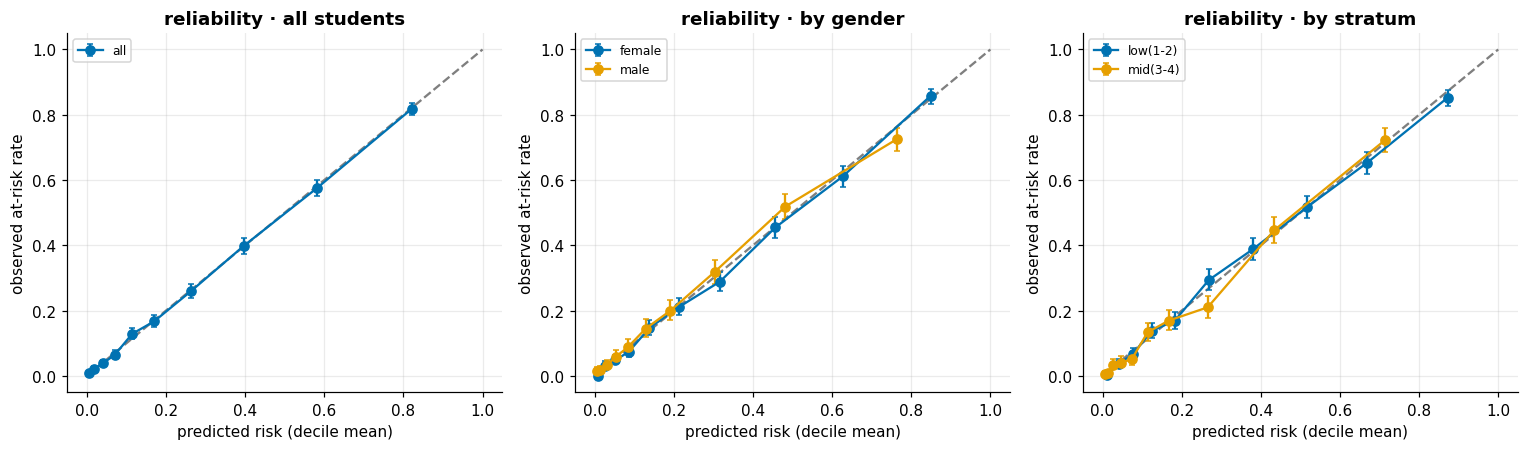

[   389s] [saber11_ctx] baseline done

=== [saber11_ctx] RQ1 | repeated splits (10), target coverage 0.90 | overall ===
  method      n   cov  cov_sd  size   amb  empty  cov_drop
   class 1600.0 0.899   0.006 1.282 0.282    0.0     0.904
marginal 1600.0 0.900   0.011 1.166 0.166    0.0     0.704

At-risk (dropout) coverage and ambiguous-set rate by subgroup:
                                 n  cov_drop_marginal  cov_drop_class  cov_drop_group_cond  cov_drop_group_class_cond  amb_marginal  amb_class  amb_group_cond  amb_group_class_cond
attr        group                                                                                                                                                                   
area        rural            174.9              0.802           0.949                0.851                      0.915         0.226      0.295           0.326                 0.334
            urban           1425.1              0.685           0.895                0.682      

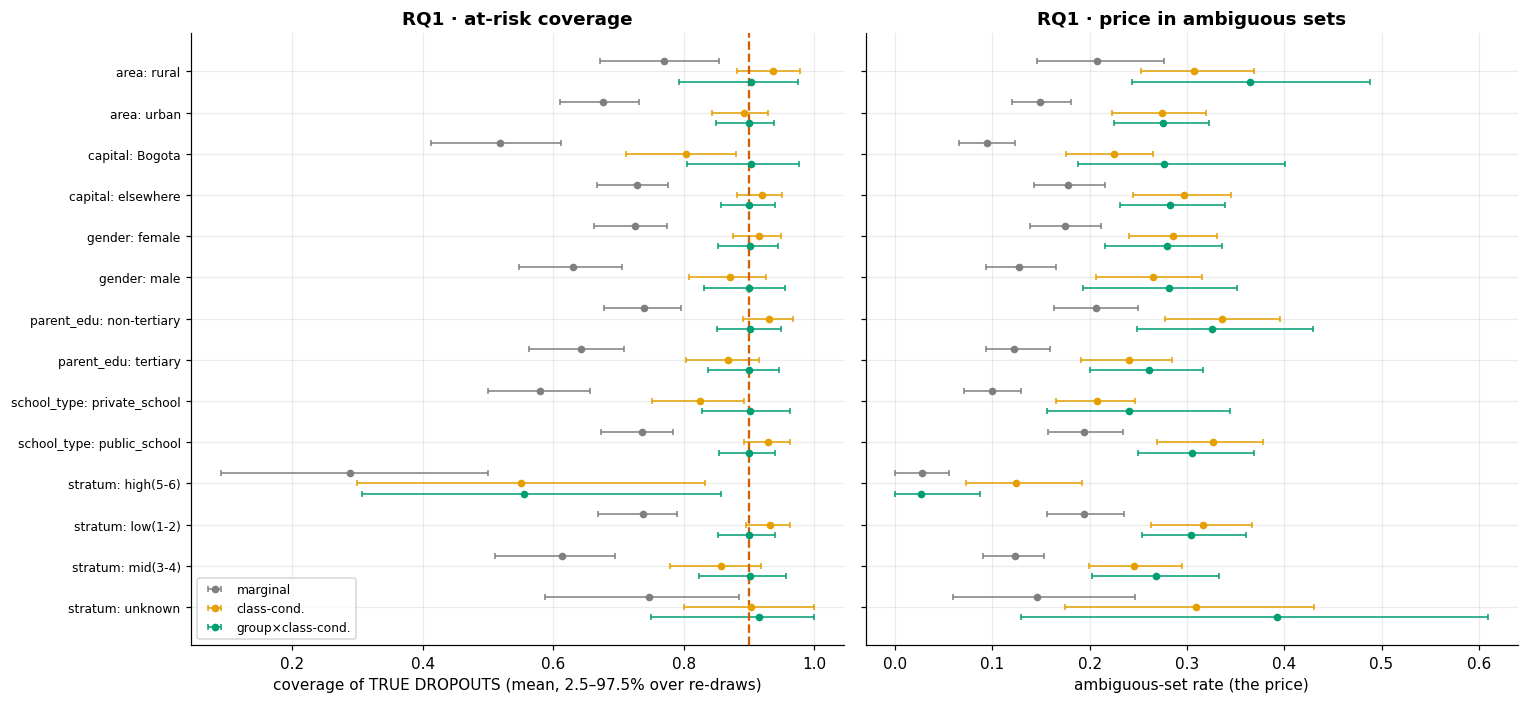

[   442s] [saber11_ctx] RQ1 done
[   442s] [saber11_ctx] RQ2 cross-fitted explanation study (K=5, B=20)

=== [saber11_ctx] RQ2 | students analysed once each: 8000 | ambiguous share (class-conditional sets): 0.287 ===
          jaccard top1_agree rank_instab xmodel_jaccard faith_gap    mag
             mean       mean        mean           mean      mean   mean
ambiguous                                                               
0           0.699      0.543       0.201          0.654      1.08  0.118
1           0.549      0.502       0.237          0.510      0.41  0.099
counts: {0: 5702, 1: 2298}

Spearman / partial Spearman (controls attribution magnitude); Holm over all tests; expect NEGATIVE for jaccard/top1_agree/faith_gap, POSITIVE for rank_instab:
 uncertainty        outcome  spearman      p  partial_ctrl_magnitude  partial_lo  partial_hi  p_holm
   ambiguous        jaccard   -0.4062 0.0000                 -0.3649     -0.3821     -0.3451   0.000
   ambiguous     top1_agree  

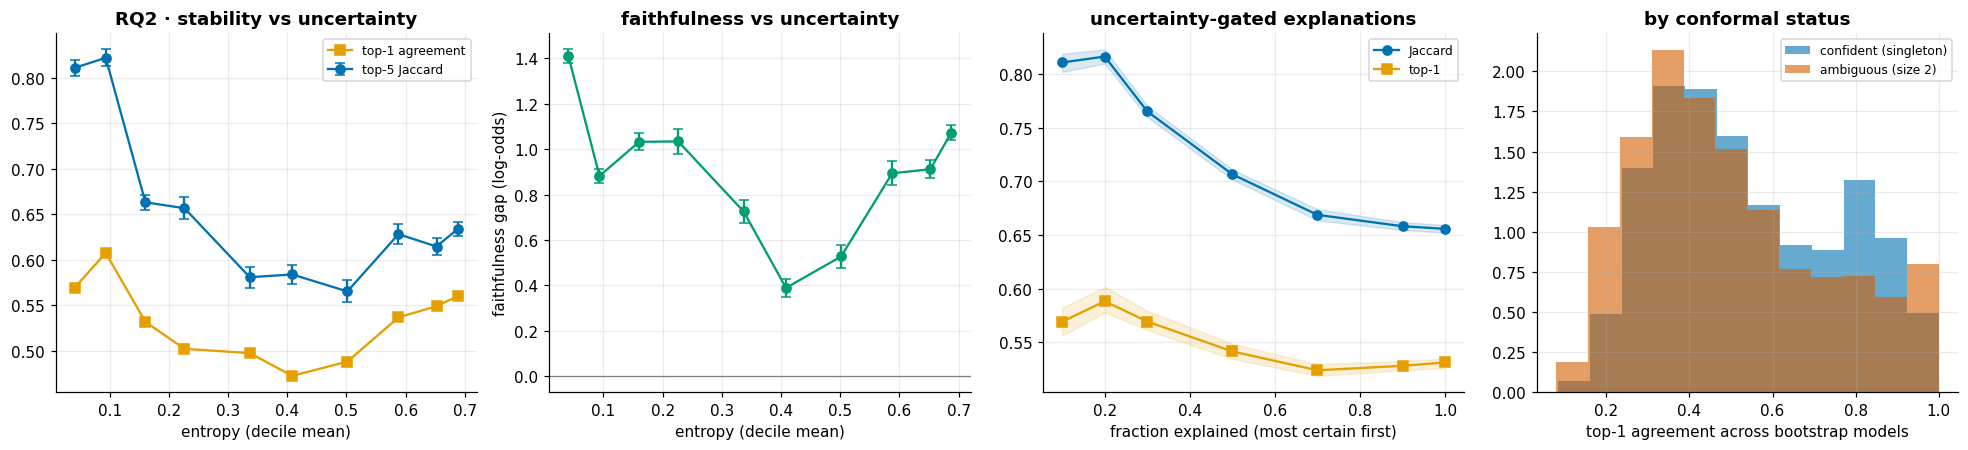


=== [saber11_ctx] Fairness of point predictions (cross-fitted, each student once; gaps = max-min over groups; 95% bootstrap CI; permutation p for TPR gap, Holm-adjusted) ===

threshold = 0.5
            attr           type  min_n                                                                                                                                                                                             tpr_by_group  tpr_gap  tpr_lo  tpr_hi  p_perm_tpr  fpr_gap  fpr_lo  fpr_hi  auc_gap  auc_lo  auc_hi  ece_gap  ece_lo  ece_hi  p_holm_tpr
          gender      protected   3175                                                                                                                                                                         {'female': 0.567, 'male': 0.469}    0.099   0.057   0.145       0.003    0.031   0.016   0.045    0.005   0.000   0.024    0.010   0.000   0.020       0.027
            area      geography    883                                          

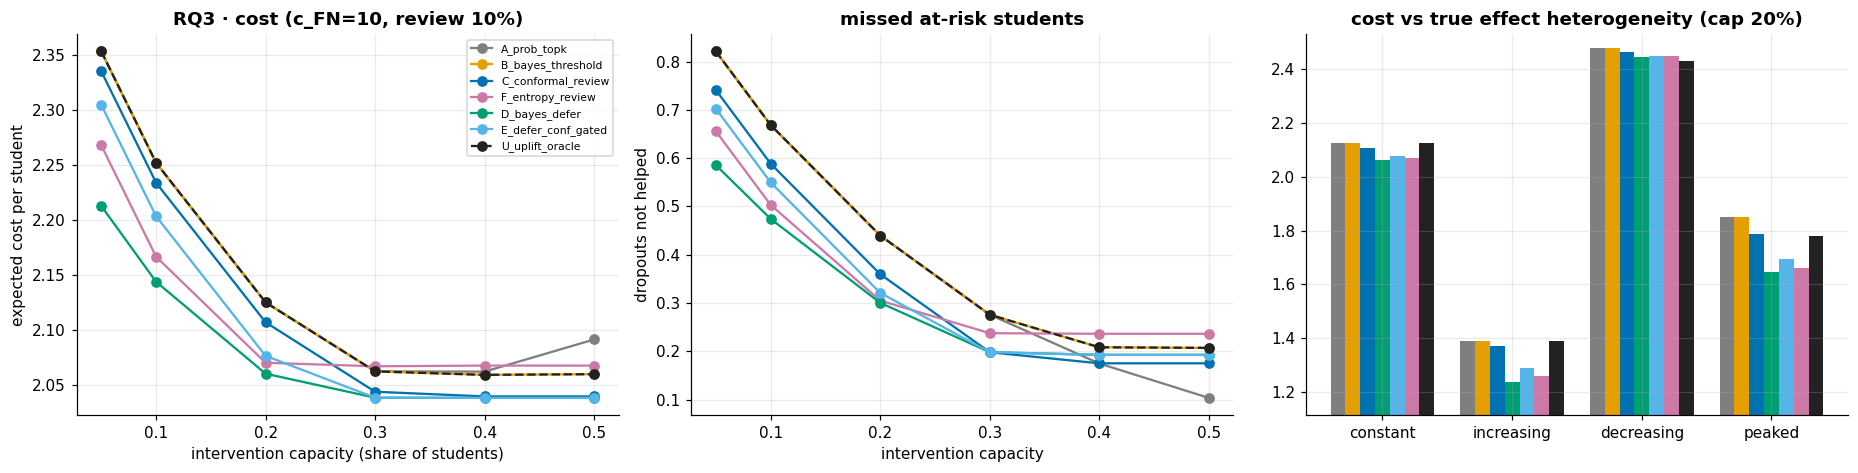

[  1120s] [saber11_ctx] RQ3 done
[  1120s] [saber11_ctx] RQ4 causal adjustment

=== [saber11_ctx] RQ4 | global SHAP importance (out-of-fold), top 20 ===
                          mean_abs_shap  tier  direction(corr x~phi)
punt_c_naturales                 0.4808     1                  -0.98
punt_matematicas                 0.3914     1                  -0.92
punt_sociales_ciudadanas         0.3451     1                  -0.97
punt_ingles                      0.3056     1                  -0.95
punt_lectura_critica             0.2617     1                  -0.96
cohort                           0.1206     0                   0.65
cole_depto_ubicacion             0.1016     0                    NaN
estu_depto_reside                0.0912     0                    NaN
inst_nombre_institucion          0.0862     2                    NaN
gruporeferencia                  0.0806     2                    NaN
estu_prgm_academico              0.0751     2                    NaN
fami_trabajolaborma

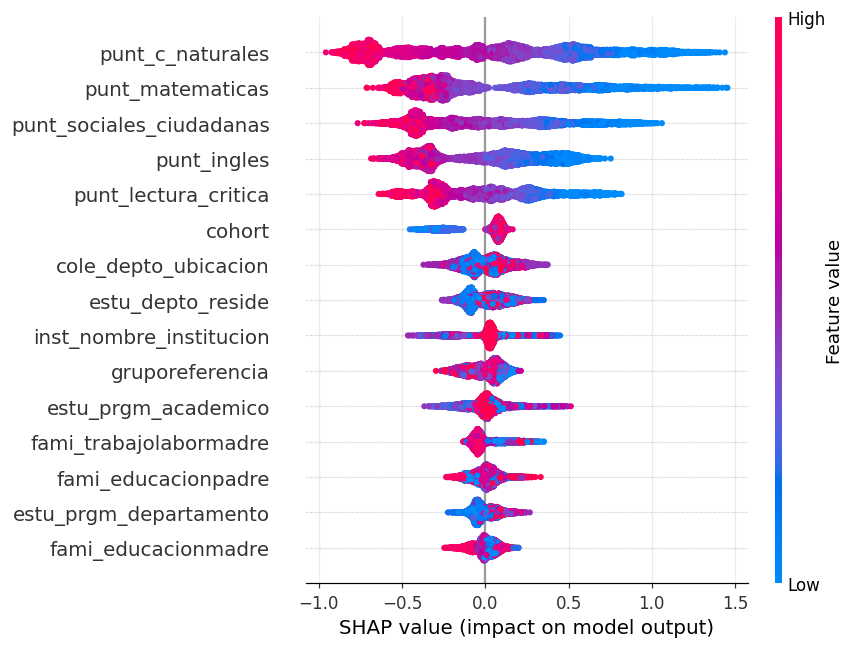

[  1141s]   punt_c_naturales
[  1155s]   punt_matematicas
[  1169s]   punt_sociales_ciudadanas
[  1185s]   punt_ingles
[  1200s]   punt_lectura_critica
[  1204s]   cohort
[  1218s]   noise_negctrl_1
[  1232s]   noise_negctrl_2
[  1246s]   shuffled_punt_c_naturales
[  1260s]   shuffled_punt_matematicas

--- effects on P(dropout): DML risk differences (strict/lenient adjustment), AIPW risk ratio & E-value (CI bound), robustness value, overlap ---
                  feature  tier  shap_rank                              type   naive  strict  strict_lo  strict_hi  lenient  p_holm     RR  E_value_ci     RV  overlap_outside_05_95                         status
         punt_c_naturales     1        1.0                continuous(per SD) -0.2135 -0.2022    -0.2113    -0.1931  -0.0643     0.0 0.1961      8.4226 0.3833                  0.000                         ROBUST
         punt_matematicas     1        2.0                continuous(per SD) -0.2043 -0.1913    -0.2003    -0.1822  -0.0646    

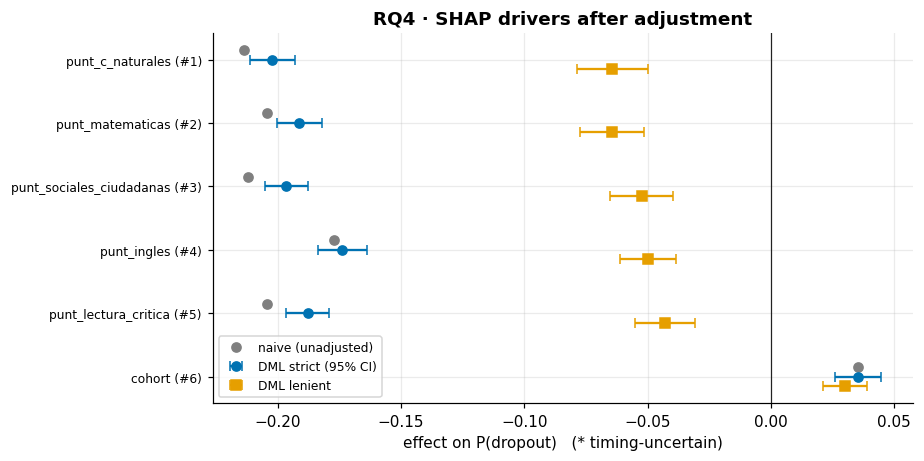

[  1286s] [saber11_ctx] RQ4 done
[  1286s] [saber11_ctx] RQ5 transfer

=== [saber11_ctx] RQ5 | transfer under shift (target 1-alpha = 0.90) ===
scenario                       early_to_late_cohort  leave_institution_out  private_to_public_school  public_to_private_school  urban_to_rural
label_shift                                   0.070                 -0.060                     0.129                    -0.129           0.149
auc_tgt                                       0.859                  0.804                     0.847                     0.876           0.866
cov_indist                                    0.915                  0.901                     0.911                     0.892           0.906
cov_marg                                      0.875                  0.921                     0.859                     0.930           0.878
atrisk_cov_marg                               0.631                  0.370                     0.676                     0.651           0.77

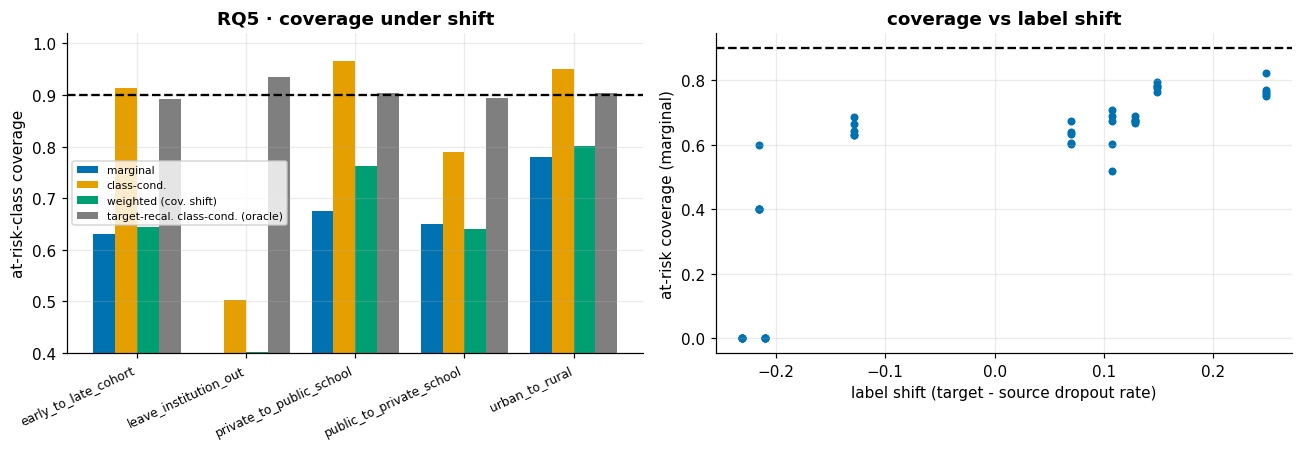

[  1374s] [saber11_ctx] RQ5 done
[  1374s] [saber11_ctx] model-family comparison: 16 families x 5 splits (triage + explanation agreement: True)
[  1810s]    split 1/5 done
[  2254s]    split 2/5 done
[  2633s]    split 3/5 done
[  2988s]    split 4/5 done
[  3342s]    split 5/5 done

=== [saber11_ctx] MODEL FAMILIES — discrimination & calibration (mean ± sd over 5 splits; all probabilities isotonic-calibrated) ===
                        group  auc_mean  auc_std  ap_mean  f1_mean  brier_mean  logloss_mean  ece_raw_mean  ece_cal_mean  mean_rank_auc  seconds_mean
model                                                                                                                                                
DecisionTree             Tree     0.839    0.013    0.634    0.619       0.130         0.408         0.031         0.025           16.0         1.014
KNN                  Instance     0.868    0.008    0.704    0.649       0.120         0.380         0.047         0.026            

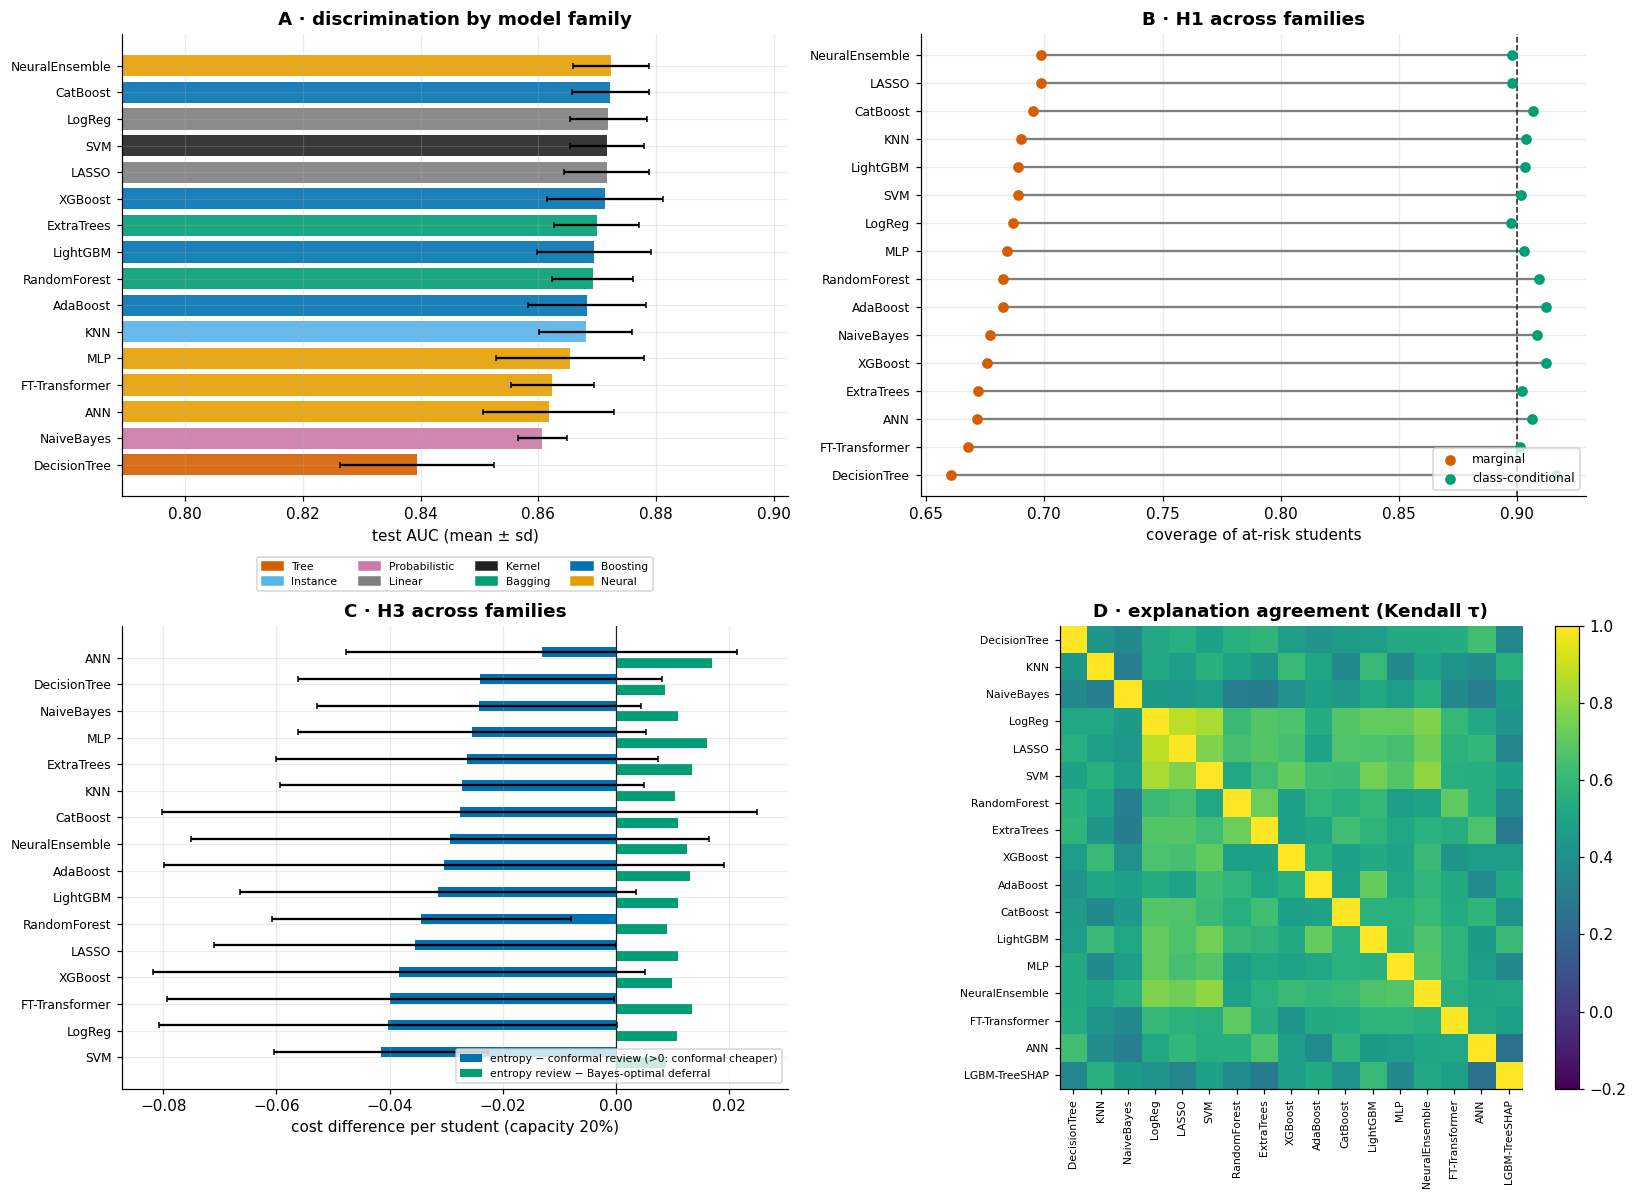

[  3350s] [saber11_ctx] model-family comparison done (32.9 min)

CONFIGURATION: saber11 | level=full | features=19 | dropped=[]
[saber11] 10 runs | train/cal/test = 4800/1600/1600 | features=19 | mean test AUC lgbm=0.870 logreg=0.869

=== [saber11] Model families (train+cal fit, 5 splits; isotonic-calibrated) ===
         auc_mean  auc_std  ap_mean  ap_std  f1_mean  f1_std  brier_mean  brier_std  logloss_mean  logloss_std  ece_raw_mean  ece_raw_std  ece_cal_mean  ece_cal_std
model                                                                                                                                                               
lgbm        0.871    0.008    0.705   0.029    0.610   0.018       0.119      0.005         0.376        0.014         0.026        0.008         0.025        0.006
logreg      0.872    0.006    0.709   0.024    0.621   0.024       0.119      0.004         0.375        0.009         0.022        0.003         0.023        0.004
mlp_ens     0.873    0.00

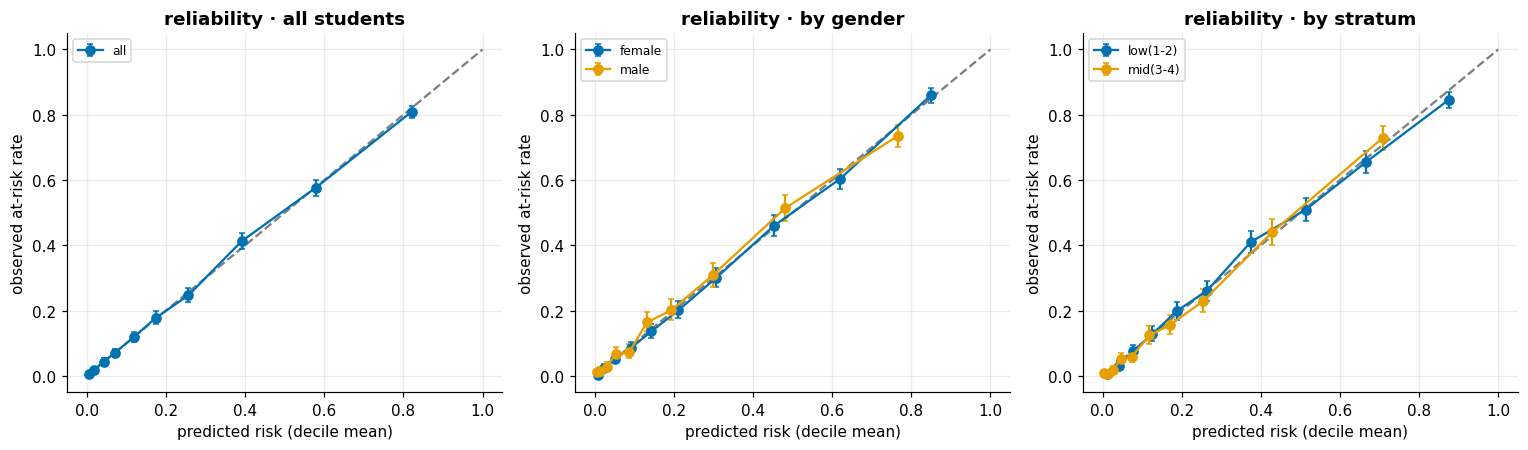

[  3569s] [saber11] baseline done

=== [saber11] RQ1 | repeated splits (10), target coverage 0.90 | overall ===
  method      n   cov  cov_sd  size   amb  empty  cov_drop
   class 1600.0 0.901   0.006 1.286 0.286    0.0     0.908
marginal 1600.0 0.900   0.012 1.160 0.160    0.0     0.687

At-risk (dropout) coverage and ambiguous-set rate by subgroup:
                                 n  cov_drop_marginal  cov_drop_class  cov_drop_group_cond  cov_drop_group_class_cond  amb_marginal  amb_class  amb_group_cond  amb_group_class_cond
attr        group                                                                                                                                                                   
area        rural            174.9              0.787           0.957                0.859                      0.922         0.217      0.315           0.335                 0.351
            urban           1425.1              0.667           0.899                0.660              

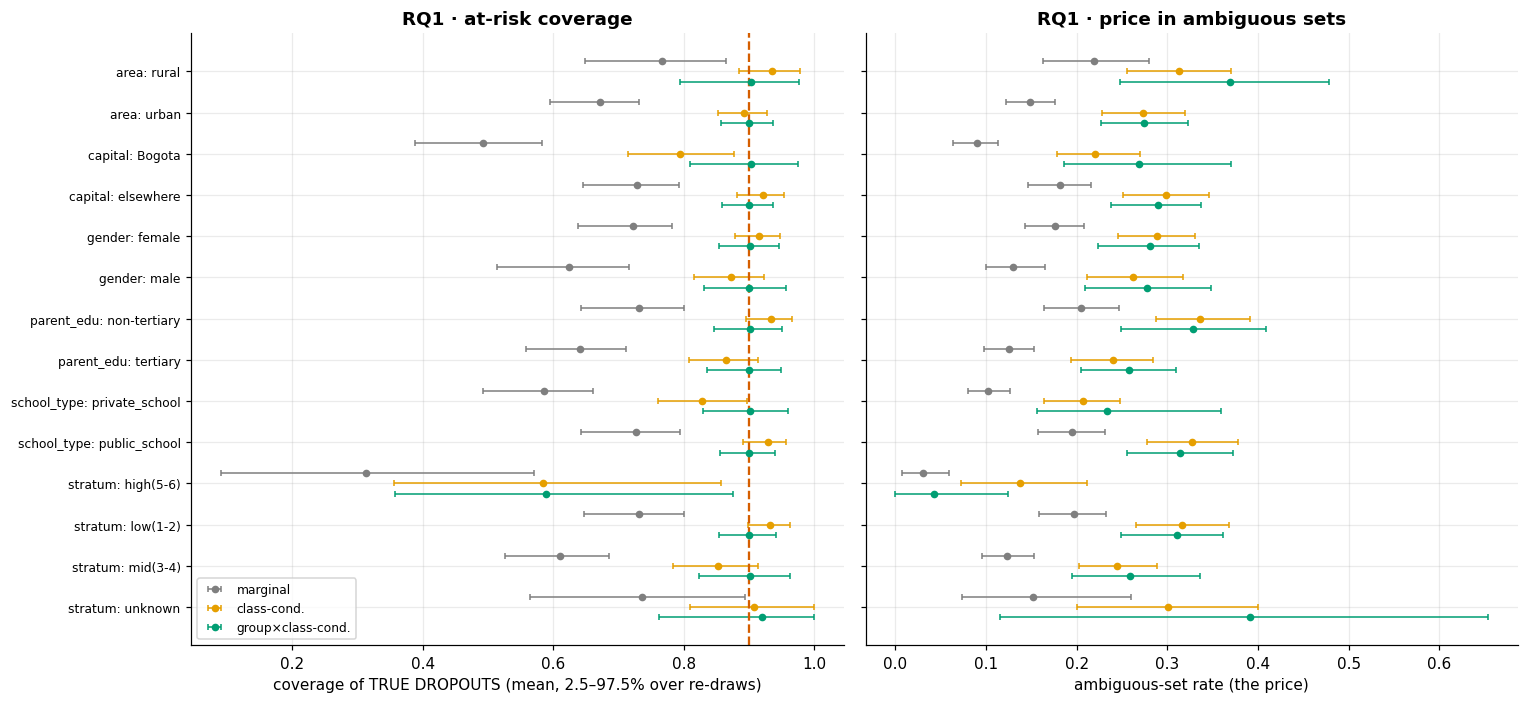

[  3619s] [saber11] RQ1 done
[  3619s] [saber11] RQ2 cross-fitted explanation study (K=5, B=20)

=== [saber11] RQ2 | students analysed once each: 8000 | ambiguous share (class-conditional sets): 0.282 ===
          jaccard top1_agree rank_instab xmodel_jaccard faith_gap    mag
             mean       mean        mean           mean      mean   mean
ambiguous                                                               
0           0.719      0.550       0.181          0.722     1.091  0.150
1           0.581      0.504       0.225          0.572     0.344  0.119
counts: {0: 5742, 1: 2258}

Spearman / partial Spearman (controls attribution magnitude); Holm over all tests; expect NEGATIVE for jaccard/top1_agree/faith_gap, POSITIVE for rank_instab:
 uncertainty        outcome  spearman      p  partial_ctrl_magnitude  partial_lo  partial_hi  p_holm
   ambiguous        jaccard   -0.3886 0.0000                 -0.3187     -0.3389     -0.2985  0.0000
   ambiguous     top1_agree   -0.1007 0.0

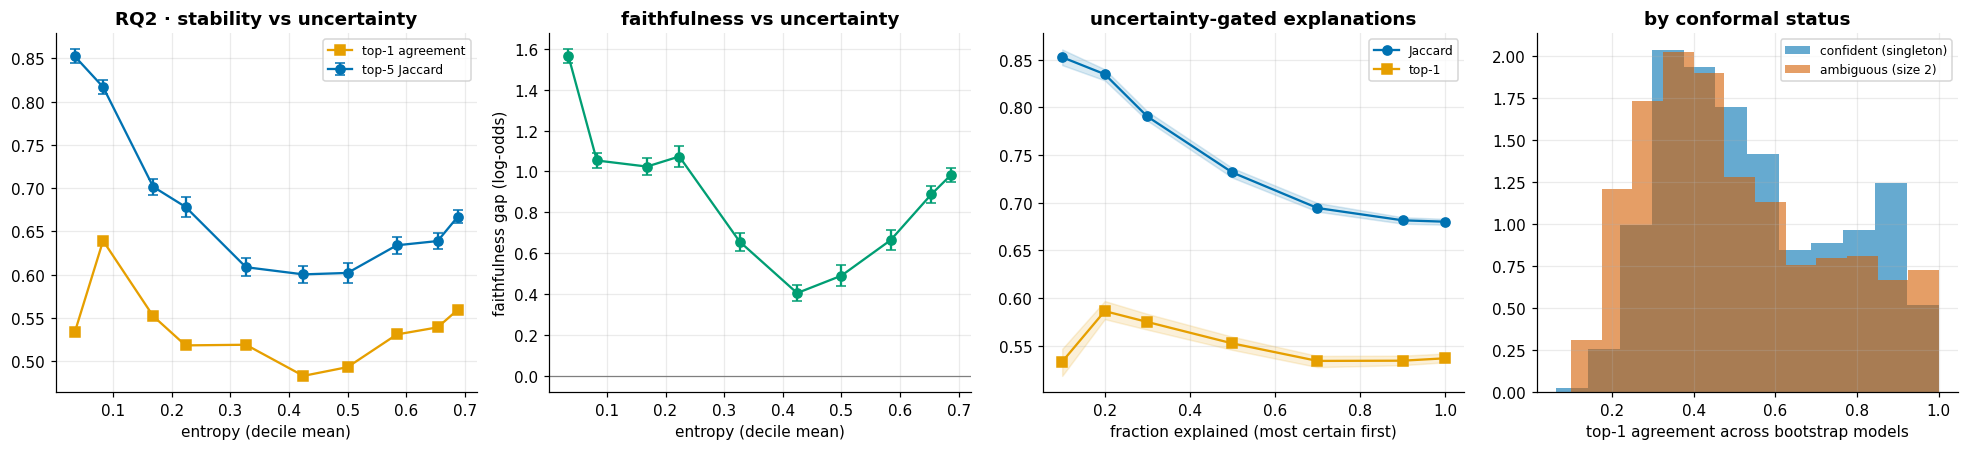


=== [saber11] Fairness of point predictions (cross-fitted, each student once; gaps = max-min over groups; 95% bootstrap CI; permutation p for TPR gap, Holm-adjusted) ===

threshold = 0.5
            attr           type  min_n                                                                                                                                                                                             tpr_by_group  tpr_gap  tpr_lo  tpr_hi  p_perm_tpr  fpr_gap  fpr_lo  fpr_hi  auc_gap  auc_lo  auc_hi  ece_gap  ece_lo  ece_hi  p_holm_tpr
          gender      protected   3175                                                                                                                                                                         {'female': 0.556, 'male': 0.452}    0.104   0.063   0.150       0.003    0.029   0.015   0.043    0.006   0.000   0.024    0.010   0.000   0.018       0.027
            area      geography    883                                              

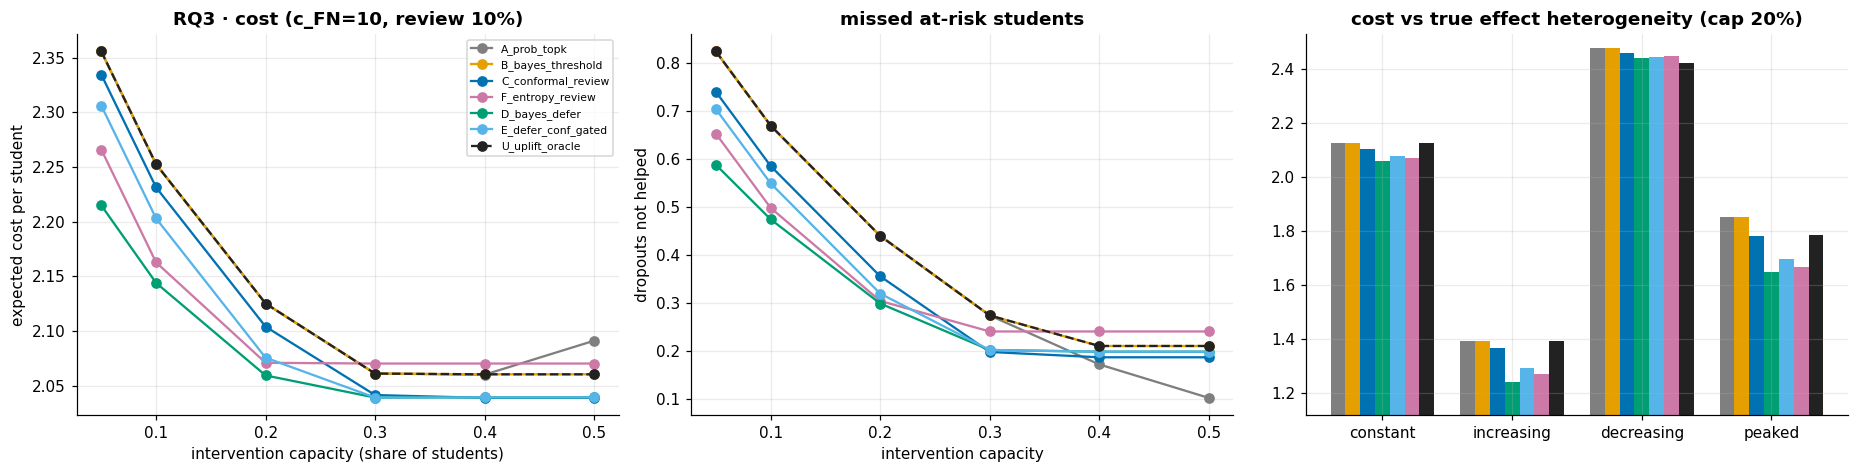

[  4299s] [saber11] RQ3 done
[  4299s] [saber11] RQ4 causal adjustment

=== [saber11] RQ4 | global SHAP importance (out-of-fold), top 20 ===
                          mean_abs_shap  tier  direction(corr x~phi)
punt_c_naturales                 0.5230     1                  -0.98
punt_matematicas                 0.3934     1                  -0.94
punt_sociales_ciudadanas         0.3515     1                  -0.97
punt_ingles                      0.3144     1                  -0.96
punt_lectura_critica             0.2682     1                  -0.96
cohort                           0.1641     0                   0.54
estu_depto_reside                0.1179     0                    NaN
cole_depto_ubicacion             0.1152     0                    NaN
fami_trabajolabormadre           0.0816     0                    NaN
fami_educacionpadre              0.0668     0                    NaN
fami_trabajolaborpadre           0.0574     0                    NaN
fami_educacionmadre            

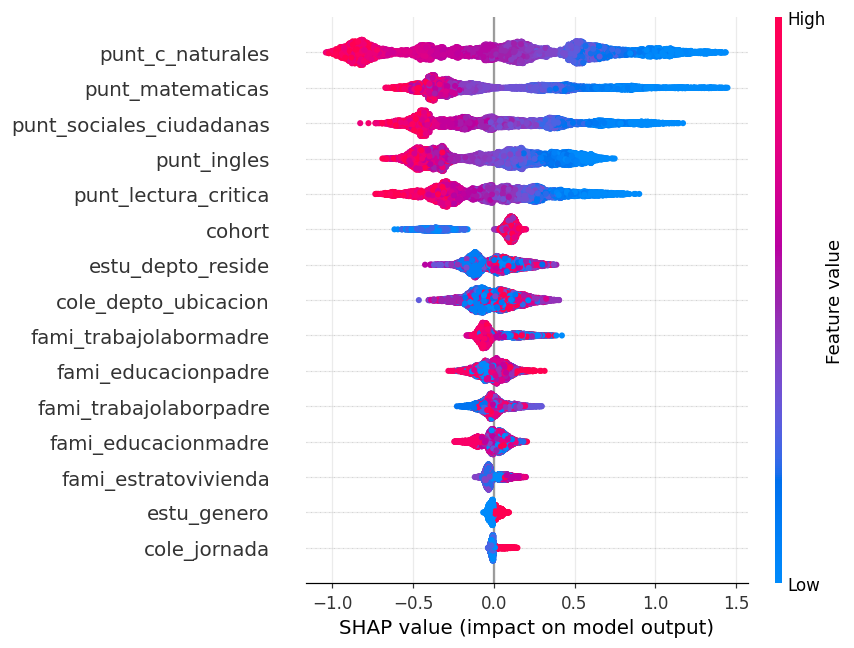

[  4321s]   punt_c_naturales
[  4334s]   punt_matematicas
[  4348s]   punt_sociales_ciudadanas
[  4362s]   punt_ingles
[  4376s]   punt_lectura_critica
[  4381s]   cohort
[  4395s]   noise_negctrl_1
[  4408s]   noise_negctrl_2
[  4423s]   shuffled_punt_c_naturales
[  4439s]   shuffled_punt_matematicas

--- effects on P(dropout): DML risk differences (strict/lenient adjustment), AIPW risk ratio & E-value (CI bound), robustness value, overlap ---
                  feature  tier  shap_rank                              type   naive  strict  strict_lo  strict_hi  lenient  p_holm     RR  E_value_ci     RV  overlap_outside_05_95                         status
         punt_c_naturales     1        1.0                continuous(per SD) -0.2135 -0.2022    -0.2113    -0.1931  -0.0643     0.0 0.1961      8.4226 0.3833                  0.000                         ROBUST
         punt_matematicas     1        2.0                continuous(per SD) -0.2043 -0.1913    -0.2003    -0.1822  -0.0646    

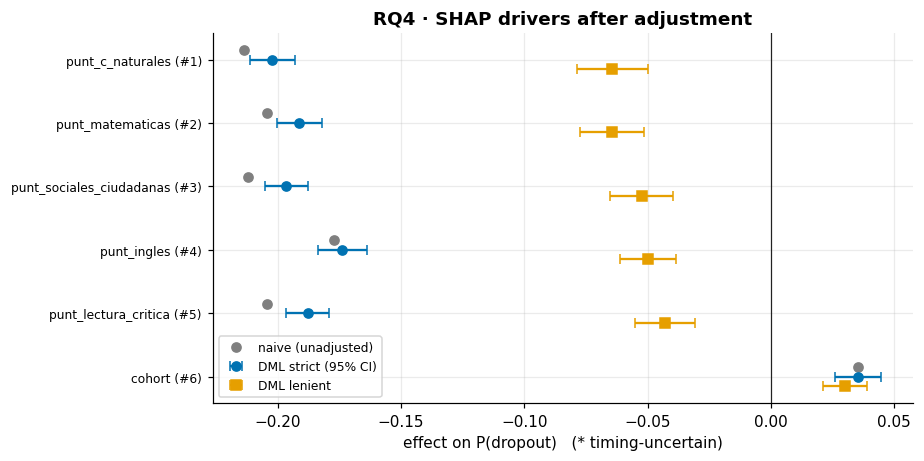

[  4448s] [saber11] RQ4 done
[  4448s] [saber11] RQ5 transfer

=== [saber11] RQ5 | transfer under shift (target 1-alpha = 0.90) ===
scenario                       early_to_late_cohort  leave_institution_out  private_to_public_school  public_to_private_school  urban_to_rural
label_shift                                   0.070                 -0.060                     0.129                    -0.129           0.149
auc_tgt                                       0.859                  0.823                     0.848                     0.878           0.866
cov_indist                                    0.913                  0.900                     0.901                     0.895           0.904
cov_marg                                      0.873                  0.923                     0.861                     0.931           0.878
atrisk_cov_marg                               0.638                  0.391                     0.666                     0.653           0.769
cov_class 

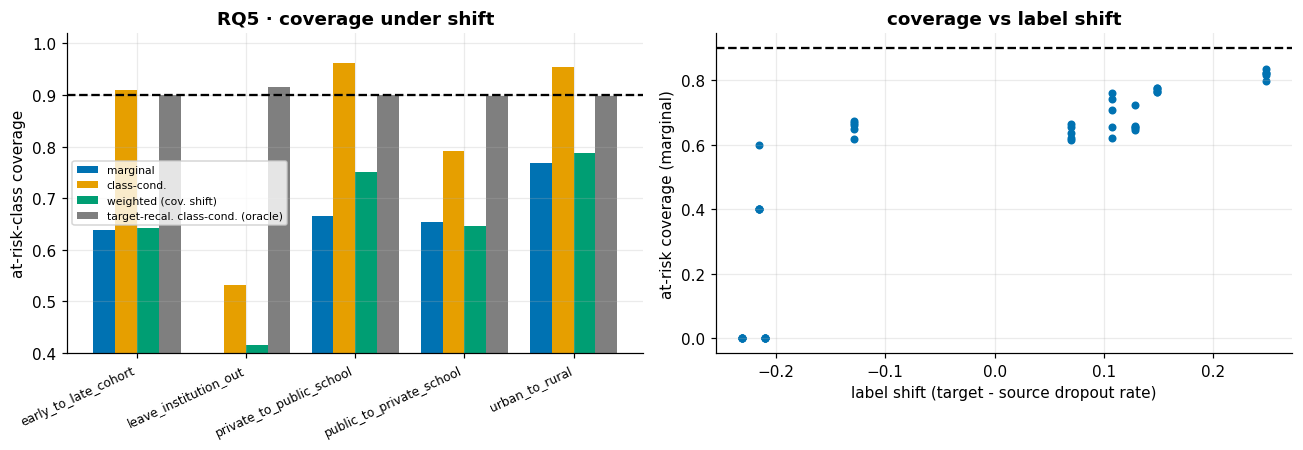

[  4526s] [saber11] RQ5 done

CONFIGURATION: saber11_no_ses | level=core | features=14 | dropped=['fami_educacionmadre', 'fami_educacionpadre', 'fami_estratovivienda', 'fami_trabajolabormadre', 'fami_trabajolaborpadre']
[saber11_no_ses] 10 runs | train/cal/test = 4800/1600/1600 | features=14 | mean test AUC lgbm=0.870 logreg=0.871

=== [saber11_no_ses] Model families (train+cal fit, 5 splits; isotonic-calibrated) ===
        auc_mean  auc_std  ap_mean  ap_std  f1_mean  f1_std  brier_mean  brier_std  logloss_mean  logloss_std  ece_raw_mean  ece_raw_std  ece_cal_mean  ece_cal_std
model                                                                                                                                                              
lgbm       0.871    0.010    0.705   0.029    0.611   0.027       0.120      0.005         0.378        0.015         0.023        0.006         0.024        0.004
logreg     0.872    0.008    0.711   0.024    0.627   0.021       0.119      0.005     

In [ ]:
import json, zipfile, traceback
ALL = {}

def safe(fn, ctx):
    try:
        fn(ctx)
    except Exception as ex:
        print(f'!! {fn.__name__} failed for {ctx.name}: {type(ex).__name__}: {ex}')
        traceback.print_exc(limit=3)
        ctx.S.setdefault('errors', []).append(f'{fn.__name__}: {ex}')
print(f'DATASET = {DATASET} | outcome: {LABEL_DESC} | signal ok: {SIGNAL_OK}')
for scenario, drops, level in PLAN:
    ctx = build_ctx(scenario, drops, level)
    print('\n' + '=' * 100 + f'\nCONFIGURATION: {ctx.name} | level={level} | features={len(ctx.cols)} | dropped={ctx.dropped}\n' + '=' * 100)
    if not SIGNAL_OK and (not CFG['force_full']):
        print('>>> NO-SIGNAL MODE: running only model-performance baselines and the conformal validity analysis (these remain meaningful as a null-model reference); explanation/triage/causal/transfer analyses are skipped.')
        level = ctx.level = 'core'
        stages = [a_baseline, a_rq1]
    else:
        stages = None
    build_runs(ctx)
    stages = stages or [a_baseline, a_rq1, a_rq2, a_fairness] + ([a_synth, a_rq3, a_rq4, a_rq5] if level == 'full' else [])
    if CFG['run_families'] and (len(ALL) == 0 or CFG['families_all_configs']):
        stages = stages + [a_families]
    for st in stages:
        safe(st, ctx)
    ctx.S['replication'] = replication_metrics(ctx)
    ALL[ctx.name] = ctx
    json_name = f'replication_{ctx.name}.json'
    with open(os.path.join(ctx.dir, json_name), 'w') as f:
        json.dump(ctx.S['replication'], f, default=float)
    if len(ALL) == 1:
        json.dump(dict(ctx.S['replication'], signal_ok=bool(SIGNAL_OK)), open(os.path.join(CFG['out_root'], 'replication_primary.json'), 'w'), default=float)

## 7. Pre-registered hypotheses — automatic verdicts and cross-configuration sensitivity

In [ ]:
rows = []
for nm, c in ALL.items():
    S = c.S
    h1, h2, h3 = (S.get('H1', {}), S.get('H2', {}), S.get('H3', {}))
    rows.append(dict(config=nm, level=c.level, signal_ok=SIGNAL_OK, AUC=S.get('baseline', {}).get('lgbm', {}).get('auc'), amb_class=h1.get('amb_class'), marg_atrisk_cov=h1.get('marginal_atrisk_cov'), H1a_marginal_undercovers=h1.get('marginal_atrisk_hi', 1) < 1 - CFG['alpha'] - 0.0 if h1 else None, H1b_repaired=h1.get('repaired'), H1b_smallcell_repaired=h1.get('repaired_smallcell'), H2_partial_rho=h2.get('partial_entropy_top1'), H2_supported=h2.get('hi', 1) < 0 if h2 else None, H3_diff_F_minus_C=h3.get('diff'), H3_supported=h3.get('supported'), n_robust_drivers=S.get('rq4', {}).get('status_counts_by_E', {}).get(str(CFG['evalue_min']), {}).get('ROBUST'), errors=len(S.get('errors', []))))
V = pd.DataFrame(rows)
print('=== Hypothesis verdicts per configuration ===')
print(V.round(3).to_string(index=False))
tocsv(V, 'verdicts.csv', index=False)
if not SIGNAL_OK:
    print('\n>>> NO-SIGNAL DATASET: the H1 columns above describe a near-uninformative model (most prediction sets are ambiguous). They are NOT evidence for H1 and should not be reported as a replication; the useful finding is the audit itself.')
print('\nReading guide: H1a = marginal conformal credibly under-covers the at-risk class; H2 = explanation stability falls with entropy beyond attribution magnitude (CI<0); H3 = conformal review is NOT significantly cheaper than entropy review (True means the novelty claim for conformal gating is NOT supported).')

def clean(o):
    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, (np.floating, float)):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.bool_,)):
        return bool(o)
    return o
SUMMARY['config'] = clean(dict(CFG))
SUMMARY['plan'] = [list(map(str, p)) for p in PLAN]
SUMMARY['runs'] = {nm: clean(c.S) for nm, c in ALL.items()}
sj = os.path.join(CFG['out_root'], 'SUMMARY.json')
json.dump(clean(SUMMARY), open(sj, 'w'), indent=1)
print('summary ->', sj, f'({os.path.getsize(sj) / 1000.0:.0f} kB)  <-- paste this file (or its contents) back to me')

=== Hypothesis verdicts per configuration ===
        config level  signal_ok   AUC  amb_class  marg_atrisk_cov  H1a_marginal_undercovers  H1b_repaired  H1b_smallcell_repaired  H2_partial_rho  H2_supported  H3_diff_F_minus_C H3_supported  n_robust_drivers  errors
   saber11_ctx  full       True 0.870      0.278            0.692                      True          True                   False          -0.030          True             -0.037         True               5.0       0
       saber11  full       True 0.871      0.278            0.688                      True          True                   False          -0.048          True             -0.033         True               5.0       0
saber11_no_ses  core       True 0.871      0.275            0.674                      True          True                   False           0.008         False                NaN         None               NaN       0

Reading guide: H1a = marginal conformal credibly under-covers the at-risk class; 

## 8. Package results

In [ ]:
zp = os.path.join(os.path.dirname(CFG['out_root'].rstrip('/')) or '.', os.path.basename(CFG['out_root'].rstrip('/')) + '.zip')
with zipfile.ZipFile(zp, 'w', zipfile.ZIP_DEFLATED) as z:
    for root, _, fs in os.walk(CFG['out_root']):
        for f in fs:
            z.write(os.path.join(root, f), os.path.relpath(os.path.join(root, f), CFG['out_root']))
print('zip ->', zp, f'({os.path.getsize(zp) / 1000000.0:.1f} MB)  total runtime {(time.time() - t0) / 60:.1f} min')
try:
    from google.colab import files
    files.download(zp)
except Exception:
    pass

zip -> /content/results_colombia_v4.zip (17.0 MB)  total runtime 81.8 min


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Cross-dataset replication (RQ5, second part)
Run this notebook once per dataset (`DATASET = 'uci'`, `'bangladesh'`, `'colombia'`). Each run writes `replication_primary.json`. If more than one dataset's results are present in `/content/results_*_v4/`, this cell
combines the dataset-level effects with a DerSimonian–Laird random-effects meta-analysis (pooled effect, 95% CI, I²). With only 2–3 datasets the heterogeneity estimate is very imprecise — read I² as descriptive.
Datasets flagged `signal_ok = False` are excluded from the pooling (their effects are undefined).

In [ ]:
import glob
paths = sorted(glob.glob(os.path.join(os.path.dirname(CFG['out_root'].rstrip('/')) or '.', 'results_*_v4', 'replication_primary.json')))
reps = [json.load(open(p)) for p in paths]
print('replication files found:', [(r.get('dataset'), r.get('signal_ok')) for r in reps])
use = [p for p, r in zip(paths, reps) if r.get('signal_ok', True)]
if len(use) >= 2:
    M = meta_analyze(use)
    print(M.round(3).to_string())
    M.to_csv(os.path.join(CFG['out_root'], 'meta_analysis.csv'))
else:
    print('Need >= 2 datasets with usable signal for pooling; run the notebook for the other datasets (same Colab session keeps /content/results_*).')

replication files found: [('colombia', True)]
Need >= 2 datasets with usable signal for pooling; run the notebook for the other datasets (same Colab session keeps /content/results_*).
